# TP 2 — Comparer ML et deep learning sur Tiny Shakespeare

Que gagnent les embeddings et l’ordre des mots face à TF–IDF sur ces répliques, et quelles conclusions mes comparaisons permettent-elles réellement ? Je garde la tâche du TP1 pour suivre ce qui change avec la représentation et le classifieur.

| Étape | Section | Question |
|---|---|---|
| Nettoyage et prétraitement | 1 | Quels textes chaque modèle reçoit-il ? |
| Représentation | 2 | Que garde ou perd chaque représentation ? |
| Comparaison ML / DL | 3 | Les réseaux rejoignent-ils la référence lexicale ? |
| Évaluation | 4 | Quels résultats résistent aux comparaisons et quelles limites restent ouvertes ? |

## 0. Mon problème et les acquis du TP1

Je prédis l’étiquette de locuteur d’une réplique à partir de son texte seul, parmi dix classes. Je conserve le sous-corpus du TP1 pour comparer les méthodes sur les mêmes exemples.

| Résultat du TP1 | Question pour ce carnet |
|---|---|
| 962 répliques, de 78 à 129 par classe | Comment les réseaux ajustent-ils ce petit jeu ? |
| Neuf confusions JULIET–ROMEO et sept de GLOUCESTER vers DUKE VINCENTIO sur le test | Quels indices accompagnent ces erreurs ? |
| Coefficients élevés pour `kate` (2,645), `romeo` (1,623), `paulina` (1,447) et `camillo` (1,211) | Que change le retrait des noms détectés ? |
| LinearSVC obtient 0,482 ± 0,035 en validation croisée et 0,563 sur le test | Les réseaux rejoignent-ils cette référence ? |

Ces coefficients motivent une piste, sans expliquer seuls une prédiction. Le test a déjà été consulté au TP1 et ses erreurs ont guidé mes questions. Je conserverai cette limite jusque dans la conclusion.

> *Mes hypothèses :*
>
> - H1, indices lexicaux. Un MLP sur la moyenne des embeddings reste à moins de 0,05 de F1 macro de TF–IDF + LinearSVC, car les deux ignorent l’ordre des mots.
> - H2, ordre des mots. LSTM et GRU ne dépassent le MLP que si l’ordre porte un signal, donc mélanger les mots doit les dégrader mais pas le MLP.
> - H3, mémorisation. Sans régularisation, un réseau atteint un F1 macro train proche de 1 en moins de 20 epochs, avec un écart train/validation supérieur à 0,3.
> - H4, coût. À largeur égale, le GRU a moins de paramètres et s’entraîne plus vite que le LSTM pour un F1 macro comparable.

Je garde ces hypothèses de départ pour pouvoir revenir sur leur raisonnement. Je compare les scores moyens, leur dispersion et les temps mesurés avant l’évaluation des configurations retenues sur le test déjà connu.

### Mon environnement

J’utilise le kernel `.venv/bin/python` et les versions fixées dans `requirements.txt`. L’installation se fait dans le terminal :

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

Je conserve le CPU retenu pour ces expériences. La section 3.1 vérifiera la répétition de deux petits entraînements dans cet environnement, sans en déduire une garantie sur d’autres machines.

La seed est la graine qui initialise un générateur aléatoire. Je garde 42 pour les données et les modèles ML, puis 42, 43 et 44 pour les réseaux. Ces répétitions font varier l’initialisation et l’ordre des batches, pas seulement les poids de départ.

In [1]:
# Environnement : versions, matériel, device PyTorch et seed unique pour random, numpy et torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import numpy as np
import torch

# Seed fixée ici ; la fonction de la section 3.1 la réinitialisera avant chaque entraînement.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# CPU, pour des entraînements reproductibles à seed égale
device = torch.device('cpu')

# Versions et dépendances
print(f'Python : {platform.python_version()} — {sys.executable}')
for paquet in ('numpy', 'pandas', 'matplotlib', 'scikit-learn', 'ipykernel', 'torch'):
    print(f'{paquet} : {version(paquet)}')

# Système et processeur
print(f'Système : {platform.platform()} — {platform.machine()}')
if sys.platform == 'darwin':
    processeur, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processeur : {processeur} — RAM : {int(ram) / 2**30:g} Gio')

print(f'Device : {device} — Seed : {RANDOM_STATE}')


Python : 3.14.7 — /Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python
numpy : 2.5.3
pandas : 3.0.5
matplotlib : 3.11.1
scikit-learn : 1.9.0
ipykernel : 7.3.0
torch : 2.14.0
Système : macOS-26.5-arm64-arm-64bit-Mach-O — arm64
Processeur : Apple M3 Max — RAM : 36 Gio
Device : cpu — Seed : 42


## 1. Nettoyage et prétraitement

### 1.1 Retrouver les mêmes répliques

Je reprends le parseur du TP1 pour conserver la définition de la tâche. Il garde les blocs dont la première ligne correspond au motif d’un locuteur et qui contiennent une réplique. Il retire cette première ligne de l’entrée, mais conserve le texte suivant, sa ponctuation et ses majuscules.

Le locuteur fourni par le corpus est la cible supervisée. Les blocs non reconnus sont ignorés et une étiquette peut réunir plusieurs personnages homonymes.

In [2]:
# Corpus : téléchargement de Tiny Shakespeare et parser du TP1 (bloc = étiquette + réplique).
import re
import urllib.request

import pandas as pd
from IPython.display import display

URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

# Téléchargement du texte brut
with urllib.request.urlopen(URL, timeout=30) as reponse:
    texte = reponse.read().decode('utf-8')


def parser_repliques(txt: str) -> pd.DataFrame:
    """Reprend les règles du TP1 : un bloc, une étiquette et sa réplique."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])  # Nom en majuscules puis « : »
        if entete and len(parties) > 1:
            lignes.append({
                'locuteur': entete.group(1).strip(),
                'replique': " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)


In [3]:
# Jeu retenu : répliques d'au moins 10 mots, puis les 10 locuteurs les plus fréquents, comme au TP1.
seuil, nb_locuteurs = 10, 10

# Le seuil de longueur s'applique avant de compter les locuteurs.
longueurs = df['replique'].str.split().str.len()
locuteurs = df.loc[longueurs >= seuil, 'locuteur'].value_counts().head(nb_locuteurs).index

donnees = df.loc[
    (longueurs >= seuil) & df['locuteur'].isin(locuteurs),
    ['replique', 'locuteur'],
].copy()  # Ordre et indices du TP1 conservés.


In [4]:
# Contrôles du jeu retenu : effectifs, longueurs, valeurs manquantes, doublons.
effectifs = donnees['locuteur'].value_counts()
longueurs_retenues = donnees['replique'].str.split().str.len()

# Comptes globaux
print(f'Extraction : {len(df):,} répliques, {df["locuteur"].nunique()} labels')
print(f'Jeu retenu : {len(donnees)} répliques, {len(effectifs)} classes')
print(f'Longueurs (mots) : min {longueurs_retenues.min()}, '
      f'médiane {longueurs_retenues.median():g}, max {longueurs_retenues.max()}')
print(f'Valeurs manquantes : {donnees.isna().sum().sum()}')
print(f'Répliques vides : {donnees["replique"].str.strip().eq("").sum()}')
print(f'Textes dupliqués dans le jeu retenu : {donnees["replique"].duplicated().sum()}')

# Effectifs par classe et aperçu
display(effectifs.rename('Répliques').to_frame())
display(donnees.head(3))


Extraction : 7,094 répliques, 297 labels
Jeu retenu : 962 répliques, 10 classes
Longueurs (mots) : min 10, médiane 31, max 578
Valeurs manquantes : 0
Répliques vides : 0
Textes dupliqués dans le jeu retenu : 0


,Répliques
locuteur,
GLOUCESTER,129
DUKE VINCENTIO,125
MENENIUS,107
PETRUCHIO,95
ROMEO,94
CORIOLANUS,87
JULIET,85
LEONTES,82
ISABELLA,80


,replique,locuteur
22,"What work's, my countrymen, in hand? where go ...",MENENIUS
24,"Why, masters, my good friends, mine honest nei...",MENENIUS
26,"I tell you, friends, most charitable care Have...",MENENIUS


> *Mes observations :*
>
> Je retrouve 7 094 répliques et 297 étiquettes distinctes, puis 962 répliques dans les dix classes retenues. Je ne relève aucun texte vide, aucune valeur manquante ni aucun doublon exact dans ce sous-corpus.

Le seuil de dix mots et les dix classes prolongent le compromis du TP1. Ils ne garantissent ni l’équilibre ni un gain de score. La médiane de 31 mots et le maximum de 578 motivent l’examen du padding et de la troncature.

### 1.2 Séparer apprentissage, sélection et évaluation

Je conserve le découpage stratifié du TP1, avec la graine 42. Je vérifierai directement les indices, textes et cibles, car retrouver une taille de vocabulaire ne suffirait pas à identifier les mêmes exemples.

In [5]:
# Découpage développement / test du TP1 : 80/20 stratifié, seed 42.
from sklearn.model_selection import StratifiedKFold, train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2, stratify=donnees['locuteur'], random_state=RANDOM_STATE,
)

# Vérifications : aucun indice ni texte partagé entre développement et test.
assert set(X_train.index).isdisjoint(X_test.index)
assert not set(X_train).intersection(X_test)

# Tailles, empreinte du découpage et répartition des classes
print(f'Développement : {len(X_train)} répliques ; test : {len(X_test)}')
print(f'Premiers indices du test : {list(X_test.index[:10])}')
display(pd.DataFrame({
    'Développement': y_train.value_counts(),
    'Test': y_test.value_counts(),
}).sort_values('Développement', ascending=False))


Développement : 769 répliques ; test : 193
Premiers indices du test : [3009, 6783, 5903, 1321, 3338, 2294, 3344, 2875, 3378, 2212]


,Développement,Test
locuteur,,
GLOUCESTER,103,26
DUKE VINCENTIO,100,25
MENENIUS,85,22
PETRUCHIO,76,19
ROMEO,75,19
CORIOLANUS,70,17
JULIET,68,17
LEONTES,66,16
ISABELLA,64,16


Je forme cinq plis stratifiés sur le développement et je conserve leurs indices pour tous les modèles. Les comparaisons portent ainsi sur les mêmes répliques de validation.

| Ensemble | Taille | Rôle |
|---|---|---|
| Entraînement d’un pli | 615 ou 616 | Ajuster vocabulaire, IDF, longueur maximale et paramètres. |
| Validation d’un pli | 154 ou 153 | Comparer les configurations et choisir les epochs. |
| Test déjà consulté au TP1 | 193 | Évaluer les choix figés à la fin du TP2, avec une portée exploratoire. |

Je conserve le choix de ne pas ajouter de validation interne. Les scores des plis serviront aussi à sélectionner les epochs, ce qui limite leur rôle comme estimation indépendante de performance.

In [6]:
# Cinq folds stratifiés sur les 769 répliques de développement, communs aux modèles ML et DL.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Indices d'origine, utilisables avec .loc, plutôt que positions
folds = [
    {'train': X_train.index[positions_train], 'validation': X_train.index[positions_validation]}
    for positions_train, positions_validation in cv.split(X_train, y_train)
]

# Vérification : les dix classes sont présentes dans chaque validation.
assert all(y_train.loc[fold['validation']].nunique() == y_train.nunique() for fold in folds)

display(pd.DataFrame(
    [{nom: len(indices) for nom, indices in fold.items()} for fold in folds],
    index=pd.RangeIndex(1, len(folds) + 1, name='Fold'),
))


,train,validation
Fold,,
1,615,154
2,615,154
3,615,154
4,615,154
5,616,153


Je compare les séries complètes et leur ordre aux empreintes enregistrées lors de l’exécution du TP1. Chaque empreinte de série inclut les indices et les textes ou étiquettes. Les plis sont comparés par leurs positions dans ces séries.

In [7]:
# Je vérifie les séries et les plis face aux empreintes de la référence TP1 exécutée.
import hashlib
import json

EMPREINTES_TP1 = {
    'X_train': 'fa6781386828f5732ccc98fabebe8dd85a87428ac76648f8c227ed72e61d793a',
    'X_test': '4abf425c4a9084bcf927e9679fdd313d1a9590607a9bd1354d288a4ab4b80799',
    'y_train': 'ac3369279023ea48589d6b3251e8c29c29fd9223d74d94694fe71390a9f6d541',
    'y_test': 'decc7f964fff98c8d45e96bc024f6b039f7b73bc985ea20ee285ba9778f975db',
    'plis': 'ca8eb4d04e89b6f70d486cab3441924e0650b20a6a6f2d18caaaa0cadb69edf9',
}


def empreinte(valeur: list) -> str:
    """Empreinte des valeurs ordonnées, sérialisées sans modifier les données."""
    return hashlib.sha256(json.dumps(valeur, ensure_ascii=False).encode()).hexdigest()


for nom, serie in (('X_train', X_train), ('X_test', X_test),
                   ('y_train', y_train), ('y_test', y_test)):
    accord = empreinte([list(map(int, serie.index)), serie.tolist()]) == EMPREINTES_TP1[nom]
    print(f'{nom} : indices, ordre et valeurs identiques au TP1 = {accord}')
    assert accord
positions_plis = [[X_train.index.get_indexer(f[nom]).tolist()
                   for nom in ('train', 'validation')] for f in folds]
assert empreinte(positions_plis) == EMPREINTES_TP1['plis']
print('Cinq plis identiques à ceux du TP1.')

X_train : indices, ordre et valeurs identiques au TP1 = True
X_test : indices, ordre et valeurs identiques au TP1 = True
y_train : indices, ordre et valeurs identiques au TP1 = True
y_test : indices, ordre et valeurs identiques au TP1 = True
Cinq plis identiques à ceux du TP1.


> *Mes observations :*
>
> Les ensembles contiennent 769 et 193 répliques et ne partagent aucun indice ni texte exact. Les quatre premiers plis ont 615 exemples d’entraînement et 154 de validation, contre 616 et 153 pour le dernier.

Chaque réplique de développement appartient à une validation par configuration et par graine. Les ensembles d’entraînement des plis se recouvrent. L’absence de doublons exacts ne rend pas les répliques de mêmes scènes indépendantes.

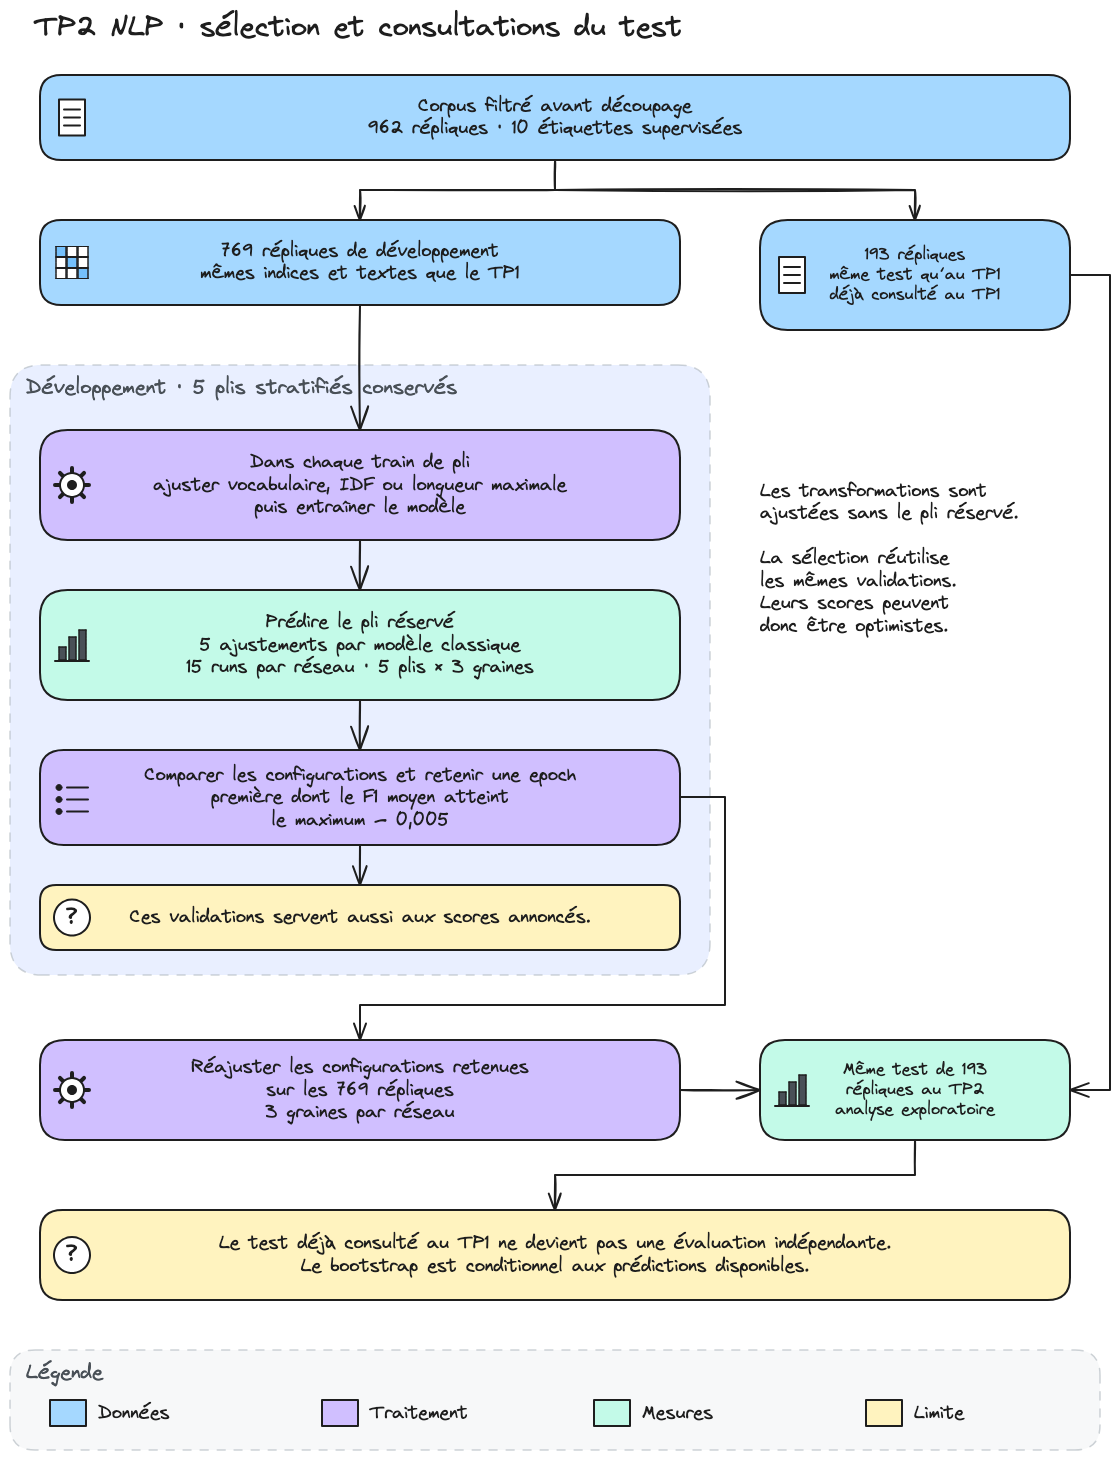

In [8]:
# Je représente le protocole de sélection et le statut du test.
from IPython.display import Image

display(Image(filename='diagrams/nlp/tp2_protocole.png', width=1000))

### 1.3 Choisir le tokenizer

Je conserve des unités proches des mots pour commencer la comparaison. Je compte les formes présentes dans le développement avant de choisir le découpage. Cette exploration intervient dans ma conception du prétraitement, même si les vocabulaires seront ajustés séparément dans chaque pli.

In [9]:
# Faits sur le texte brut des 769 répliques de développement, avant toute décision de découpage.
from collections import Counter

# Chaque cas est un motif regex ; « mot » = lettres et apostrophes, sans découpage imposé.
CAS = {
    'Apostrophe en tête': r"(?<![A-Za-z])'[A-Za-z]+",
    'Apostrophe interne': r"[A-Za-z]+'[A-Za-z]+",
    'Apostrophe en fin': r"[A-Za-z]+'(?![A-Za-z])",
    'Mot d’une lettre': r"(?<![A-Za-z'])[A-Za-z](?![A-Za-z'])",
    'Tiret': r"[A-Za-z]+-[A-Za-z]+",
    'Chiffre': r"\d+",
    'Ponctuation': r"[,;:!?.]",
}


def compter_cas(motif: str) -> dict:
    """Répliques contenant le motif et les trois formes les plus fréquentes qu'il capture."""
    expression = re.compile(motif)
    formes = Counter(forme.lower() for texte in X_train for forme in expression.findall(texte))
    return {
        'Répliques concernées': sum(bool(expression.search(texte)) for texte in X_train),
        'Formes les plus fréquentes': ', '.join(
            f'{forme} ({n})' for forme, n in formes.most_common(3)),
    }


# Un tableau, une ligne par cas
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame({cas: compter_cas(motif) for cas, motif in CAS.items()}).T
            .rename_axis('Cas dans le texte brut'))

# Longueurs médianes en mots et en caractères ; leur rapport chiffre un découpage en caractères.
mots_par_replique = X_train.str.split().str.len()
caracteres_par_replique = X_train.str.len()
caracteres_par_mot = caracteres_par_replique.median() / mots_par_replique.median()
print(f'Longueur médiane : {mots_par_replique.median():g} mots '
      f'et {caracteres_par_replique.median():g} caractères par réplique, '
      f'soit un rapport des médianes de {caracteres_par_mot:.1f}.')

,Répliques concernées,Formes les plus fréquentes
Cas dans le texte brut,,
Apostrophe en tête,119,"'tis (61), 'twere (10), 'twas (8)"
Apostrophe interne,392,"i'll (103), that's (20), ne'er (13)"
Apostrophe en fin,81,"i' (23), o' (22), banished' (4)"
Mot d’une lettre,549,"i (902), a (574), o (128)"
Tiret,149,"to-morrow (15), to-night (7), to-day (7)"
Chiffre,3,3 (3)
Ponctuation,769,", (3783), . (1247), ; (730)"


Longueur médiane : 31 mots et 159 caractères par réplique, soit un rapport des médianes de 5.1.


> *Mes observations :*
>
> Les apostrophes internes concernent 392 répliques, contre 119 pour les apostrophes initiales et 81 pour les finales. Les mots d’une lettre apparaissent dans 549 répliques et les tirets dans 149.

Les exemples affichés montrent ce que le découpage doit traiter, dont « i'll », « 'tis » et « i' ». Le rapport entre les médianes est 159 / 31, soit environ 5,1. Ce rapport ne décrit pas le nombre de caractères de chaque mot.

Le tokenizer du TP1 retire les tokens d’une lettre et coupe aux apostrophes. Je conserve les contractions internes pour éviter de représenter « I'll » par le seul fragment `ll`.

| Cas | Choix conservé | Motif |
|---|---|---|
| Majuscules | Minuscules | Regrouper les variantes de casse. |
| Ponctuation | Séparateurs | Commencer par les unités lexicales, sans tester ici les marques de ponctuation. |
| Mots d’une lettre | Conservés | Garder pronoms, articles et interjections. |
| Apostrophe interne | Dans le token | Conserver une contraction comme `i'll`. |
| Apostrophe initiale ou finale | Retirée | Garder `tis` et `i`, avec une perte de cette distinction graphique. |
| Tiret | Séparation | Garder `to` et `morrow` comme deux tokens. |
| Chiffres | Supprimés | Maintenir le choix initial sur les trois répliques concernées. |
| Caractères comme unités | Non testés | Limiter cette comparaison aux représentations lexicales. |

Ces choix ne prouvent pas que les éléments retirés sont inutiles. Je conserve une référence avec le tokenizer du TP1 pour mesurer l’effet global de ce changement.

In [10]:
# Tokenizer commun aux modèles ML et DL, et reproduction du découpage par défaut du TP1.
MOTIF_TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)*")  # Lettres et apostrophes internes.
MOTIF_DEFAUT = re.compile(r"(?u)\b\w\w+\b")  # token_pattern par défaut de scikit-learn (TP1).


def tokeniser(texte: str) -> list[str]:
    """Tokenizer commun : minuscules, mots et contractions."""
    return MOTIF_TOKEN.findall(texte.lower())


def tokeniser_defaut(texte: str) -> list[str]:
    """Découpage du TP1, pour mesurer ce que je change."""
    return MOTIF_DEFAUT.findall(texte.lower())


def montrer_decoupages(indices: tuple[int, ...]) -> None:
    """Affiche des répliques de développement et leurs deux découpages."""
    for indice in indices:
        print(f'{y_train.loc[indice]} : {X_train.loc[indice]}')
        print(f'   TP1    : {tokeniser_defaut(X_train.loc[indice])}')
        print(f'   commun : {tokeniser(X_train.loc[indice])}\n')


# Trois répliques : contraction, apostrophe en tête, nom propre et mots d'une lettre.
montrer_decoupages((3062, 563, 6253))


ROMEO : Switch and spurs, switch and spurs; or I'll cry a match.
   TP1    : ['switch', 'and', 'spurs', 'switch', 'and', 'spurs', 'or', 'll', 'cry', 'match']
   commun : ['switch', 'and', 'spurs', 'switch', 'and', 'spurs', 'or', "i'll", 'cry', 'a', 'match']

MENENIUS : For 'tis a sore upon us, You cannot tent yourself: be gone, beseech you.
   TP1    : ['for', 'tis', 'sore', 'upon', 'us', 'you', 'cannot', 'tent', 'yourself', 'be', 'gone', 'beseech', 'you']
   commun : ['for', 'tis', 'a', 'sore', 'upon', 'us', 'you', 'cannot', 'tent', 'yourself', 'be', 'gone', 'beseech', 'you']

PETRUCHIO : Nay, hear you, Kate: in sooth you scape not so.
   TP1    : ['nay', 'hear', 'you', 'kate', 'in', 'sooth', 'you', 'scape', 'not', 'so']
   commun : ['nay', 'hear', 'you', 'kate', 'in', 'sooth', 'you', 'scape', 'not', 'so']



Je compare les deux découpages sur le développement pour voir quels tokens deviennent visibles. Les tailles des vocabulaires décrivent les représentations obtenues. Elles complètent les contrôles du découpage sans les remplacer.

In [11]:
# Ce que chaque découpage voit sur les 769 répliques de développement, puis l'empreinte du TP1.
from sklearn.feature_extraction.text import TfidfVectorizer

TOKENISEURS = {'TP1': tokeniser_defaut, 'commun': tokeniser}
PARAMS_TFIDF = dict(ngram_range=(1, 2), min_df=2, max_df=1.0, stop_words=None, sublinear_tf=True)


def compter_tokens(decouper) -> Counter:
    """Fréquence de chaque token sur le développement : une description, pas un apprentissage."""
    return Counter(token for texte in X_train for token in decouper(texte))


def plus_frequents(comptes: dict, n: int = 6) -> str:
    """Les n tokens les plus fréquents d'un dictionnaire de comptes, avec leur compte."""
    tries = sorted(comptes.items(), key=lambda paire: -paire[1])
    return ', '.join(f'{token} ({compte})' for token, compte in tries[:n])


def comparer_decoupages() -> pd.DataFrame:
    """Tokens vus par chaque découpage, et ceux que seul l'un des deux produit."""
    comptes = {nom: compter_tokens(decouper) for nom, decouper in TOKENISEURS.items()}
    seulement = {
        nom: {token: n for token, n in comptes[nom].items() if token not in comptes[autre]}
        for nom, autre in (('TP1', 'commun'), ('commun', 'TP1'))
    }
    return pd.DataFrame({
        'Tokens distincts': {nom: len(compte) for nom, compte in comptes.items()},
        'Tokens': {nom: sum(compte.values()) for nom, compte in comptes.items()},
        'Tokens distincts absents de l’autre': {
            nom: len(absents) for nom, absents in seulement.items()},
        'Tokens absents de l’autre': {
            nom: sum(absents.values()) for nom, absents in seulement.items()},
        'Les plus fréquents absents de l’autre': {
            nom: plus_frequents(absents) for nom, absents in seulement.items()},
    }).rename_axis('Tokenizer')


def taille_vocabulaire(vectoriseur: TfidfVectorizer) -> int:
    """Nombre de termes appris sur les 769 répliques de développement."""
    return len(vectoriseur.fit(X_train).vocabulary_)


with pd.option_context('display.max_colwidth', None):
    display(comparer_decoupages())

# Taille de vocabulaire du TP1, en complément du contrôle des séries complètes.
termes_tp1 = taille_vocabulaire(TfidfVectorizer(lowercase=True, **PARAMS_TFIDF))
termes_commun = taille_vocabulaire(
    TfidfVectorizer(tokenizer=tokeniser, token_pattern=None, lowercase=False, **PARAMS_TFIDF)
)
print(f'Termes TF–IDF (1-2 grammes, min_df=2) : TP1 {termes_tp1:,} ; '
      f'tokenizer commun {termes_commun:,}')

,Tokens distincts,Tokens,Tokens distincts absents de l’autre,Tokens absents de l’autre,Les plus fréquents absents de l’autre
Tokenizer,,,,,
TP1,5139,36091,129,371,"ll (119), st (56), er (26), ne (13), ld (8), rt (4)"
commun,5449,37652,439,2559,"i (927), a (576), o (151), i'll (103), that's (20), ne'er (13)"


Termes TF–IDF (1-2 grammes, min_df=2) : TP1 5,915 ; tokenizer commun 6,108


> *Mes observations :*
>
> Le tokenizer commun produit 37 652 occurrences et 5 449 tokens distincts, contre 36 091 et 5 139 pour celui du TP1. Ses 439 tokens distincts propres représentent 2 559 occurrences, dont `i`, `a`, `o` et `i'll`.

Les découpages ne produisent pas les mêmes unités, donc ces 2 559 occurrences ne sont pas autant de mots simplement effacés par le TP1. Les vocabulaires TF–IDF comptent 5 915 et 6 108 termes. Je mesurerai ensuite l’effet de ce choix sur LinearSVC.

## 2. Représentation

### 2.1 Ma référence TF–IDF

Je garde les paramètres du TP1 et construis un vectoriseur neuf dans chaque pli. Le tokenizer commun aligne les unités lexicales des modèles, mais leurs représentations restent différentes.

Je corrige ici le raisonnement de H1. TF–IDF conserve des bigrammes et utilise donc l’ordre local, tandis que la moyenne des embeddings ignore l’ordre des tokens qu’elle reçoit.

In [12]:
# Un vectoriseur TF–IDF neuf pour chaque référence, à ajuster sur le train d'un fold.


def construire_tfidf(reference: str) -> TfidfVectorizer:
    """Vectoriseur neuf : 'TP1' = découpage par défaut, 'commun' = tokenizer de la section 1.3."""
    if reference == 'TP1':
        return TfidfVectorizer(lowercase=True, **PARAMS_TFIDF)
    return TfidfVectorizer(tokenizer=tokeniser, token_pattern=None, lowercase=False, **PARAMS_TFIDF)


Je mesure les termes, la densité et la part des tokens de validation absents du vocabulaire ajusté. Cette dernière mesure prépare l’usage de `<UNK>` par les réseaux. Je conserve les unigrammes de chaque pli pour comparer directement les deux vocabulaires.

In [13]:
# Bilan de chaque référence sur chaque fold : termes, densité et tokens de validation inconnus.


def pourcentage(partie: float, total: float) -> float:
    """Part en pourcentage."""
    return 100 * partie / total


def detailler_tokens(
    vectoriseur: TfidfVectorizer, decouper, textes_train: pd.Series, textes_validation: pd.Series,
) -> dict:
    """Unigrammes appris, tokens de validation, inconnus et fréquence documentaire du train."""
    unigrammes = {terme for terme in vectoriseur.vocabulary_ if ' ' not in terme}
    tokens_validation = [token for texte in textes_validation for token in decouper(texte)]
    # Absents du vocabulaire retenu, pas forcément absents des textes d’entraînement.
    inconnus = [token for token in tokens_validation if token not in unigrammes]
    documents_train = Counter(token for texte in textes_train for token in set(decouper(texte)))
    return {'unigrammes': unigrammes, 'tokens_validation': tokens_validation,
            'inconnus': inconnus, 'documents_train': documents_train}


def decrire_reference(
    numero: int, reference: str, textes_train: pd.Series, textes_validation: pd.Series,
) -> tuple[dict, dict]:
    """Ajuste une référence sur le train d'un fold : ligne de bilan et détail des tokens."""
    vectoriseur = construire_tfidf(reference)
    matrice_train = vectoriseur.fit_transform(textes_train)  # Appris sur le train seul.
    matrice_validation = vectoriseur.transform(textes_validation)
    assert matrice_train.shape == (len(textes_train), len(vectoriseur.vocabulary_))
    assert matrice_validation.shape == (len(textes_validation), len(vectoriseur.vocabulary_))

    detail = detailler_tokens(vectoriseur, TOKENISEURS[reference], textes_train, textes_validation)
    taille_matrice = matrice_train.shape[0] * matrice_train.shape[1]
    bilan = {
        'Fold': numero, 'Référence': reference,
        'Termes': len(vectoriseur.vocabulary_), 'Unigrammes': len(detail['unigrammes']),
        'Bigrammes': len(vectoriseur.vocabulary_) - len(detail['unigrammes']),
        'Non nuls (%)': pourcentage(matrice_train.nnz, taille_matrice),
        'Tokens de validation inconnus (%)': pourcentage(
            len(detail['inconnus']), len(detail['tokens_validation'])),
    }
    return bilan, detail


# Boucle sur les folds : bilan par référence, unigrammes et détails conservés
bilan_tfidf, details_par_fold = [], {}
unigrammes_tfidf = {}  # (fold, référence) -> unigrammes du train, pour la section 2.2
for numero, fold in enumerate(folds, start=1):
    textes_train, textes_validation = X_train.loc[fold['train']], X_train.loc[fold['validation']]
    details_par_fold[numero] = {}
    for reference in TOKENISEURS:
        bilan, detail = decrire_reference(numero, reference, textes_train, textes_validation)
        bilan_tfidf.append(bilan)
        details_par_fold[numero][reference] = detail
        unigrammes_tfidf[(numero, reference)] = detail['unigrammes']

# Affichages : bilan par fold, puis moyenne par référence
bilan_tfidf = pd.DataFrame(bilan_tfidf).set_index(['Fold', 'Référence'])
display(bilan_tfidf.round(2))
display(bilan_tfidf.groupby('Référence').mean().round(2).rename_axis('Moyenne des cinq folds'))

Termes  Unigrammes  Bigrammes  Non nuls (%)  \
Fold Référence                                                
1    TP1          4861        1996       2865          1.00   
     commun       5025        2038       2987          1.02   
2    TP1          4716        1933       2783          1.01   
     commun       4898        1981       2917          1.02   
3    TP1          4688        1922       2766          1.00   
     commun       4843        1968       2875          1.02   
4    TP1          4644        1945       2699          1.00   
     commun       4806        1993       2813          1.01   
5    TP1          4807        1978       2829          1.01   
     commun       4970        2023       2947          1.02   

                Tokens de validation inconnus (%)  
Fold Référence                                     
1    TP1                                    13.67  
     commun                                 14.12  
2    TP1                                    15.34  
     commun                                 15.54  
3    TP1                                    14.64  
     commun                                 14.98  
4    TP1                                    13.88  
     commun                                 14.28  
5    TP1                                    13.70  
     commun                                 14.20

,Termes,Unigrammes,Bigrammes,Non nuls (%),Tokens de validation inconnus (%)
Moyenne des cinq folds,,,,,
TP1,4743.2,1954.8,2788.4,1.00,14.24
commun,4908.4,2000.6,2907.8,1.02,14.62


> *Mes observations :*
>
> Les vocabulaires du TP1 vont de 4 644 à 4 861 termes, contre 5 915 sur tout le développement. Le tokenizer commun ajoute de 155 à 182 termes par pli.

Les matrices contiennent environ 1 % de valeurs non nulles, donc environ 99 % de zéros. Les moyennes des cinq taux d’inconnus valent 14,24 % et 14,62 %. Ces tokens sont absents du vocabulaire retenu, pas nécessairement du texte d’entraînement.

Je cherche si les contractions et le filtre `min_df=2` contribuent aux inconnus. Ce filtre compte les répliques contenant un token, pas ses occurrences. Un mot répété dans une seule réplique reste donc exclu.

In [14]:
# Origine des tokens inconnus : apostrophes, tokens vus une seule fois dans le train, et
# unigrammes propres au tokenizer commun.


def vus_une_fois(detail: dict) -> int:
    """Tokens inconnus présents dans une seule réplique du train, donc exclus par min_df=2."""
    return sum(detail['documents_train'][token] == 1 for token in detail['inconnus'])


def analyser_inconnus(numero: int, textes_train: pd.Series, details: dict) -> dict:
    """Origine des inconnus : apostrophes, et tokens vus une seule fois dans le train."""
    tp1, commun = details['TP1'], details['commun']
    sans_apostrophe = [token for token in commun['tokens_validation'] if "'" not in token]
    inconnus_sans_apostrophe = sum(token not in commun['unigrammes'] for token in sans_apostrophe)
    propres_au_commun = commun['unigrammes'] - tp1['unigrammes']
    comptes_train = Counter(token for texte in textes_train for token in tokeniser(texte))
    return {
        'Fold': numero,
        'Inconnus TP1': len(tp1['inconnus']),
        'Inconnus commun': len(commun['inconnus']),
        'Commun avec apostrophe (%)': pourcentage(
            sum("'" in token for token in commun['inconnus']), len(commun['inconnus'])),
        'Commun sans tokens à apostrophe (%)': pourcentage(
            inconnus_sans_apostrophe, len(sans_apostrophe)),
        'Vus une fois dans le train, TP1 (%)': pourcentage(vus_une_fois(tp1), len(tp1['inconnus'])),
        'Vus une fois dans le train, commun (%)': pourcentage(
            vus_une_fois(commun), len(commun['inconnus'])),
        'Unigrammes propres au commun': plus_frequents(
            {token: comptes_train[token] for token in propres_au_commun}, n=5),
    }


detail_inconnus = [
    analyser_inconnus(numero, X_train.loc[fold['train']], details_par_fold[numero])
    for numero, fold in enumerate(folds, start=1)
]
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(detail_inconnus).set_index('Fold').round(2))


,Inconnus TP1,Inconnus commun,Commun avec apostrophe (%),Commun sans tokens à apostrophe (%),"Vus une fois dans le train, TP1 (%)","Vus une fois dans le train, commun (%)",Unigrammes propres au commun
Fold,,,,,,,
1,898,969,9.80,13.05,35.52,35.29,"i (747), a (472), o (128), i'll (87), that's (18)"
2,1097,1157,8.04,14.65,37.65,37.17,"i (748), a (468), o (127), i'll (87), that's (16)"
3,1096,1170,8.29,14.07,38.78,36.84,"i (741), a (451), o (111), i'll (83), that's (13)"
4,1110,1191,8.56,13.36,37.48,36.78,"i (728), a (447), o (121), i'll (75), that's (18)"
5,943,1021,9.30,13.20,36.37,36.04,"i (744), a (466), o (117), i'll (80), that's (15)"


> *Mes observations :*
>
> Les apostrophes concernent entre 8 % et 10 % des occurrences inconnues du tokenizer commun. Entre 35 % et 39 % des inconnus apparaissent dans une seule réplique d’entraînement et sont exclus par le filtre.

Retirer les tokens à apostrophe du calcul change aussi son dénominateur. Je ne peux donc pas attribuer tout l’écart entre tokenizers aux contractions. Les réseaux remplaceront les inconnus par `<UNK>`, tandis que TF–IDF ne leur attribue pas de colonne propre.

### 2.2 Des tokens aux embeddings

Chaque token reçoit un identifiant, puis un vecteur dans une matrice d’embeddings. Ces vecteurs s’ajustent avec le classifieur, alors que TF–IDF calcule des poids à partir des fréquences documentaires.

Je conserve des embeddings initialisés aléatoirement pour comparer des méthodes sans données de préentraînement supplémentaires. Ce choix ne teste pas l’intérêt de vecteurs préentraînés sur cette tâche.

Je garde les tokens présents dans au moins deux répliques du train de chaque pli, comme les unigrammes TF–IDF. Un token plus rare pourrait recevoir des gradients, mais sa représentation disposerait de peu d’exemples distincts.

`<UNK>` regroupe les tokens exclus ou absents. `<PAD>` complète les séquences d’un batch jusqu’à une longueur commune. Le masque et les longueurs permettront d’écarter ce remplissage des représentations.

In [15]:
# Vocabulaire par fold, encodage des répliques en identifiants et encodage des dix classes.
import math

PAD, UNK = '<PAD>', '<UNK>'  # Identifiants 0 et 1, réservés.
CLASSES = sorted(donnees['locuteur'].unique())  # Fixé une fois, ordre alphabétique.
INDICE_CLASSE = {classe: indice for indice, classe in enumerate(CLASSES)}


def construire_vocabulaire(textes_train: pd.Series) -> dict[str, int]:
    """Tokens présents dans au moins deux répliques du train (même règle que min_df=2), triés."""
    documents = Counter(token for texte in textes_train for token in set(tokeniser(texte)))
    retenus = sorted(token for token, nombre in documents.items() if nombre >= 2)
    return {token: indice for indice, token in enumerate([PAD, UNK] + retenus)}


def longueur_maximale(textes_train: pd.Series, quantile: float) -> int:
    """Plafond de longueur : quantile des longueurs en tokens du train, arrondi vers le haut."""
    longueurs = [len(tokeniser(texte)) for texte in textes_train]
    return math.ceil(np.quantile(longueurs, quantile))


def encoder(texte: str, vocabulaire: dict[str, int], longueur_max: int) -> list[int]:
    """Identifiants des tokens, <UNK> pour les absents, tronqués à la longueur maximale."""
    inconnu = vocabulaire[UNK]
    return [vocabulaire.get(token, inconnu) for token in tokeniser(texte)][:longueur_max]


def compter_troncature(textes: pd.Series, longueur_max: int) -> tuple[int, int, int]:
    """Répliques tronquées, tokens perdus et tokens au total pour une longueur maximale."""
    longueurs = [len(tokeniser(texte)) for texte in textes]
    tronquees = sum(longueur > longueur_max for longueur in longueurs)
    perdus = sum(max(longueur - longueur_max, 0) for longueur in longueurs)
    return tronquees, perdus, sum(longueurs)


print('Classes :', ', '.join(f'{indice} = {classe}' for classe, indice in INDICE_CLASSE.items()))


Classes : 0 = CORIOLANUS, 1 = DUKE VINCENTIO, 2 = GLOUCESTER, 3 = ISABELLA, 4 = JULIET, 5 = KING RICHARD II, 6 = LEONTES, 7 = MENENIUS, 8 = PETRUCHIO, 9 = ROMEO


Je compare le vocabulaire lexical aux unigrammes du TF–IDF commun dans chaque pli, en excluant `<PAD>` et `<UNK>`. Les deux constructions suivent la même fréquence documentaire minimale. Je vérifie ensuite que leurs taux de tokens inconnus coïncident.

In [16]:
# Vocabulaire de chaque fold, égal aux unigrammes TF–IDF, et tokens de validation inconnus.


def mesurer_fold(numero: int, fold: dict) -> dict:
    """Vocabulaire du train du fold, égal aux unigrammes TF–IDF, et inconnus de la validation."""
    textes_train, textes_validation = X_train.loc[fold['train']], X_train.loc[fold['validation']]
    vocabulaire = construire_vocabulaire(textes_train)
    assert set(vocabulaire) - {PAD, UNK} == unigrammes_tfidf[(numero, 'commun')]  # Même règle
    tokens = [token for texte in textes_validation for token in tokeniser(texte)]
    inconnus = pourcentage(sum(token not in vocabulaire for token in tokens), len(tokens))
    reference = bilan_tfidf.loc[(numero, 'commun'), 'Tokens de validation inconnus (%)']
    assert abs(inconnus - reference) < 1e-9  # Même mesure que dans la section 2.1
    return {'Fold': numero, 'Vocabulaire (avec <PAD> et <UNK>)': len(vocabulaire),
            'Tokens de validation inconnus (%)': inconnus}


mesures = pd.DataFrame(mesurer_fold(numero, fold) for numero, fold in enumerate(folds, 1))
display(mesures.set_index('Fold').round(2))
print('Vocabulaire hors <PAD>/<UNK> égal aux unigrammes TF–IDF dans les cinq plis.')

,Vocabulaire (avec <PAD> et <UNK>),Tokens de validation inconnus (%)
Fold,,
1,2040,14.12
2,1983,15.54
3,1970,14.98
4,1995,14.28
5,2025,14.20


Vocabulaire hors <PAD>/<UNK> égal aux unigrammes TF–IDF dans les cinq plis.


> *Mes observations :*
>
> Le vocabulaire d’un pli contient de 1 970 à 2 040 identifiants, dont `<PAD>` et `<UNK>`. Sans ces deux symboles, il égale les unigrammes du TF–IDF commun dans les cinq plis.

Les taux de tokens de validation inconnus vont de 14,1 % à 15,5 %, comme en section 2.1.

Je fixe ensuite une longueur maximale de séquence, car les répliques vont de 10 à 578 mots. Un plafond borne le coût d'un réseau récurrent, qui lit les tokens un à un, et le padding des batches, mais il coupe des tokens. Je mesure ce coût pour plusieurs quantiles des longueurs du train, en répliques tronquées et en tokens perdus.


In [17]:
# Coût de chaque quantile de longueur : répliques tronquées et tokens perdus, train et validation.
QUANTILES = (0.90, 0.95, 0.99, 1.00)


def mesurer_troncature(fold: dict, quantile: float) -> dict:
    """Longueur maximale sur le train du fold, et ce qu'elle tronque en train et en validation."""
    textes_train, textes_validation = X_train.loc[fold['train']], X_train.loc[fold['validation']]
    longueur_max = longueur_maximale(textes_train, quantile)
    ligne = {'Quantile': quantile, 'Longueur maximale': longueur_max}
    for nom, textes in (('train', textes_train), ('validation', textes_validation)):
        tronquees, perdus, total = compter_troncature(textes, longueur_max)
        ligne[f'Répliques tronquées {nom} (%)'] = pourcentage(tronquees, len(textes))
        ligne[f'Tokens perdus {nom} (%)'] = pourcentage(perdus, total)
    return ligne


troncature = pd.DataFrame(
    mesurer_troncature(fold, quantile) for fold in folds for quantile in QUANTILES)
display(troncature.groupby('Quantile').mean().round(2))


,Longueur maximale,Répliques tronquées train (%),Tokens perdus train (%),Répliques tronquées validation (%),Tokens perdus validation (%)
Quantile,,,,,
0.90,100.6,9.88,15.71,10.66,15.91
0.95,147.0,4.97,8.78,5.07,8.99
0.99,281.0,1.01,2.05,1.17,2.17
1.00,573.6,0.00,0.00,0.13,0.09


> *Mes observations :*
>
> Au quantile 0,99, la longueur maximale moyenne vaut 281 tokens et les pertes moyennes valent 2,05 % en entraînement et 2,17 % en validation. Au maximum du train, elles valent 0 % et 0,09 %.

Je conserve le quantile 0,99 comme compromis de calcul. Passer au maximum récupère environ 2,08 points de tokens en validation, avec des plafonds moyens de 281 à 574. La longueur effective d’un batch dépend aussi de sa réplique la plus longue.

Je compte les paramètres des embeddings avant de fixer leur dimension. Cela indique la taille de la matrice face au nombre de répliques disponibles. Ce rapport ne mesure ni sa capacité effective ni le surapprentissage à lui seul.

In [18]:
# Paramètres de la matrice d'embeddings selon sa dimension, rapportés aux répliques de train.
DIMENSIONS = (32, 64, 128)


def parametres_embeddings(taille_vocabulaire: float, dimension: int, repliques: int) -> dict:
    """Paramètres de la matrice d'embeddings et rapport aux répliques de train d'un fold."""
    parametres = taille_vocabulaire * dimension
    return {'Dimension': dimension, 'Paramètres de la matrice': round(parametres),
            'Paramètres par réplique de train': round(parametres / repliques, 1)}


taille_moyenne = mesures['Vocabulaire (avec <PAD> et <UNK>)'].mean()
repliques_train = round(np.mean([len(fold['train']) for fold in folds]))
print(f'Vocabulaire moyen : {taille_moyenne:.0f} identifiants '
      f'pour {repliques_train} répliques de train.')
display(pd.DataFrame(
    parametres_embeddings(taille_moyenne, dimension, repliques_train) for dimension in DIMENSIONS
).set_index('Dimension'))


Vocabulaire moyen : 2003 identifiants pour 615 répliques de train.


,Paramètres de la matrice,Paramètres par réplique de train
Dimension,,
32,64083,104.2
64,128166,208.4
128,256333,416.8


> *Mes observations :*
>
> Les dimensions 32, 64 et 128 donnent environ 64 083, 128 166 et 256 333 paramètres dans la matrice moyenne. Le comptage inclut la ligne de padding, qui reste fixe ici.

Je conserve la dimension 64 pour partager une taille d’embedding entre les trois réseaux. Le tableau chiffre son coût en paramètres, sans montrer que 32 serait insuffisant ou que 128 améliorerait le score. H3 sera examinée sur les courbes d’apprentissage.

Je prépare maintenant les batches, car PyTorch consomme des tenseurs et non des listes de tokens. Un `Dataset` encode chaque réplique en identifiants avec la longueur retenue. Puis une fonction d'assemblage complète les séquences d'un batch avec `<PAD>` jusqu'à la plus longue, et garde les longueurs réelles et un masque pour les étapes suivantes.


In [19]:
# Dataset PyTorch et assemblage des batches, avec la longueur et la dimension retenues ci-dessus.
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset

QUANTILE_LONGUEUR = 0.99  # Longueur maximale : quantile 0,99 des longueurs du train du fold.
DIM_EMBEDDING = 64


class JeuRepliques(Dataset):
    """Répliques encodées en identifiants et classes encodées en indices, pour un DataLoader."""

    def __init__(self, textes: pd.Series, cibles: pd.Series, vocabulaire: dict, longueur_max: int):
        self.identifiants = [encoder(texte, vocabulaire, longueur_max) for texte in textes]
        self.classes = [INDICE_CLASSE[cible] for cible in cibles]

    def __len__(self) -> int:
        return len(self.identifiants)

    def __getitem__(self, position: int) -> tuple[torch.Tensor, int]:
        return torch.tensor(self.identifiants[position]), self.classes[position]


def assembler_batch(lot: list) -> dict:
    """Complète les séquences d'un batch avec <PAD> (0) ; garde longueurs, masque et classes."""
    sequences, classes = zip(*lot)
    identifiants = pad_sequence(sequences, batch_first=True, padding_value=0)
    return {'identifiants': identifiants, 'longueurs': torch.tensor([len(s) for s in sequences]),
            'masque': identifiants != 0, 'classes': torch.tensor(classes)}


# Fold 1 : jeu de train et un batch des quatre premières répliques
fold_1 = folds[0]
textes_1, cibles_1 = X_train.loc[fold_1['train']], y_train.loc[fold_1['train']]
vocabulaire_1 = construire_vocabulaire(textes_1)
longueur_max_1 = longueur_maximale(textes_1, QUANTILE_LONGUEUR)
jeu_1 = JeuRepliques(textes_1, cibles_1, vocabulaire_1, longueur_max_1)
batch = assembler_batch([jeu_1[position] for position in range(4)])
print(f'Fold 1 : {len(vocabulaire_1)} identifiants, longueur maximale {longueur_max_1}, '
      f'{len(jeu_1)} répliques de train')
for nom, tenseur in batch.items():
    print(f'   {nom} : forme {tuple(tenseur.shape)}, dtype {tenseur.dtype}')
print(f"   longueurs : {batch['longueurs'].tolist()} ; classes : {batch['classes'].tolist()}\n")


Fold 1 : 2040 identifiants, longueur maximale 280, 615 répliques de train
   identifiants : forme (4, 47), dtype torch.int64
   longueurs : forme (4,), dtype torch.int64
   masque : forme (4, 47), dtype torch.bool
   classes : forme (4,), dtype torch.int64
   longueurs : [31, 47, 10, 40] ; classes : [0, 2, 8, 6]



Je veux représenter chaque réplique sans compter le remplissage. Pour le MLP, la moyenne masquée additionne les embeddings des tokens conservés puis divise par leur nombre.

Le LSTM et le GRU gardent l’état après le dernier token réel de la séquence tronquée. Je vérifie ces règles en ajoutant du padding à une même réplique. Ce contrôle complète les formes des tenseurs par une comparaison numérique.

In [20]:
# Deux représentations d'une réplique entière et le test d'invariance au padding.
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

PADDING_SUPPLEMENTAIRE = 20  # Tokens <PAD> ajoutés pour le test d'invariance.


def moyenne_masquee(vecteurs: torch.Tensor, masque: torch.Tensor) -> torch.Tensor:
    """Moyenne des vecteurs des tokens réels seulement : le padding ne compte pas."""
    poids = masque.unsqueeze(-1).to(vecteurs.dtype)
    return (vecteurs * poids).sum(dim=1) / poids.sum(dim=1)


def etat_final(rnn: nn.Module, vecteurs: torch.Tensor, longueurs: torch.Tensor) -> torch.Tensor:
    """État récurrent après le dernier token réel ; les directions sont concaténées."""
    paquet = pack_padded_sequence(vecteurs, longueurs.cpu(), batch_first=True, enforce_sorted=False)
    _, etats = rnn(paquet)
    if isinstance(etats, tuple):  # LSTM : (h, c) ; je garde h.
        etats = etats[0]
    directions = 2 if rnn.bidirectional else 1
    return torch.cat(list(etats[-directions:]), dim=-1)  # Dernière couche, chaque direction


def representer(identifiants: torch.Tensor, embeddings: nn.Embedding, rnns: dict) -> dict:
    """Moyenne masquée et états finaux d'un batch, pour des modules donnés."""
    identifiants = identifiants.to(device)
    masque = identifiants != 0
    vecteurs = embeddings(identifiants)
    sorties = {'Moyenne masquée': moyenne_masquee(vecteurs, masque)}
    for nom, rnn in rnns.items():
        sorties[nom] = etat_final(rnn, vecteurs, masque.sum(dim=1))
    return sorties


def verifier_invariance(texte: str, vocabulaire: dict, longueur_max: int) -> pd.DataFrame:
    """La même réplique avec des <PAD> en plus doit donner les mêmes représentations."""
    torch.manual_seed(RANDOM_STATE)  # Modules aléatoires mais reproductibles
    embeddings = nn.Embedding(len(vocabulaire), DIM_EMBEDDING, padding_idx=0).to(device)
    rnns = {
        'GRU unidirectionnel': nn.GRU(DIM_EMBEDDING, 8, batch_first=True).to(device),
        'GRU bidirectionnel': nn.GRU(
            DIM_EMBEDDING, 8, batch_first=True, bidirectional=True).to(device),
    }
    identifiants = torch.tensor([encoder(texte, vocabulaire, longueur_max)])
    supplement = torch.zeros(1, PADDING_SUPPLEMENTAIRE, dtype=torch.long)
    sans = representer(identifiants, embeddings, rnns)
    avec = representer(torch.cat([identifiants, supplement], dim=1), embeddings, rnns)
    return pd.DataFrame([
        {'Représentation': nom, 'Dimension': sans[nom].shape[1],
         'Écart maximal': (sans[nom] - avec[nom]).abs().max().item(),
         'allclose': torch.allclose(sans[nom], avec[nom], atol=1e-6)}
        for nom in sans
    ]).set_index('Représentation')


# Invariance au padding sur la première réplique de train du fold 1
display(verifier_invariance(textes_1.iloc[0], vocabulaire_1, longueur_max_1))


,Dimension,Écart maximal,allclose
Représentation,,,
Moyenne masquée,64,0.0,True
GRU unidirectionnel,8,0.0,True
GRU bidirectionnel,16,0.0,True


> *Mes observations :*
>
> Sur le premier pli, le plafond vaut 280 tokens et le batch présenté atteint 47 positions. Ajouter 20 `<PAD>` ne change pas les trois représentations testées, avec un écart maximal affiché de zéro.

`allclose` vérifie chaque écart avec la borne `1e-6 + 1e-5 × |référence|`. La première partie est absolue, tandis que la seconde augmente avec la taille de la valeur comparée. Je contrôle ici une moyenne et deux GRU aléatoires sur une réplique. Ce test ne vérifie pas tous les batches ni directement le LSTM.

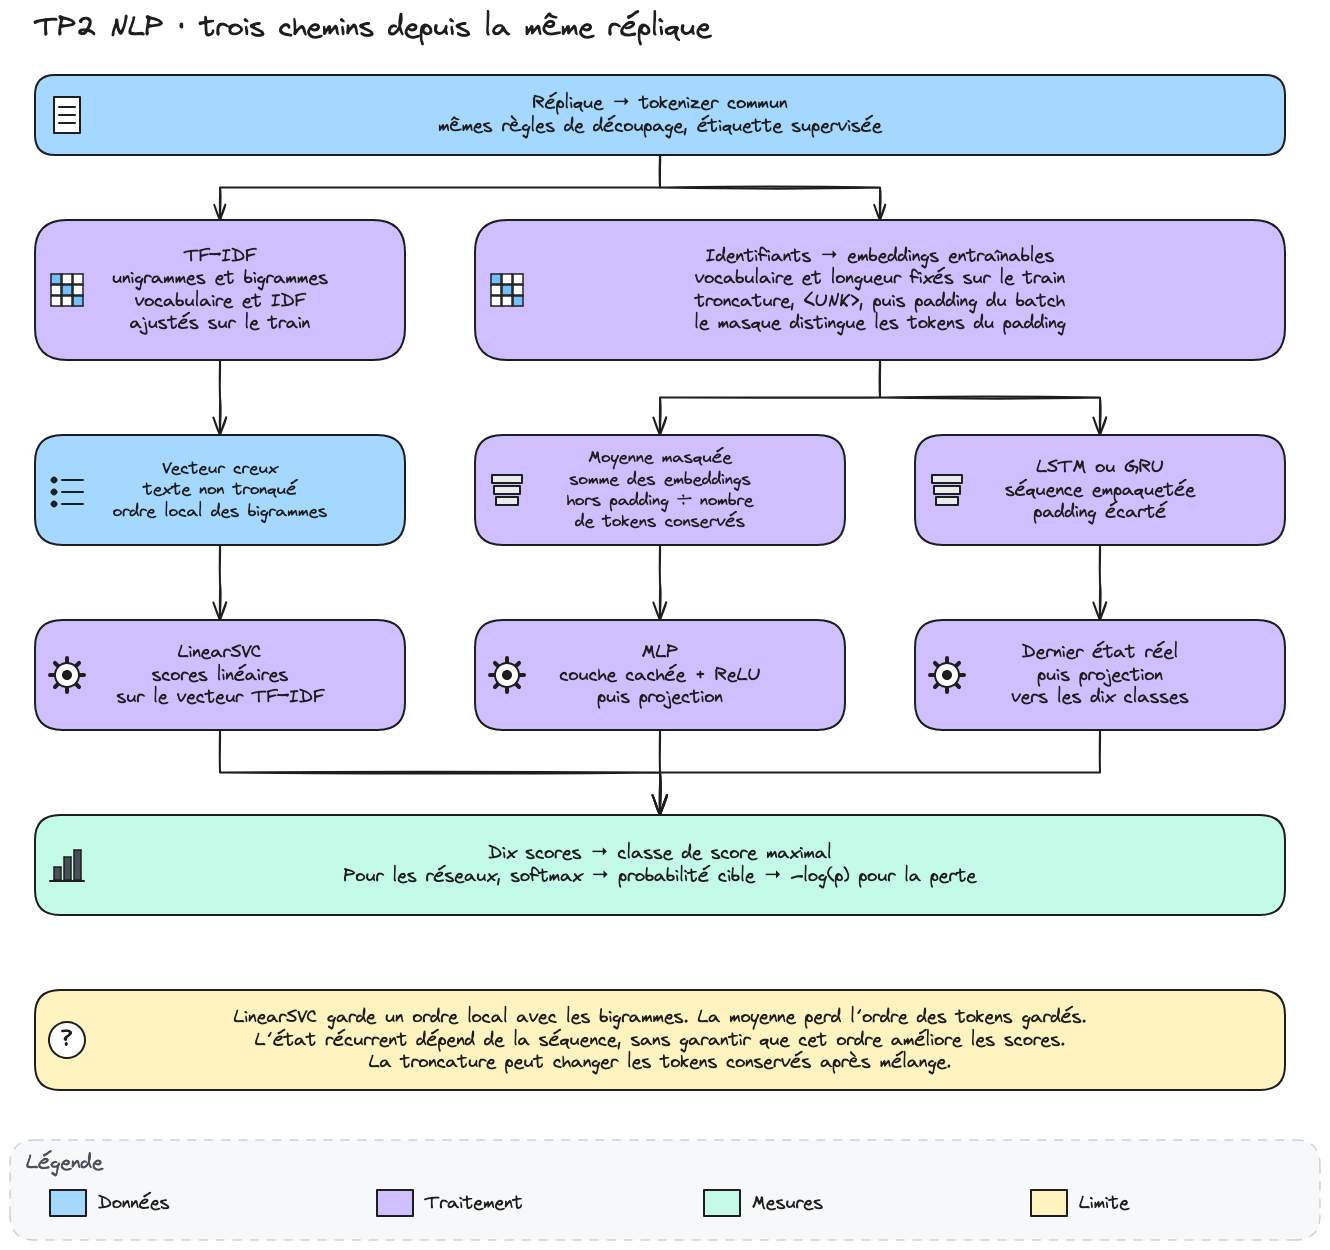

In [21]:
# Je compare les chemins de représentation et les endroits où le padding est écarté.
display(Image(filename='diagrams/nlp/tp2_representations.png', width=1000))

## 3. Comparaison entre modèles ML et DL

### 3.1 Préparer l'entraînement commun

Je compare la classe majoritaire, LinearSVC, puis MLP, LSTM et GRU. J'entraîne les réseaux avec la cross-entropy, car la cible est une classe parmi dix, et je les compare avec le F1 macro, car chaque classe compte autant.


Une epoch parcourt le train du pli. Je retiens la première epoch dont le F1 moyen atteint le maximum moins 0,005, sur les cinq plis et les trois graines.

Je conserve cette règle pour privilégier un résultat atteint tôt près du maximum observé. Elle ne correspond ni à un arrêt anticipé pendant chaque entraînement ni à un choix sur une validation interne.

Les mêmes courbes servent à sélectionner et à annoncer les scores. Cette réutilisation peut favoriser les configurations essayées. Je présente donc ces scores comme des résultats de sélection, avec une comparaison finale également exploratoire.

In [22]:
# Règle de l'epoch retenue : la plus petite epoch à moins de 0,5 point du maximum de la courbe.
TOLERANCE_EPOCH = 0.005  # 0,5 point de F1 macro, sur une échelle de 0 à 1


def epoch_retenue(courbe: pd.Series, tolerance: float = TOLERANCE_EPOCH) -> int:
    """Première epoch dont le F1 macro moyen de validation atteint le maximum moins la tolérance."""
    seuil = courbe.max() - tolerance
    return int(courbe.index[courbe >= seuil][0])


# Exemple construit : le maximum est à l'epoch 5, mais l'epoch 4 est déjà à 0,5 point de lui.
exemple = pd.Series([0.30, 0.42, 0.47, 0.476, 0.48, 0.47],
                    index=pd.RangeIndex(1, 7, name='Epoch'))
print(f'Courbe : {exemple.round(3).to_dict()}')
print(f'Epoch retenue : {epoch_retenue(exemple)}, '
      f'pour un maximum de {exemple.max():.3f} à l’epoch {exemple.idxmax()}')


Courbe : {1: 0.3, 2: 0.42, 3: 0.47, 4: 0.476, 5: 0.48, 6: 0.47}
Epoch retenue : 4, pour un maximum de 0.480 à l’epoch 5


Je fixe des réglages communs pour limiter les changements entre réseaux. Une architecture différente change pourtant sa paramétrisation et sa trajectoire d’optimisation, même à largeur et graine égales.

| Réglage | Valeur | Raison et limite |
|---|---|---|
| Perte | Cross-entropy | Ajuster dix scores à une classe cible. |
| Optimiseur | Adam, taux `1e-3` | Conserver un réglage adaptatif commun, sans recherche de taux. |
| Batch | 32 répliques | Garder le même nombre d’exemples par mise à jour, sauf le dernier batch. |
| Plafond initial | 40 epochs | Examiner la fin de la courbe avant de prolonger un essai. |
| Dropout et weight decay | 0 | Mesurer d’abord cette configuration, puis les variantes prévues. |
| Norme du gradient | Plafonnée à 1 | Limiter les grandes normes observées avant Adam. |
| Pondération des classes | Aucune | Choix conservé, sans comparaison avec une pondération. |
| Graines | 42, 43, 44 | Décrire la variation de trois entraînements sur chaque pli. |

In [23]:
# Réglages communs à tous les réseaux, seed et chargeurs de données d'un fold.
from torch.utils.data import DataLoader

REGLAGES = {
    'taille_batch': 32,
    'taux_apprentissage': 1e-3,
    'epochs_max': 40,
    'dropout': 0.0,
    'weight_decay': 0.0,
    'clip_gradient': 1.0,  # Norme maximale du gradient
    'largeur_cachee': 64,  # Couche cachée du MLP et état des réseaux récurrents
    'dim_embedding': DIM_EMBEDDING,
    'quantile_longueur': QUANTILE_LONGUEUR,
    'tolerance_epoch': TOLERANCE_EPOCH,
    'seeds': (RANDOM_STATE, RANDOM_STATE + 1, RANDOM_STATE + 2),  # 15 runs par réseau
    'device': device,
}


def fixer_seed(seed: int) -> None:
    """Réinitialise random, numpy et torch, y compris MPS, avant chaque entraînement."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


def construire_chargeur(jeu: JeuRepliques, reglages: dict, melanger: bool, seed: int) -> DataLoader:
    """DataLoader avec assemblage des batches, mélange du train fixé par la seed."""
    generateur = torch.Generator().manual_seed(seed) if melanger else None
    return DataLoader(jeu, batch_size=reglages['taille_batch'], shuffle=melanger,
                      generator=generateur, collate_fn=assembler_batch)


def preparer_fold(fold: dict, reglages: dict, seed: int) -> dict:
    """Vocabulaire et longueur maximale sur le train du fold, puis les deux chargeurs."""
    textes_train, textes_validation = X_train.loc[fold['train']], X_train.loc[fold['validation']]
    if reglages.get('pretraitement') is not None:  # Ajusté sur le train du fold seulement
        appliquer = reglages['pretraitement'](textes_train)
        textes_train, textes_validation = appliquer(textes_train), appliquer(textes_validation)
    vocabulaire = construire_vocabulaire(textes_train)
    longueur_max = longueur_maximale(textes_train, reglages['quantile_longueur'])
    jeu_train = JeuRepliques(textes_train, y_train.loc[fold['train']], vocabulaire, longueur_max)
    jeu_validation = JeuRepliques(
        textes_validation, y_train.loc[fold['validation']], vocabulaire, longueur_max)
    return {'vocabulaire': vocabulaire, 'longueur_max': longueur_max,
            'train': construire_chargeur(jeu_train, reglages, True, seed),
            'validation': construire_chargeur(jeu_validation, reglages, False, seed)}


print('\n'.join(f'{cle} : {valeur}' for cle, valeur in REGLAGES.items()))


taille_batch : 32
taux_apprentissage : 0.001
epochs_max : 40
dropout : 0.0
weight_decay : 0.0
clip_gradient : 1.0
largeur_cachee : 64
dim_embedding : 64
quantile_longueur : 0.99
tolerance_epoch : 0.005
seeds : (42, 43, 44)
device : cpu


Les réseaux partagent la boucle et les embeddings comme type de couche, avec leurs propres paramètres entraînés. Chaque sous-classe définit la représentation transmise à la sortie.

La boucle calcule la perte, les gradients, leur plafonnement et la mise à jour. Après chaque epoch, elle mesure train et validation avec le dropout désactivé. Elle conserve les prédictions de chaque epoch pour permettre la sélection ultérieure.

In [24]:
# Un modèle de base pour les trois réseaux et une boucle d'entraînement commune.
import math
import time

import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score


class ClassifieurTokens(nn.Module):
    """Même type de couche d’embeddings, représentation propre à chaque sous-classe, dix scores."""

    def __init__(self, taille_vocabulaire: int, reglages: dict, dim_representation: int):
        super().__init__()
        self.embeddings = nn.Embedding(taille_vocabulaire, reglages['dim_embedding'], padding_idx=0)
        self.dropout = nn.Dropout(reglages['dropout'])
        self.sortie = nn.Linear(dim_representation, len(CLASSES))

    def representer(self, vecteurs, masque, longueurs) -> torch.Tensor:
        raise NotImplementedError

    def forward(self, batch: dict) -> torch.Tensor:
        vecteurs = self.dropout(self.embeddings(batch['identifiants']))
        representation = self.representer(vecteurs, batch['masque'], batch['longueurs'])
        return self.sortie(self.dropout(representation))


class MoyenneLineaire(ClassifieurTokens):
    """Modèle minimal pour les contrôles : moyenne masquée puis couche de sortie."""

    def __init__(self, taille_vocabulaire: int, reglages: dict):
        super().__init__(taille_vocabulaire, reglages, reglages['dim_embedding'])

    def representer(self, vecteurs, masque, longueurs):
        return moyenne_masquee(vecteurs, masque)


def vers_device(batch: dict, device: torch.device) -> dict:
    """Envoie un batch sur le device, sauf les longueurs, que le packing attend sur CPU."""
    return {cle: valeur if cle == 'longueurs' else valeur.to(device)
            for cle, valeur in batch.items()}


def entrainer_epoch(modele, chargeur, optimiseur, reglages: dict) -> dict:
    """Une epoch : forward, cross-entropy, backward, gradient plafonné, mise à jour des poids."""
    modele.train()
    normes = []
    for batch in chargeur:
        batch = vers_device(batch, reglages['device'])
        optimiseur.zero_grad()
        loss = F.cross_entropy(modele(batch), batch['classes'])
        loss.backward()
        norme = nn.utils.clip_grad_norm_(modele.parameters(), reglages['clip_gradient'])
        normes.append(norme.item())  # Norme avant plafonnement
        optimiseur.step()
    normes = np.array(normes)
    return {'norme moyenne': normes.mean(), 'norme maximale': normes.max(),
            'part plafonnée': (normes > reglages['clip_gradient']).mean()}


@torch.no_grad()
def evaluer_modele(modele, chargeur, device: torch.device) -> dict:
    """Loss, prédictions en indices de classe, F1 macro et accuracy, en mode évaluation."""
    modele.eval()
    total, predictions, vrais = 0.0, [], []
    for batch in chargeur:
        batch = vers_device(batch, device)
        scores_batch = modele(batch)
        total += F.cross_entropy(scores_batch, batch['classes']).item() * len(batch['classes'])
        predictions += scores_batch.argmax(dim=1).tolist()
        vrais += batch['classes'].tolist()
    return {'loss': total / len(chargeur.dataset), 'predictions': predictions,
            'f1': f1_score(vrais, predictions, average='macro', zero_division=0),
            'accuracy': accuracy_score(vrais, predictions)}


def entrainer_reseau(construire_modele, fold: dict, reglages: dict, seed: int) -> dict:
    """Entraîne un réseau sur un fold pendant epochs_max, avec historique et prédictions."""
    fixer_seed(seed)
    donnees = preparer_fold(fold, reglages, seed)
    modele = construire_modele(len(donnees['vocabulaire']), reglages).to(reglages['device'])
    optimiseur = torch.optim.Adam(modele.parameters(), lr=reglages['taux_apprentissage'],
                                  weight_decay=reglages['weight_decay'])
    historique, predictions, debut = [], {}, time.perf_counter()
    for epoch in range(1, reglages['epochs_max'] + 1):
        gradient = entrainer_epoch(modele, donnees['train'], optimiseur, reglages)
        train = evaluer_modele(modele, donnees['train'], reglages['device'])
        validation = evaluer_modele(modele, donnees['validation'], reglages['device'])
        historique.append({
            'epoch': epoch, 'loss train': train['loss'], 'F1 train': train['f1'],
            'loss validation': validation['loss'], 'F1 validation': validation['f1'], **gradient})
        predictions[epoch] = validation['predictions']
    return {'historique': pd.DataFrame(historique).set_index('epoch'), 'predictions': predictions,
            'parametres': sum(p.numel() for p in modele.parameters()),
            'temps': time.perf_counter() - debut, 'modele': modele}

Je contrôle la boucle avant les comparaisons coûteuses. Des probabilités uniformes sur dix classes donnent une perte `ln(10)`, qui sert de repère initial.

Je répète aussi un batch pour vérifier que la perte peut baisser sur ces exemples. Enfin, les deux petits entraînements à graine égale contrôlent la répétabilité locale des prédictions, des historiques et des poids.

In [25]:
# Contrôles sur le fold 1 : loss initiale, gradients, un batch sur-appris, puis déterminisme.
PAS_SUR_UN_BATCH = 1000
EPOCHS_CONTROLE = 3


def verifier_batch(fold: dict, reglages: dict) -> pd.DataFrame:
    """Loss initiale face à ln 10, norme du gradient, puis loss après des pas sur un seul batch."""
    fixer_seed(RANDOM_STATE)
    donnees = preparer_fold(fold, reglages, RANDOM_STATE)
    modele = MoyenneLineaire(len(donnees['vocabulaire']), reglages).to(reglages['device'])
    batch = vers_device(next(iter(donnees['train'])), reglages['device'])
    optimiseur = torch.optim.Adam(modele.parameters(), lr=reglages['taux_apprentissage'])
    loss = F.cross_entropy(modele(batch), batch['classes'])
    loss.backward()
    norme = nn.utils.clip_grad_norm_(modele.parameters(), float('inf')).item()  # Sans plafond
    lignes = [
        {'Contrôle': 'Loss initiale sur un batch', 'Valeur': loss.item(), 'Repère': math.log(10)},
        {'Contrôle': 'Norme du gradient', 'Valeur': norme, 'Repère': 'finie'}]
    for _ in range(PAS_SUR_UN_BATCH):
        optimiseur.zero_grad()
        loss = F.cross_entropy(modele(batch), batch['classes'])
        loss.backward()
        optimiseur.step()
    lignes.append({'Contrôle': f'Loss après {PAS_SUR_UN_BATCH} pas sur ce batch',
                   'Valeur': loss.item(), 'Repère': 'proche de 0'})
    return pd.DataFrame(lignes).set_index('Contrôle')


def verifier_determinisme(fold: dict, reglages: dict) -> pd.DataFrame:
    """Deux runs à graine égale : prédictions, historiques et poids comparés après trois epochs."""
    essai = dict(reglages, epochs_max=EPOCHS_CONTROLE)
    runs = [entrainer_reseau(MoyenneLineaire, fold, essai, RANDOM_STATE) for _ in range(2)]
    poids_egaux = all(torch.equal(a, b) for a, b in zip(
        runs[0]['modele'].state_dict().values(), runs[1]['modele'].state_dict().values()))
    historiques_egaux = runs[0]['historique'].equals(runs[1]['historique'])
    assert poids_egaux and historiques_egaux
    return pd.DataFrame([{
        'Poids identiques': poids_egaux, 'Historiques identiques': historiques_egaux,
        'Contrôle': f'Deux runs à seed égale, {EPOCHS_CONTROLE} epochs',
        'F1 validation run 1': runs[0]['historique'].loc[EPOCHS_CONTROLE, 'F1 validation'],
        'F1 validation run 2': runs[1]['historique'].loc[EPOCHS_CONTROLE, 'F1 validation'],
        'Prédictions identiques': runs[0]['predictions'] == runs[1]['predictions'],
    }]).set_index('Contrôle')


display(verifier_batch(folds[0], REGLAGES).round(4))
display(verifier_determinisme(folds[0], REGLAGES).round(4))

,Valeur,Repère
Contrôle,,
Loss initiale sur un batch,2.3042,2.302585
Norme du gradient,0.3741,finie
Loss après 1000 pas sur ce batch,0.0072,proche de 0


,Poids identiques,Historiques identiques,F1 validation run 1,F1 validation run 2,Prédictions identiques
Contrôle,,,,,
"Deux runs à seed égale, 3 epochs",True,True,0.1508,0.1508,True


> *Mes observations :*
>
> La perte initiale vaut 2,304, près du repère uniforme de 2,303, et la norme du gradient vaut 0,374. Cette proximité ne prouve pas l’égalité des probabilités.

Après 1 000 pas sur le batch répété, la dernière perte calculée vaut environ 0,007. La boucle ajuste ces exemples, ce qui ne renseigne pas encore sur la généralisation. Les deux contrôles à graine égale sont lus dans le tableau ci-dessus, pour cet environnement et ce modèle.

Je conserve les scores et les prédictions par indice pour comparer les modèles sur les mêmes répliques. Pour un réseau, je moyenne d’abord les graines dans chaque pli, puis les cinq plis.

Chaque pli de validation reste distinct pour les métriques annoncées. Le F1 calculé après regroupement de toutes les prédictions peut différer, car cette métrique n’est pas une moyenne de pertes individuelles.

Le modèle gardé en mémoire termine au plafond. Les scores retenus proviennent des prédictions sauvegardées à l’epoch sélectionnée.

In [26]:
# Évaluer un modèle ML ou un réseau sur les mêmes folds, avec le même scoreur, dans un registre.
resultats = {}  # nom -> scores par fold, prédictions de validation par indice, coût


def scores(vrais, predits) -> dict:
    """F1 macro et accuracy, les deux métriques de comparaison."""
    return {'F1 macro': f1_score(vrais, predits, average='macro', zero_division=0),
            'Accuracy': accuracy_score(vrais, predits)}


def resumer(nom: str) -> pd.DataFrame:
    """Moyenne et écart-type entre folds des scores d'un modèle, seeds moyennées par fold."""
    table = resultats[nom]['folds'][['F1 train', 'F1 macro', 'Accuracy', 'Temps (s)']]
    table = table.groupby(level='Fold').mean()  # Un réseau a une ligne par fold et par seed
    return pd.DataFrame({'moyenne': table.mean(), 'écart-type': table.std()}).T.round(3)


def evaluer_ml(nom: str, construire_pipeline, plis: list | None = None) -> pd.DataFrame:
    """Ajuste un pipeline neuf sur chaque fold, garde scores, temps et prédictions par indice."""
    lignes, predictions = [], pd.Series(index=X_train.index, dtype=object)
    for numero, fold in enumerate(plis or folds, start=1):
        debut = time.perf_counter()
        textes, cibles = X_train.loc[fold['train']], y_train.loc[fold['train']]
        pipeline = construire_pipeline().fit(textes, cibles)
        predit = pipeline.predict(X_train.loc[fold['validation']])
        predictions.loc[fold['validation']] = predit
        f1_train = scores(cibles, pipeline.predict(textes))['F1 macro']
        lignes.append({'Fold': numero, 'F1 train': f1_train,
                       **scores(y_train.loc[fold['validation']], predit),
                       'Temps (s)': time.perf_counter() - debut})
    resultats[nom] = {'famille': 'ML', 'folds': pd.DataFrame(lignes).set_index('Fold'),
                      'predictions': predictions}
    return resultats[nom]['folds'].round(3)


def choisir_epoch(runs: list, reglages: dict) -> int:
    """Epoch retenue sur la courbe moyenne de validation de tous les runs (folds et seeds)."""
    courbe = pd.concat([run['historique']['F1 validation'] for run in runs], axis=1).mean(axis=1)
    return epoch_retenue(courbe, reglages['tolerance_epoch'])


def evaluer_reseau(nom: str, construire_modele, reglages: dict = REGLAGES,
                   plis: list | None = None) -> pd.DataFrame:
    """Entraîne un réseau sur chaque fold et chaque seed, puis score l'epoch retenue."""
    plis = plis or folds
    runs = [dict(entrainer_reseau(construire_modele, fold, reglages, seed),
                 fold=numero, seed=seed)
            for numero, fold in enumerate(plis, start=1)
            for seed in reglages['seeds']]
    epoch = choisir_epoch(runs, reglages)
    lignes, predictions = [], pd.Series(index=X_train.index, dtype=object)
    for run in runs:
        fold = plis[run['fold'] - 1]
        predit = [CLASSES[indice] for indice in run['predictions'][epoch]]
        if run['seed'] == reglages['seeds'][0]:
            predictions.loc[fold['validation']] = predit  # Prédictions de la première seed
        lignes.append({'Fold': run['fold'], 'Seed': run['seed'],
                       'F1 train': run['historique'].loc[epoch, 'F1 train'],
                       **scores(y_train.loc[fold['validation']], predit),
                       'Temps (s)': run['temps']})
    resultats[nom] = {'famille': 'DL', 'folds': pd.DataFrame(lignes).set_index(['Fold', 'Seed']),
                      'predictions': predictions, 'epoch': epoch, 'runs': runs,
                      'parametres': runs[0]['parametres']}
    return resultats[nom]['folds'].round(3)


print('Registre prêt : evaluer_ml, evaluer_reseau et resumer écrivent dans resultats.')


Registre prêt : evaluer_ml, evaluer_reseau et resumer écrivent dans resultats.


> *Ma conclusion :*
>
> La boucle passe les contrôles locaux et les modèles partagent les plis et les règles d’évaluation. Je peux comparer leurs résultats, en gardant la sélection des epochs dans l’interprétation des scores de validation.

### 3.2 Baseline majoritaire

> *Mon hypothèse :* prédire la classe la plus fréquente du train donne un repère faible mais nécessaire, car un modèle textuel doit apporter un gain mesuré par rapport à ce repère.

Ce repère passe par `evaluer_ml`, donc par les mêmes folds et le même scoreur que tous les modèles, et j'affiche la classe qu'il prédit dans chaque fold.


In [27]:
# Baseline majoritaire : la classe la plus fréquente du train de chaque fold, évaluée comme les
# autres modèles.
from sklearn.dummy import DummyClassifier

display(evaluer_ml('Majoritaire', lambda: DummyClassifier(strategy='most_frequent')))

# Classe prédite dans chaque fold
predictions_majoritaire = resultats['Majoritaire']['predictions']
for numero, fold in enumerate(folds, start=1):
    print(f'Fold {numero} : {predictions_majoritaire.loc[fold["validation"]].unique().tolist()}')

display(resumer('Majoritaire'))


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,0.024,0.024,0.136,0.006
2,0.024,0.024,0.136,0.005
3,0.024,0.024,0.136,0.004
4,0.024,0.023,0.130,0.004
5,0.024,0.023,0.131,0.005


Fold 1 : ['GLOUCESTER']
Fold 2 : ['GLOUCESTER']
Fold 3 : ['GLOUCESTER']
Fold 4 : ['GLOUCESTER']
Fold 5 : ['GLOUCESTER']


,F1 train,F1 macro,Accuracy,Temps (s)
moyenne,0.024,0.024,0.134,0.005
écart-type,0.000,0.001,0.003,0.001


> *Mes observations :*
>
> Le modèle majoritaire prédit GLOUCESTER dans les cinq plis. Son accuracy moyenne vaut 0,134 et son F1 macro 0,024, car les autres classes ne sont jamais prédites.

Je garde ces valeurs comme références mesurées, sans en faire des planchers garantis. Un gain sur ce modèle indiquera que le texte apporte une information exploitable dans cette comparaison.

### 3.3 TF–IDF + LinearSVC

> *Mon hypothèse :* sur ce petit jeu, les indices lexicaux restent compétitifs face aux réseaux, car LinearSVC convient aux vecteurs TF–IDF creux. Le tokenizer commun aide un peu, car « I » et les contractions deviennent visibles, mais sans changer l’ordre de grandeur.

Je reprends `C=1`, `class_weight=None`, `max_iter=5000` et `random_state=42` sur les mêmes plis. Je change le tokenizer, avec réajustement du vocabulaire, des IDF et des coefficients. Je compare F1 macro, accuracy, dispersion, écart train/validation et durée.

In [28]:
# Deux références TF–IDF + LinearSVC, découpage du TP1 et tokenizer commun, sur les cinq folds.
from functools import partial

from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

PARAMS_SVC = dict(C=1.0, class_weight=None, max_iter=5000, random_state=42)  # réglages du TP1
REFERENCES = {'LinearSVC TP1': 'TP1', 'LinearSVC commun': 'commun'}


def construire_svc(reference: str) -> Pipeline:
    """Pipeline neuf TF–IDF + LinearSVC, ajusté seulement sur le train d'un fold."""
    return Pipeline([('tfidf', construire_tfidf(reference)), ('svc', LinearSVC(**PARAMS_SVC))])


# Évaluation des deux références, un pipeline neuf par fold
for nom, reference in REFERENCES.items():
    print(nom)
    display(evaluer_ml(nom, partial(construire_svc, reference)))


LinearSVC TP1


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,1.0,0.453,0.461,0.144
2,1.0,0.429,0.435,0.060
3,1.0,0.500,0.513,0.061
4,1.0,0.511,0.519,0.063
5,1.0,0.517,0.529,0.061


LinearSVC commun


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,1.0,0.453,0.461,0.063
2,1.0,0.423,0.435,0.062
3,1.0,0.472,0.481,0.061
4,1.0,0.518,0.526,0.061
5,1.0,0.509,0.516,0.062


Je calcule l’écart entre les deux tokenizers dans chaque pli. Le vocabulaire, les IDF et les coefficients sont réajustés dans les deux cas. Je mesure ainsi l’effet du changement complet de découpage avec les autres réglages conservés.

In [29]:
# Écart fold par fold entre deux modèles du registre, puis résumé des deux références.


def score_par_fold(nom: str, colonne: str = 'F1 macro') -> pd.Series:
    """Score d'un modèle par fold, moyenné sur les seeds pour un réseau."""
    return resultats[nom]['folds'][colonne].groupby(level='Fold').mean()


def ecarts_par_fold(reference: str, modele: str, colonne: str = 'F1 macro') -> pd.DataFrame:
    """Score par fold des deux modèles et écart modèle moins référence."""
    table = pd.DataFrame({reference: score_par_fold(reference, colonne),
                          modele: score_par_fold(modele, colonne)})
    table['Écart'] = table[modele] - table[reference]
    return table.round(3)


def decrire_ecarts(ecarts: pd.DataFrame) -> str:
    """Folds gagnés par le modèle et écart moyen."""
    gagnes = int((ecarts['Écart'] > 0).sum())
    moyen = ecarts['Écart'].mean()
    return f'Folds gagnés par le modèle : {gagnes} sur {len(ecarts)}, écart moyen {moyen:+.3f}'


ecarts_svc = ecarts_par_fold('LinearSVC TP1', 'LinearSVC commun')
display(ecarts_svc)
print(decrire_ecarts(ecarts_svc))
display(pd.concat({nom: resumer(nom) for nom in REFERENCES}))


,LinearSVC TP1,LinearSVC commun,Écart
Fold,,,
1,0.453,0.453,0.000
2,0.429,0.423,-0.006
3,0.500,0.472,-0.028
4,0.511,0.518,0.007
5,0.517,0.509,-0.009


Folds gagnés par le modèle : 1 sur 5, écart moyen -0.007


F1 train  F1 macro  Accuracy  Temps (s)
LinearSVC TP1    moyenne          1.0     0.482     0.492      0.078
                 écart-type       0.0     0.039     0.041      0.037
LinearSVC commun moyenne          1.0     0.475     0.484      0.062
                 écart-type       0.0     0.039     0.038      0.001

> *Mes observations :*
>
> LinearSVC TP1 retrouve les moyennes de 0,482 en F1 et de 0,492 en accuracy. L’écart-type vaut ici 0,039, avec un diviseur `n − 1`, contre 0,035 au TP1 avec `n`.

Le tokenizer commun atteint 0,475 et gagne un pli sur cinq. L’égalité des F1 du premier pli ne prouve pas l’égalité des prédictions ou des frontières de décision.

> *Ma conclusion :*
>
> Le petit gain que j’attendais n’apparaît pas. Je conserve le tokenizer commun pour partager les unités lexicales avec les réseaux, tout en gardant la référence TP1. Cela ne neutralise ni les bigrammes ni la pondération TF–IDF.

### 3.4 Embeddings + moyenne + MLP

> *Mon hypothèse :*
>
> Un petit MLP apprend des combinaisons d’indices après la moyenne des embeddings. Si H1 tient, son F1 macro reste à moins de 0,05 de LinearSVC.

Je commence par une couche cachée ReLU. Le contrôle des dimensions permettra de brancher le modèle, puis un calcul sur une réplique rendra son fonctionnement visible avant l’entraînement.

Le MLP hérite de `ClassifieurTokens`, donc il ne définit que sa représentation, la moyenne masquée suivie d'une couche cachée ReLU. Je contrôle la forme de sa sortie sur quatre répliques du fold 1 et je compte ses paramètres par bloc, car la largeur ne touche qu'une partie du modèle.

In [30]:
# Le MLP : moyenne masquée des embeddings, couche cachée ReLU, puis dix scores de classe.


class MoyenneMLP(ClassifieurTokens):
    """Moyenne masquée des embeddings, une couche cachée ReLU, puis la sortie à dix scores."""

    def __init__(self, taille_vocabulaire: int, reglages: dict):
        super().__init__(taille_vocabulaire, reglages, reglages['largeur_cachee'])
        self.cachee = nn.Sequential(
            nn.Linear(reglages['dim_embedding'], reglages['largeur_cachee']), nn.ReLU())

    def representer(self, vecteurs, masque, longueurs):
        return self.cachee(moyenne_masquee(vecteurs, masque))


def parametres_par_bloc(modele: nn.Module) -> dict:
    """Paramètres de chaque bloc de premier niveau qui en possède."""
    blocs = {nom: sum(p.numel() for p in bloc.parameters())
             for nom, bloc in modele.named_children()}
    return {nom: nombre for nom, nombre in blocs.items() if nombre}


# Contrôle sur quatre répliques du fold 1 : forme de la sortie et paramètres par bloc
fixer_seed(RANDOM_STATE)
mlp_1 = MoyenneMLP(len(vocabulaire_1), REGLAGES).to(device)
batch_1 = vers_device(assembler_batch([jeu_1[position] for position in range(4)]), device)
with torch.no_grad():
    sortie_1 = mlp_1(batch_1)
blocs_1 = parametres_par_bloc(mlp_1)
total_1 = sum(blocs_1.values())
print(f'Sortie sur 4 répliques : forme {tuple(sortie_1.shape)}')
for nom, nombre in blocs_1.items():
    print(f'   {nom} : {nombre} paramètres, {pourcentage(nombre, total_1):.1f} %')
print(f'Total sur le fold 1 : {total_1} paramètres, pour {len(jeu_1)} répliques de train')

Sortie sur 4 répliques : forme (4, 10)
   embeddings : 130560 paramètres, 96.4 %
   sortie : 650 paramètres, 0.5 %
   cachee : 4160 paramètres, 3.1 %
Total sur le fold 1 : 135370 paramètres, pour 615 répliques de train


> *Mes observations :*
>
> Le MLP produit dix scores par réplique et compte 135 370 paramètres sur le premier pli. Les embeddings représentent 96,4 % du total, contre 3,1 % pour la couche cachée.

Ces formes sont compatibles avec la perte, mais ne prouvent pas que le calcul est correct. Je suis maintenant une réplique du batch avec ces poids encore aléatoires.

In [31]:
# Je suis la première réplique du batch avec les embeddings encore aléatoires du MLP.
demo_ids = batch_1['identifiants'][0].detach().clone()
demo_masque = batch_1['masque'][0].detach().clone()
demo_embedding = mlp_1.embeddings.weight.detach().clone()
demo_vecteurs = demo_embedding[demo_ids]
demo_longueur = int(demo_masque.sum())
demo_moyenne = (demo_vecteurs * demo_masque[:, None]).sum(dim=0) / demo_longueur
print(f'Réplique {textes_1.index[0]} : {textes_1.iloc[0]}')
print(f'Identifiants : {demo_ids.tolist()}')
print(f'Masque : {demo_masque.int().tolist()}')
print(f'{demo_longueur} tokens conservés, {len(demo_ids) - demo_longueur} positions de padding')
print(f'Coordonnée 0, somme : {demo_vecteurs[demo_masque, 0].sum():.6f}')
print(f'Coordonnée 0, moyenne : {demo_moyenne[0]:.6f}')
assert torch.allclose(demo_moyenne, moyenne_masquee(
    demo_vecteurs[None], demo_masque[None])[0], atol=1e-6, rtol=1e-5)

Réplique 364 : To brag unto them, thus I did, and thus; Show them the unaching scars which I should hide, As if I had received them for the hire Of their breath only!
Identifiants : [1759, 1, 1834, 1709, 1748, 861, 449, 55, 1748, 1527, 1709, 1705, 1, 1, 1934, 861, 1525, 819, 81, 866, 861, 750, 1384, 1709, 635, 1705, 824, 1207, 1707, 216, 1224, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Masque : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
31 tokens conservés, 16 positions de padding
Coordonnée 0, somme : 3.386797
Coordonnée 0, moyenne : 0.109252


Je divise la somme par le nombre de tokens conservés, en excluant le padding. Les tokens inconnus restent de vraies positions représentées par `<UNK>`. Cette moyenne est transmise à la couche cachée.

In [32]:
# Je décompose une unité cachée puis le score de la classe cible.
demo_w1 = mlp_1.cachee[0].weight.detach().clone()
demo_b1 = mlp_1.cachee[0].bias.detach().clone()
demo_avant_relu = demo_w1 @ demo_moyenne + demo_b1
demo_cache = torch.relu(demo_avant_relu)
demo_w2 = mlp_1.sortie.weight.detach().clone()
demo_b2 = mlp_1.sortie.bias.detach().clone()
demo_logits = demo_w2 @ demo_cache + demo_b2
demo_cible = int(batch_1['classes'][0])
print(f'Unité cachée 0, somme pondérée : {(demo_w1[0] * demo_moyenne).sum():.6f}')
print(f'Biais : {demo_b1[0]:.6f}, avant ReLU : {demo_avant_relu[0]:.6f}')
print(f'Après ReLU : {demo_cache[0]:.6f}')
print(f'Cible : {CLASSES[demo_cible]}')
print(f'Somme des contributions cachées : {(demo_w2[demo_cible] * demo_cache).sum():.6f}')
print(f'Biais de sortie : {demo_b2[demo_cible]:.6f}, logit cible : {demo_logits[demo_cible]:.6f}')
assert torch.allclose(demo_logits, sortie_1[0], atol=1e-6, rtol=1e-5)

Unité cachée 0, somme pondérée : 0.123714
Biais : 0.115385, avant ReLU : 0.239099
Après ReLU : 0.239099
Cible : CORIOLANUS
Somme des contributions cachées : 0.016829
Biais de sortie : 0.072355, logit cible : 0.089183


La ReLU remplace une valeur négative par zéro. Le score cible additionne ensuite les contributions de toutes les unités cachées et son biais. Je compare les dix logits reconstruits au forward déjà calculé.

In [33]:
# Je relie la probabilité cible à sa perte et à la moyenne du batch.
demo_probabilites = torch.softmax(demo_logits, dim=0)
demo_perte = -torch.log(demo_probabilites[demo_cible])
demo_reference = F.cross_entropy(demo_logits[None], batch_1['classes'][:1])
demo_pertes_batch = F.cross_entropy(sortie_1, batch_1['classes'], reduction='none')
print(f'Probabilité cible : {demo_probabilites[demo_cible]:.6f}')
print(f'Pénalité -log(p) : {demo_perte:.6f}, cross-entropy : {demo_reference:.6f}')
print(f'Probabilités min/max : {demo_probabilites.min():.6f} / '
      f'{demo_probabilites.max():.6f}, uniforme : {1 / len(CLASSES):.6f}')
print(f'Pertes des quatre répliques : {demo_pertes_batch.tolist()}')
print(f'Perte moyenne du batch : {demo_pertes_batch.mean():.6f}')
assert torch.allclose(demo_perte, demo_reference, atol=1e-6, rtol=1e-5)
assert torch.allclose(demo_perte, demo_pertes_batch[0], atol=1e-6, rtol=1e-5)
assert torch.allclose(demo_pertes_batch.mean(), F.cross_entropy(sortie_1, batch_1['classes']))

Probabilité cible : 0.105946
Pénalité -log(p) : 2.244822, cross-entropy : 2.244822
Probabilités min/max : 0.090027 / 0.113226, uniforme : 0.100000
Pertes des quatre répliques : [2.244821548461914, 2.462891101837158, 2.1935367584228516, 2.275111436843872]
Perte moyenne du batch : 2.294090


Plus la probabilité cible est faible, plus sa pénalité est grande. La perte du batch moyenne les quatre pénalités, alors que l’accuracy ne regarde que la classe de score maximal.

Le calcul utilise des copies détachées et ne fait aucune mise à jour. Les poids sont encore aléatoires, donc les probabilités ne démontrent aucun apprentissage.

Je lis la moyenne des quinze entraînements, soit cinq plis et trois graines. La bande décrit leur dispersion à chaque epoch, avec des données d’entraînement qui se recouvrent.

Je conserve le critère initial de prolongation. Si le F1 moyen gagne plus de 0,005 sur les dix dernières epochs, je relève le plafond. Un critère non déclenché ne démontre pas que tout apprentissage ultérieur serait inutile.

In [34]:
# Lire les 15 runs d'un réseau : courbes moyennes, critère de plafond et ligne de résultats.
import matplotlib.pyplot as plt

FENETRE_PLAFOND = 10  # Dernières epochs où je regarde si la validation monte encore


def courbes_moyennes(nom: str) -> pd.DataFrame:
    """Moyenne et écart-type, epoch par epoch, des quatre courbes de tous les runs."""
    historiques = pd.concat([run['historique'] for run in resultats[nom]['runs']])
    return historiques.groupby(level='epoch').agg(['mean', 'std'])


def resumer_courbe(nom: str, reglages: dict = REGLAGES) -> dict:
    """Epoch retenue, maximum du F1 de validation, minimum de sa loss, gain final."""
    courbes = courbes_moyennes(nom)
    validation = courbes[('F1 validation', 'mean')]
    epoch_loss = int(courbes[('loss validation', 'mean')].idxmin())
    gain = validation.iloc[-1] - validation.iloc[-1 - FENETRE_PLAFOND]
    return {'Modèle': nom, 'Epochs': len(validation), 'Epoch retenue': resultats[nom]['epoch'],
            'Epoch du maximum': int(validation.idxmax()), 'F1 validation maximal': validation.max(),
            'Epoch de loss validation minimale': epoch_loss,
            'F1 validation à cette epoch': validation[epoch_loss],
            f'Gain des {FENETRE_PLAFOND} dernières epochs': gain,
            'Monte encore': gain > reglages['tolerance_epoch']}


def ligne_modele(nom: str) -> dict:
    """Taille, epoch retenue, F1 macro, dispersions, écart train/validation et temps."""
    entree = resultats[nom]
    par_fold = entree['folds'].groupby(level='Fold').mean()
    entre_seeds = entree['folds']['F1 macro'].groupby(level='Fold').std().mean()
    return {'Modèle': nom, 'Paramètres (fold 1)': entree['parametres'],
            'Epoch retenue': entree['epoch'], 'F1 train': par_fold['F1 train'].mean(),
            'F1 macro': par_fold['F1 macro'].mean(),
            'Écart-type entre folds': par_fold['F1 macro'].std(),
            'Écart-type entre seeds': entre_seeds,
            'Écart train/validation': (par_fold['F1 train'] - par_fold['F1 macro']).mean(),
            'Temps total (s)': sum(run['temps'] for run in entree['runs'])}


def tracer_courbes(nom: str) -> None:
    """Loss et F1 macro moyens, train et validation, bande d'un écart-type, epoch retenue."""
    courbes, epoch = courbes_moyennes(nom), resultats[nom]['epoch']
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    for axe, mesure in zip(axes, ('loss', 'F1')):
        for partie, couleur in (('train', '#1971c2'), ('validation', '#f08c00')):
            moyenne = courbes[(f'{mesure} {partie}', 'mean')]
            ecart = courbes[(f'{mesure} {partie}', 'std')]
            axe.plot(courbes.index, moyenne, color=couleur, label=partie)
            axe.fill_between(courbes.index, moyenne - ecart, moyenne + ecart,
                             color=couleur, alpha=0.2)
        axe.axvline(epoch, linestyle='--', color='#868e96', label=f'epoch retenue, {epoch}')
        axe.set(xlabel='epoch', ylabel={'loss': 'cross-entropy', 'F1': 'F1 macro'}[mesure])
        axe.legend(fontsize=8)
        axe.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f'{nom}, moyenne de {len(resultats[nom]["runs"])} runs'
                 ' (5 plis × 3 graines) ± écart-type')
    plt.show()

Je lance d'abord le MLP avec les réglages communs, donc 40 epochs au plus, sur les cinq folds et les trois seeds.

Modèle,MLP 40 epochs
Epochs,40
Epoch retenue,35
Epoch du maximum,38
F1 validation maximal,0.362
Epoch de loss validation minimale,20
F1 validation à cette epoch,0.3
Gain des 10 dernières epochs,0.02
Monte encore,True


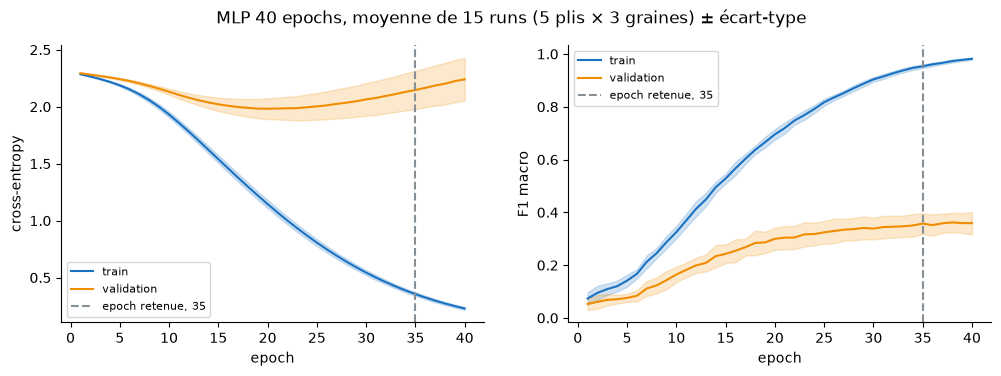

In [35]:
# MLP avec les réglages communs : 40 epochs au plus, cinq folds, trois seeds, soit 15 runs.
evaluer_reseau('MLP 40 epochs', MoyenneMLP)
display(pd.DataFrame([resumer_courbe('MLP 40 epochs')]).set_index('Modèle').round(3).T)
tracer_courbes('MLP 40 epochs')

> *Mes observations :*
>
> À 40 epochs, je retiens l’epoch 35, tandis que le maximum observé vaut 0,362 à l’epoch 38. Le gain final de 0,020 dépasse ma tolérance de 0,005.

Je prolonge donc l’expérience jusqu’au plafond prévu de 100 epochs, avec les autres réglages conservés. La perte de validation atteint son minimum à l’epoch 20, où le F1 vaut 0,300. Ces métriques mesurent des aspects différents, car le F1 dépend des classes prédites et la perte des probabilités cibles.

Modèle,MLP 40 epochs,MLP
Epochs,40,100
Epoch retenue,35,62
Epoch du maximum,38,80
F1 validation maximal,0.362,0.381
Epoch de loss validation minimale,20,20
F1 validation à cette epoch,0.3,0.3
Gain des 10 dernières epochs,0.02,-0.002
Monte encore,True,False


,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP 40 epochs,135370,35,0.953,0.358,0.016,0.041,0.596,25.016
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,62.422


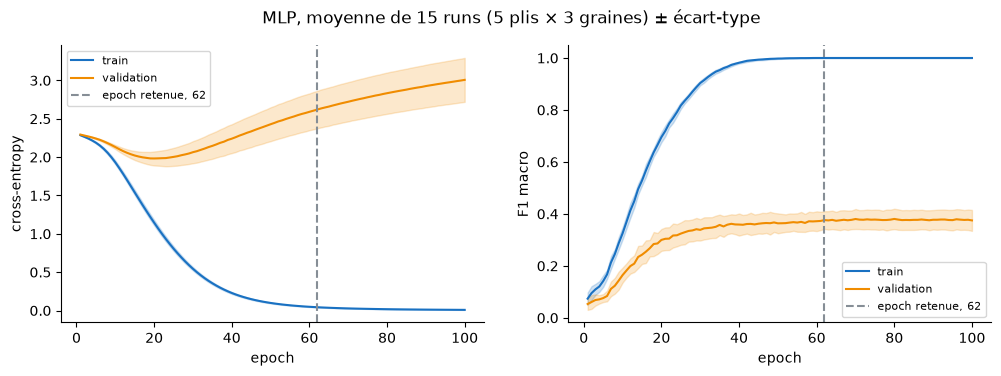

In [36]:
# MLP avec 100 epochs au plus, les autres réglages inchangés, face à la version à 40 epochs.
REGLAGES_MLP = dict(REGLAGES, epochs_max=100)
evaluer_reseau('MLP', MoyenneMLP, REGLAGES_MLP)
noms_mlp = ['MLP 40 epochs', 'MLP']
display(pd.DataFrame([resumer_courbe(nom) for nom in noms_mlp]).set_index('Modèle').round(3).T)
display(pd.DataFrame([ligne_modele(nom) for nom in noms_mlp]).set_index('Modèle').round(3))
tracer_courbes('MLP')

> *Mes observations :*
>
> Avec le plafond de 100 epochs, l’epoch retenue passe à 62 et le F1 moyen à 0,376. Le gain final vaut −0,002, donc ma règle ne demande pas de nouvelle prolongation.

À l’epoch retenue, le F1 train arrondi vaut 1,000 et l’écart train/validation 0,624. La perte de validation remonte malgré un F1 assez stable. Cela suggère une dégradation des probabilités cibles, sans isoler les seules erreurs.

Je moyenne les cinq écarts-types entre graines calculés dans chaque pli, ce qui donne 0,031. L’écart-type des cinq scores moyennés par pli vaut 0,016. Ces résumés ne décomposent pas la variance en causes distinctes.

Je ne peux pas en déduire que l’initialisation explique davantage le score que le découpage.

Je compare le MLP à LinearSVC commun pli par pli. Ils partagent le tokenizer et les répliques de validation, mais les réseaux tronquent certaines séquences et TF–IDF garde des bigrammes. H1 tient si l’écart moyen de F1 macro reste sous 0,05.

In [37]:
# Écart fold par fold entre le MLP et la référence ML, puis les deux résumés.
ecarts_mlp = ecarts_par_fold('LinearSVC commun', 'MLP')
display(ecarts_mlp)
print(decrire_ecarts(ecarts_mlp))
display(pd.concat({nom: resumer(nom) for nom in ('LinearSVC commun', 'MLP')}))

,LinearSVC commun,MLP,Écart
Fold,,,
1,0.453,0.384,-0.069
2,0.423,0.356,-0.068
3,0.472,0.364,-0.108
4,0.518,0.381,-0.138
5,0.509,0.396,-0.112


Folds gagnés par le modèle : 0 sur 5, écart moyen -0.099


F1 train  F1 macro  Accuracy  Temps (s)
LinearSVC commun moyenne          1.0     0.475     0.484      0.062
                 écart-type       0.0     0.039     0.038      0.001
MLP              moyenne          1.0     0.376     0.387      4.161
                 écart-type       0.0     0.016     0.018      0.052

> *Mes observations :*
>
> Le MLP perd les cinq plis, avec un écart moyen de −0,099 face à LinearSVC commun. Cela dépasse le seuil de 0,05 annoncé dans H1.

> *Ma conclusion :*
>
> H1 n’est pas vérifiée dans cette comparaison. Le tokenizer est partagé, mais TF–IDF apporte aussi pondération et bigrammes, tandis que le MLP apprend des embeddings sur les séquences tronquées.

> *Mon hypothèse :*
>
> La moyenne donne la même pondération explicite à chaque position conservée et pourrait diluer certains indices rares. Les embeddings peuvent toutefois apprendre des amplitudes et des directions différentes. Les analyses suivantes examineront cette piste sans la confondre avec une preuve.

Je précise « proche de 1 » par un F1 train d’au moins 0,99. Pour conserver le sens de H3, « moins de 20 epochs » signifie atteindre ce seuil avant l’epoch 20. Je compte les runs concernés et mesure séparément l’écart à l’epoch retenue.

In [38]:
# Mémorisation (H3) : première epoch à F1 train ≥ 0,99 dans chaque run, puis écart par fold.
SEUIL_MEMORISATION = 0.99
EPOCH_H3 = 20  # Délai prévu par H3


def premiere_epoch(courbe: pd.Series, seuil: float) -> float:
    """Première epoch où la courbe atteint le seuil, NaN si elle ne l'atteint jamais."""
    atteintes = courbe.index[courbe >= seuil]
    return atteintes[0] if len(atteintes) else float('nan')


# Délai de mémorisation sur les 15 runs, puis F1 train moyen au délai de H3
premieres = pd.Series([premiere_epoch(run['historique']['F1 train'], SEUIL_MEMORISATION)
                       for run in resultats['MLP']['runs']])
f1_train_h3 = courbes_moyennes('MLP').loc[EPOCH_H3, ('F1 train', 'mean')]

# Écart train/validation à l'epoch retenue, seeds moyennées dans chaque fold
par_fold_mlp = resultats['MLP']['folds'].groupby(level='Fold').mean()
par_fold_mlp['Écart'] = par_fold_mlp['F1 train'] - par_fold_mlp['F1 macro']

print(f'Runs qui atteignent F1 train ≥ {SEUIL_MEMORISATION} : {premieres.notna().sum()} '
      f'sur {len(premieres)}')
print(f'Première epoch : moyenne {premieres.mean():.1f}, de {premieres.min():.0f} '
      f'à {premieres.max():.0f}')
print(f'F1 train moyen à l’epoch {EPOCH_H3} : {f1_train_h3:.3f}')
print(f'Runs atteignant le seuil avant 20 epochs : {(premieres < EPOCH_H3).sum()}')
display(par_fold_mlp[['F1 train', 'F1 macro', 'Écart']].round(3))

Runs qui atteignent F1 train ≥ 0.99 : 15 sur 15
Première epoch : moyenne 43.3, de 41 à 49
F1 train moyen à l’epoch 20 : 0.695
Runs atteignant le seuil avant 20 epochs : 0


,F1 train,F1 macro,Écart
Fold,,,
1,1.0,0.384,0.616
2,1.0,0.356,0.644
3,1.0,0.364,0.636
4,1.0,0.381,0.619
5,1.0,0.396,0.604


> *Mes observations :*
>
> Les quinze runs atteignent 0,99 entre les epochs 41 et 49, donc aucun ne respecte le délai de H3. À l’epoch 20, le F1 moyen vaut 0,695.

L’écart à l’epoch retenue va de 0,604 à 0,644. H3 est soutenue pour cet écart, mais contredite pour le délai prévu.

> *Mon hypothèse :*
>
> Le réglage d’Adam et la moyenne pourraient contribuer à cet ajustement lent. Le taux `1e-3` ne borne pas à lui seul les déplacements de poids. Le LSTM apportera une comparaison d’architecture, sans isoler la moyenne comme cause unique.

Je compare la largeur cachée 64 à 32 et à 128, avec le même plafond de 100 epochs. La dimension des embeddings reste fixée à 64. Changer la largeur cachée modifie aussi les poids aléatoires et l’apprentissage. Je regarde le F1, ses dispersions et l’écart train/validation.

> *Mon hypothèse :* la largeur change peu le F1 macro, car la couche cachée ne porte que 3,1 % des paramètres et le MLP mémorise déjà le train.

,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP largeur 32,132970,67,0.999,0.387,0.022,0.031,0.612,63.929
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,62.422
MLP largeur 128,140170,70,1.000,0.378,0.044,0.021,0.622,64.719


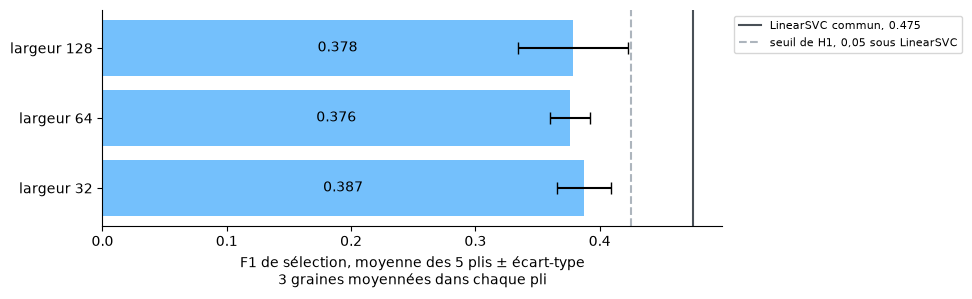

In [39]:
# Largeur de la couche cachée : 32 et 128 face à 64, avec le même plafond de 100 epochs.
LARGEURS = {'MLP largeur 32': 32, 'MLP': 64, 'MLP largeur 128': 128}
for nom, largeur in LARGEURS.items():
    if nom not in resultats:  # La largeur 64 est le MLP déjà entraîné
        evaluer_reseau(nom, MoyenneMLP, dict(REGLAGES_MLP, largeur_cachee=largeur))
table_largeur = pd.DataFrame([ligne_modele(nom) for nom in LARGEURS]).set_index('Modèle')
display(table_largeur.round(3))

# F1 macro par largeur, écart-type entre folds, et la référence ML avec le seuil de H1
f1_svc = score_par_fold('LinearSVC commun').mean()
fig, ax = plt.subplots(figsize=(8, 2.8))
barres = ax.barh([f'largeur {largeur}' for largeur in LARGEURS.values()],
                 table_largeur['F1 macro'],
                 xerr=table_largeur['Écart-type entre folds'], color='#74c0fc', capsize=4)
ax.bar_label(barres, labels=[f'{f1:.3f}' for f1 in table_largeur['F1 macro']],
             label_type='center')
ax.axvline(f1_svc, color='#495057', label=f'LinearSVC commun, {f1_svc:.3f}')
ax.axvline(f1_svc - 0.05, linestyle='--', color='#adb5bd', label='seuil de H1, 0,05 sous LinearSVC')
ax.set_xlabel('F1 de sélection, moyenne des 5 plis ± écart-type\n'
              '3 graines moyennées dans chaque pli')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Les largeurs 32, 64 et 128 donnent des F1 moyens de 0,387, 0,376 et 0,378. Les paramètres vont de 132 970 à 140 170, avec des écarts train/validation de 0,612 à 0,624.

Je garde la largeur 64 commune aux réseaux pour comparer leurs architectures. Les écarts observés sont modestes, sans test d’équivalence entre largeurs. Comparer leur taille à un écart-type ne suffit pas à conclure qu’ils sont du bruit.

> *Ma conclusion :*
>
> Le MLP atteint 0,376 de F1 moyen à l’epoch retenue 62 et reste sous le seuil de H1. L’ajustement du train est élevé, mais plus tardif que prévu dans H3.

Je garde les trois graines pour décrire la variation des runs déjà prévus. Le LSTM et le GRU partiront du plafond de 40 epochs avec le même critère de prolongation.

### 3.5 Embeddings + LSTM

> *Mon hypothèse :*
>
> Lire la séquence apporte des indices que la moyenne perd, malgré le faible nombre de répliques. Si cette attente se vérifie, le LSTM dépasse le MLP et le mélange des mots le dégrade.

Je conserve une couche unidirectionnelle et l’état final après le dernier token réel. La classification d’une réplique entière n’impose pas cette direction unique, mais je commence par cette architecture. L’essai bidirectionnel reste une piste conditionnelle, réexaminée en section 4.3.

Le LSTM hérite lui aussi de `ClassifieurTokens`, et sa représentation est l'état après le dernier token réel (section 2.2). J'écris une classe récurrente dont la cellule est un paramètre, donc le GRU de la section 3.6 ne changera que ce paramètre. Je contrôle la sortie et je compare ses paramètres à ceux du MLP.

In [40]:
# Un réseau récurrent à une couche : embeddings, LSTM ou GRU, état final, dix scores de classe.


class ReseauRecurrent(ClassifieurTokens):
    """Une couche récurrente unidirectionnelle, puis l'état après le dernier token réel."""

    def __init__(self, taille_vocabulaire: int, reglages: dict, cellule: type = nn.LSTM):
        super().__init__(taille_vocabulaire, reglages, reglages['largeur_cachee'])
        self.rnn = cellule(reglages['dim_embedding'], reglages['largeur_cachee'], batch_first=True)

    def representer(self, vecteurs, masque, longueurs):
        return etat_final(self.rnn, vecteurs, longueurs)


# Contrôle sur les quatre répliques du fold 1 : forme de la sortie, puis paramètres face au MLP
fixer_seed(RANDOM_STATE)
lstm_1 = ReseauRecurrent(len(vocabulaire_1), REGLAGES).to(device)
with torch.no_grad():
    print(f'Sortie sur 4 répliques : forme {tuple(lstm_1(batch_1).shape)}')
blocs = pd.DataFrame({'MLP': parametres_par_bloc(mlp_1), 'LSTM': parametres_par_bloc(lstm_1)})
blocs = blocs.fillna(0).astype(int)
blocs.loc['total'] = blocs.sum()
display(blocs.rename_axis('Bloc, fold 1'))

Sortie sur 4 répliques : forme (4, 10)


,MLP,LSTM
"Bloc, fold 1",,
embeddings,130560,130560
sortie,650,650
cachee,4160,0
rnn,0,33280
total,135370,164490


> *Mes observations :*
>
> Le LSTM rend dix scores par réplique. Sa couche récurrente compte 33 280 paramètres, soit huit fois la couche cachée du MLP. Elle calcule trois portes et une mémoire candidate à partir du token et de l’état précédent.

La taille des embeddings reste la même. Le total passe de 135 370 paramètres pour le MLP à 164 490 pour le LSTM sur le premier pli.

Je lance le LSTM avec les réglages communs, donc 40 epochs au plus et 15 runs. Puis j'applique le critère de plafond de la section 3.4 avant de lire ses scores.

Modèle,MLP,LSTM
Epochs,100,40
Epoch retenue,62,27
Epoch du maximum,80,27
F1 validation maximal,0.381,0.206
Epoch de loss validation minimale,20,6
F1 validation à cette epoch,0.3,0.116
Gain des 10 dernières epochs,-0.002,0.004
Monte encore,False,False


,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,62.422
LSTM,164490,27,0.998,0.206,0.026,0.024,0.792,499.207


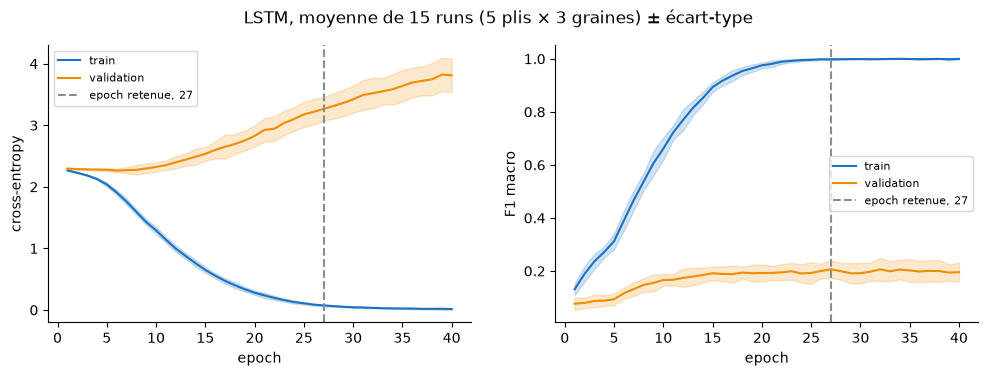

In [41]:
# LSTM avec les réglages communs : 40 epochs au plus, cinq folds, trois seeds.
evaluer_reseau('LSTM', ReseauRecurrent)
noms_reseaux = ['MLP', 'LSTM']
display(pd.DataFrame([resumer_courbe(nom) for nom in noms_reseaux]).set_index('Modèle').round(3).T)
display(pd.DataFrame([ligne_modele(nom) for nom in noms_reseaux]).set_index('Modèle').round(3))
tracer_courbes('LSTM')

> *Mes observations :*
>
> Le LSTM atteint son maximum moyen de 0,206 à l’epoch 27, également retenue. Le gain final de 0,004 reste sous le critère de prolongation.

Je conserve donc le plafond de 40 epochs. L’écart train/validation vaut 0,792 et la perte de validation atteint son minimum dès l’epoch 6. Ce résultat décrit les entraînements effectués, sans montrer qu’un autre budget ou réglage échouerait aussi.

Je compare le LSTM au MLP fold par fold, car H2 prévoit que lire l'ordre des mots le fait passer devant. Je le place aussi face à `LinearSVC commun`, la référence ML.

In [42]:
# Écarts fold par fold du LSTM face au MLP (H2), puis face à la référence ML.
for reference in ('MLP', 'LinearSVC commun'):
    ecarts_lstm = ecarts_par_fold(reference, 'LSTM')
    display(ecarts_lstm)
    print(decrire_ecarts(ecarts_lstm))

,MLP,LSTM,Écart
Fold,,,
1,0.384,0.217,-0.167
2,0.356,0.189,-0.167
3,0.364,0.226,-0.138
4,0.381,0.171,-0.210
5,0.396,0.229,-0.167


Folds gagnés par le modèle : 0 sur 5, écart moyen -0.170


,LinearSVC commun,LSTM,Écart
Fold,,,
1,0.453,0.217,-0.236
2,0.423,0.189,-0.234
3,0.472,0.226,-0.245
4,0.518,0.171,-0.348
5,0.509,0.229,-0.279


Folds gagnés par le modèle : 0 sur 5, écart moyen -0.268


> *Mes observations :*
>
> Le LSTM perd les cinq plis face au MLP, avec un écart moyen de −0,170. Son retard moyen face à LinearSVC commun vaut −0,268.

L’avantage attendu du LSTM n’apparaît pas. H2 reste ouverte, car ce résultat mêle représentation, paramètres et optimisation. Le mélange des tokens examinera une autre conséquence de cette hypothèse.

Je compare les délais d’ajustement du train avec les mêmes seuils pour le MLP et le LSTM. Les réglages communs limitent les différences de protocole. Ils ne rendent pas les deux réseaux identiques à l’exception de la moyenne.

In [43]:
# Mémorisation (H3) du MLP et du LSTM : délai pour atteindre un F1 train de 0,99, écart final.


def ligne_memorisation(nom: str) -> dict:
    """Première epoch à F1 train ≥ 0,99 sur les runs, F1 train à l'epoch 20, écart retenu."""
    premieres = pd.Series([premiere_epoch(run['historique']['F1 train'], SEUIL_MEMORISATION)
                           for run in resultats[nom]['runs']])
    f1_h3 = courbes_moyennes(nom).loc[EPOCH_H3, ('F1 train', 'mean')]
    par_fold = resultats[nom]['folds'].groupby(level='Fold').mean()
    return {'Modèle': nom, 'Runs au seuil': f'{premieres.notna().sum()} sur {len(premieres)}',
            'Runs avant 20 epochs': int((premieres < EPOCH_H3).sum()),
            'Première epoch moyenne': premieres.mean(), 'Première epoch minimale': premieres.min(),
            'Première epoch maximale': premieres.max(), f'F1 train à l’epoch {EPOCH_H3}': f1_h3,
            'Écart train/validation': (par_fold['F1 train'] - par_fold['F1 macro']).mean()}


memorisation = pd.DataFrame([ligne_memorisation(nom) for nom in noms_reseaux])
display(memorisation.set_index('Modèle').round(3))

,Runs au seuil,Runs avant 20 epochs,Première epoch moyenne,Première epoch minimale,Première epoch maximale,F1 train à l’epoch 20,Écart train/validation
Modèle,,,,,,,
MLP,15 sur 15,0,43.267,41,49,0.695,0.624
LSTM,15 sur 15,0,22.667,21,26,0.975,0.792


> *Mes observations :*
>
> Le LSTM atteint 0,99 entre les epochs 21 et 26, contre 41 à 49 pour le MLP. Aucun de ces runs LSTM ne satisfait donc le délai strict de H3.

Son F1 train moyen vaut 0,975 à l’epoch 20 et son écart retenu 0,792. L’architecture s’ajuste plus tôt dans ces essais. Cela ne permet pas d’attribuer tout le délai du MLP à sa moyenne.

Je mesure la norme des gradients avant plafonnement et la proportion de batches concernés. Le seuil borne la norme transmise à Adam, sans borner directement le déplacement des poids. Je veux voir à quels moments cette intervention change les gradients transmis à l’optimiseur.

MLP : norme maximale 2.3, pic de la norme moyenne à l’epoch 21, 1.2 % des batches plafonnés, moyenne entre epochs et runs
LSTM : norme maximale 413.5, pic de la norme moyenne à l’epoch 22, 51.2 % des batches plafonnés, moyenne entre epochs et runs


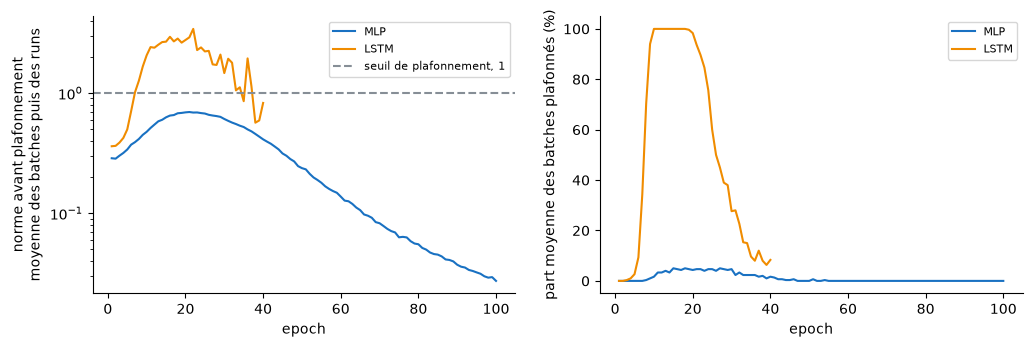

In [44]:
# Norme du gradient avant plafonnement et part des batches plafonnés, MLP face au LSTM.
COULEURS = {'LinearSVC commun': '#868e96', 'MLP': '#1971c2', 'LSTM': '#f08c00', 'GRU': '#2f9e44'}


def decrire_gradient(nom: str) -> str:
    """Norme maximale, epoch du pic de la norme moyenne et part des batches plafonnés."""
    courbes = courbes_moyennes(nom)
    historiques = pd.concat([run['historique'] for run in resultats[nom]['runs']])
    return (f'{nom} : norme maximale {historiques["norme maximale"].max():.1f}, pic de la norme '
            f'moyenne à l’epoch {courbes[("norme moyenne", "mean")].idxmax()}, '
            f'{pourcentage(historiques["part plafonnée"].sum(), len(historiques)):.1f} % '
            f'des batches plafonnés, moyenne entre epochs et runs')


def tracer_gradients(noms: list) -> None:
    """Norme moyenne avant plafonnement, en échelle log, et part des batches plafonnés."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    for nom in noms:
        courbes = courbes_moyennes(nom)
        axes[0].plot(courbes.index, courbes[('norme moyenne', 'mean')], color=COULEURS[nom],
                     label=nom)
        axes[1].plot(courbes.index, 100 * courbes[('part plafonnée', 'mean')],
                     color=COULEURS[nom], label=nom)
    axes[0].axhline(REGLAGES['clip_gradient'], linestyle='--', color='#868e96',
                    label='seuil de plafonnement, 1')
    axes[0].set(yscale='log', ylabel='norme avant plafonnement\nmoyenne des batches puis des runs')
    axes[1].set(ylabel='part moyenne des batches plafonnés (%)')
    for axe in axes:
        axe.set_xlabel('epoch')
        axe.legend(fontsize=8)
        axe.spines[['top', 'right']].set_visible(False)
    plt.show()


# Une ligne de résumé par réseau, puis les deux panneaux
for nom in noms_reseaux:
    print(decrire_gradient(nom))
tracer_gradients(noms_reseaux)

> *Mes observations :*
>
> La norme maximale enregistrée vaut 413,5 pour le LSTM, contre 2,3 pour le MLP. Les parts moyennes de batches plafonnés valent 51,2 % et 1,2 %.

Le plafonnement intervient davantage pour le LSTM dans ces runs. Ces normes ne localisent pas l’origine des grands gradients dans la récurrence. Sans essai sans plafonnement, je ne mesure pas son effet sur le score ni une garantie de stabilité.

Je compare l’accuracy par tranche de longueur pour chercher où le retard du LSTM apparaît. TF–IDF reçoit tous les tokens retenus par son analyseur, tandis que les réseaux partagent une troncature.

Les tranches ont des effectifs proches, mais pas nécessairement les mêmes classes ni les mêmes indices lexicaux. Cette comparaison décrit une association avec la longueur.

In [45]:
# Accuracy par tranche de longueur pour LinearSVC commun, MLP et LSTM, puis répliques tronquées.
NOMS_LONGUEUR = ['LinearSVC commun', 'MLP', 'LSTM']
longueurs = X_train.map(lambda texte: len(tokeniser(texte)))
tranches = pd.qcut(longueurs, 3)  # Trois tranches de même effectif


def predictions_seed(nom: str, seed: int) -> pd.Series:
    """Prédictions de validation des cinq folds pour une seed, à l'epoch retenue."""
    epoch, predictions = resultats[nom]['epoch'], pd.Series(index=X_train.index, dtype=object)
    for run in resultats[nom]['runs']:
        if run['seed'] == seed:
            validation = folds[run['fold'] - 1]['validation']
            predictions.loc[validation] = [CLASSES[i] for i in run['predictions'][epoch]]
    return predictions


def justesse_par_tranche(nom: str) -> pd.Series:
    """Accuracy par tranche de longueur, moyennée sur les seeds pour un réseau."""
    if resultats[nom]['famille'] == 'ML':
        jeux = [resultats[nom]['predictions']]
    else:
        jeux = [predictions_seed(nom, seed) for seed in REGLAGES['seeds']]
    justes = pd.concat([jeu == y_train for jeu in jeux], axis=1).mean(axis=1)
    return justes.groupby(tranches, observed=True).mean()


def table_justesse(noms: list) -> pd.DataFrame:
    """Accuracy par tranche de longueur, une colonne par modèle."""
    table = pd.DataFrame({nom: justesse_par_tranche(nom) for nom in noms})
    table.index = [f'{int(t.left) + 1} à {int(t.right)} tokens' for t in table.index]
    return table


# Accuracy par tranche, effectifs, puis répliques de validation tronquées par fold
justesse = table_justesse(NOMS_LONGUEUR)
tronquees = [mesurer_troncature(fold, QUANTILE_LONGUEUR)['Répliques tronquées validation (%)']
             for fold in folds]
print(f'Répliques par tranche : {tranches.value_counts().sort_index().tolist()}')
print(f'Répliques de validation tronquées : de {min(tronquees):.2f} % à {max(tronquees):.2f} % '
      f'selon le fold')
display(justesse.round(3))

Répliques par tranche : [259, 261, 249]
Répliques de validation tronquées : de 0.00 % à 2.61 % selon le fold


,LinearSVC commun,MLP,LSTM
10 à 20 tokens,0.375,0.308,0.223
21 à 47 tokens,0.494,0.379,0.206
48 à 581 tokens,0.586,0.477,0.221


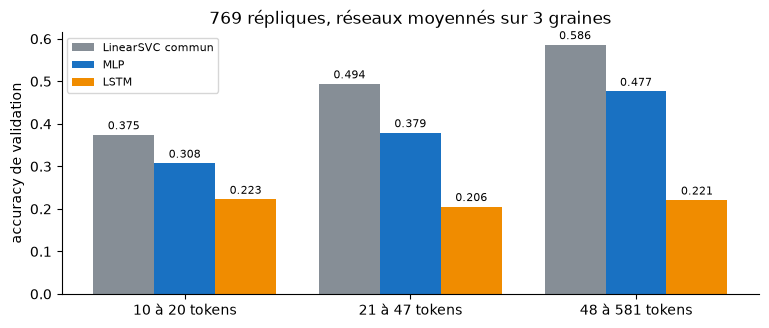

In [46]:
# Accuracy de validation par tranche de longueur, un groupe de barres par tranche.


def tracer_justesse(justesse: pd.DataFrame) -> None:
    """Un groupe de barres par tranche, une barre par modèle, valeurs sur les barres."""
    largeur, positions = 0.81 / justesse.shape[1], np.arange(len(justesse))
    fig, ax = plt.subplots(figsize=(9, 3.4))
    for rang, nom in enumerate(justesse):
        decalage = (rang - (justesse.shape[1] - 1) / 2) * largeur  # Barres centrées sur la tranche
        barres = ax.bar(positions + decalage, justesse[nom], largeur, color=COULEURS[nom],
                        label=nom)
        ax.bar_label(barres, labels=[f'{valeur:.3f}' for valeur in justesse[nom]], padding=2,
                     fontsize=8)
    ax.set_xticks(positions, justesse.index)
    ax.set_ylabel('accuracy de validation')
    ax.set_title('769 répliques, réseaux moyennés sur 3 graines')
    ax.legend(fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    plt.show()


tracer_justesse(justesse)

> *Mes observations :*
>
> Les tranches comptent 259, 261 et 249 répliques. L’accuracy de LinearSVC passe de 0,375 à 0,586 et celle du MLP de 0,308 à 0,477, tandis que le LSTM varie de 0,206 à 0,223.

Le LSTM reste faible même sur les répliques courtes. La troncature touche au plus 2,61 % des répliques de validation d’un pli. Ces observations ne séparent pas oubli, difficulté d’optimisation et composition des tranches.

> *Ma conclusion :*
>
> Dans ces essais, le LSTM ajuste fortement le train et obtient un F1 de validation inférieur au MLP dans chaque pli. Ses grandes normes de gradient et son profil selon la longueur motivent des questions, sans en établir la cause.

Je conserve les réglages pour comparer le GRU. Cette comparaison portera sur la cellule récurrente, ses paramètres et les résultats mesurés.

### 3.6 Embeddings + GRU face au LSTM

> *Mon hypothèse :*
>
> Le GRU suffit pour ces répliques avec moins de paramètres qu’un LSTM de même largeur, comme le prévoit H4.

Je conserve les dimensions et les réglages, puis vérifie l’égalité des poids des blocs communs à l’initialisation. La cellule GRU change les équations récurrentes et le nombre de paramètres, pas seulement leurs valeurs.

Le GRU reprend la classe `ReseauRecurrent` de la section 3.5 avec une autre cellule, donc tout le reste du réseau est commun. Je vérifie qu'à seed égale ses embeddings et sa couche de sortie partent des mêmes poids que ceux du LSTM. Puis je compte ses paramètres par bloc.

In [47]:
# Le GRU : la classe récurrente de la section 3.5 avec une cellule GRU, contrôlée sur le fold 1.
GRU = partial(ReseauRecurrent, cellule=nn.GRU)

# Même seed que lstm_1 : les blocs communs doivent partir des mêmes poids
fixer_seed(RANDOM_STATE)
gru_1 = GRU(len(vocabulaire_1), REGLAGES).to(device)
with torch.no_grad():
    print(f'Sortie sur 4 répliques : forme {tuple(gru_1(batch_1).shape)}')
for bloc in ('embeddings', 'sortie'):
    paires = zip(getattr(lstm_1, bloc).parameters(), getattr(gru_1, bloc).parameters())
    print(f'{bloc} identiques au LSTM : {all(torch.equal(a, b) for a, b in paires)}')

# Paramètres par bloc, LSTM face au GRU
blocs = pd.DataFrame({'LSTM': parametres_par_bloc(lstm_1), 'GRU': parametres_par_bloc(gru_1)})
blocs.loc['total'] = blocs.sum()
display(blocs.rename_axis('Bloc, fold 1'))

Sortie sur 4 répliques : forme (4, 10)
embeddings identiques au LSTM : True
sortie identiques au LSTM : True


,LSTM,GRU
"Bloc, fold 1",,
embeddings,130560,130560
sortie,650,650
rnn,33280,24960
total,164490,156170


> *Mes observations :*
>
> Les embeddings et la sortie sont identiques au départ pour les deux modèles contrôlés. Les équations de récurrence diffèrent, avec deux portes et un état candidat pour le GRU.

Sa couche récurrente compte 24 960 paramètres contre 33 280 pour le LSTM. Le total passe de 164 490 à 156 170 sur le premier pli. Ce comptage ne mesure pas directement le temps de calcul.

Je lance le GRU avec les mêmes réglages que le LSTM, donc 40 epochs au plus et 15 runs. Puis j'applique le critère de plafond de la section 3.4.

Modèle,LSTM,GRU
Epochs,40,40
Epoch retenue,27,31
Epoch du maximum,27,31
F1 validation maximal,0.206,0.206
Epoch de loss validation minimale,6,8
F1 validation à cette epoch,0.116,0.146
Gain des 10 dernières epochs,0.004,0.001
Monte encore,False,False


,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,62.422
LSTM,164490,27,0.998,0.206,0.026,0.024,0.792,499.207
GRU,156170,31,1.000,0.206,0.027,0.022,0.794,472.251


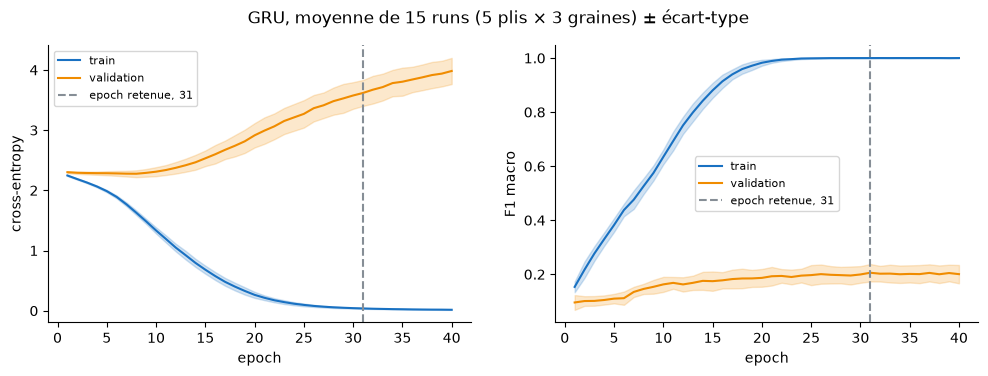

In [48]:
# GRU avec les réglages communs : 40 epochs au plus, cinq folds, trois seeds.
evaluer_reseau('GRU', GRU)
RESEAUX = ['MLP', 'LSTM', 'GRU']
display(pd.DataFrame([resumer_courbe(nom) for nom in RESEAUX[1:]]).set_index('Modèle').round(3).T)
display(pd.DataFrame([ligne_modele(nom) for nom in RESEAUX]).set_index('Modèle').round(3))
tracer_courbes('GRU')

> *Mes observations :*
>
> Le GRU atteint un F1 moyen arrondi de 0,206 à l’epoch retenue 31. Le gain final vaut 0,001, donc le critère ne demande pas de prolongation au-delà de 40 epochs.

Son écart train/validation vaut 0,794. La proximité avec les chiffres du LSTM invite à comparer les écarts par pli et les temps, sans conclure à une identité des modèles.

Je sépare les trois aspects de H4, soit paramètres, F1 et durée. Un écart de score inférieur à la dispersion entre graines sera un repère descriptif, sans test d’équivalence.

Le temps par epoch inclut les évaluations du train et de la validation. Il décrit cette boucle sur ce CPU, avec les plafonds utilisés.

In [49]:
# H4 : écart fold par fold du GRU face au LSTM, puis temps d'une epoch et taille de chaque réseau.


def temps_par_epoch(nom: str) -> float:
    """Temps total des runs divisé par leur nombre total d'epochs, évaluation comprise."""
    runs = resultats[nom]['runs']
    return sum(run['temps'] for run in runs) / sum(len(run['historique']) for run in runs)


ecarts_gru = ecarts_par_fold('LSTM', 'GRU')
display(ecarts_gru)
print(decrire_ecarts(ecarts_gru))
for nom in RESEAUX:
    print(f'{nom} : {temps_par_epoch(nom):.2f} s par epoch, '
          f'{resultats[nom]["parametres"]} paramètres sur le fold 1')

,LSTM,GRU,Écart
Fold,,,
1,0.217,0.212,-0.005
2,0.189,0.190,0.001
3,0.226,0.242,0.016
4,0.171,0.170,-0.000
5,0.229,0.214,-0.015


Folds gagnés par le modèle : 2 sur 5, écart moyen -0.001
MLP : 0.04 s par epoch, 135370 paramètres sur le fold 1
LSTM : 0.83 s par epoch, 164490 paramètres sur le fold 1
GRU : 0.79 s par epoch, 156170 paramètres sur le fold 1


> *Mes observations :*
>
> Le GRU gagne deux plis et l’écart moyen arrondi vaut −0,001 face au LSTM. Les durées par epoch sont affichées ci-dessus, avec l’évaluation incluse.

> *Ma conclusion :*
>
> La réduction du nombre de paramètres prévue dans H4 est observée. Les scores sont proches, sans équivalence démontrée. Les temps mesurés ne suffisent pas à établir un avantage de vitesse reproductible.

> *Mon hypothèse :*
>
> Le traitement séquentiel pourrait peser davantage que la différence de portes dans ces durées. Je n’ai pas isolé ces coûts.

Je reprends la mémorisation de la section 3.5 avec le GRU, car H3 vaut pour les trois réseaux.

In [50]:
# Mémorisation (H3) des trois réseaux : délai pour un F1 train de 0,99 et écart final.
display(pd.DataFrame([ligne_memorisation(nom) for nom in RESEAUX]).set_index('Modèle').round(3))

,Runs au seuil,Runs avant 20 epochs,Première epoch moyenne,Première epoch minimale,Première epoch maximale,F1 train à l’epoch 20,Écart train/validation
Modèle,,,,,,,
MLP,15 sur 15,0,43.267,41,49,0.695,0.624
LSTM,15 sur 15,0,22.667,21,26,0.975,0.792
GRU,15 sur 15,1,21.467,19,24,0.983,0.794


> *Mes observations :*
>
> Le GRU atteint 0,99 entre les epochs 19 et 24, à 21,5 en moyenne. Un seul run sur quinze respecte le délai strict de H3, contre aucun pour le MLP et le LSTM.

L’écart train/validation vaut 0,794. H3 décrit bien un ajustement élevé et un grand écart, mais son délai ne vaut pas pour tous les runs récurrents. Le délai du MLP reste plus long dans cette comparaison.

Je reprends les mêmes mesures de gradient pour le GRU. Une norme plus faible pourrait rendre le plafonnement moins fréquent. Elle ne suffirait pas à démontrer une meilleure stabilité générale.

MLP : norme maximale 2.3, pic de la norme moyenne à l’epoch 21, 1.2 % des batches plafonnés, moyenne entre epochs et runs
LSTM : norme maximale 413.5, pic de la norme moyenne à l’epoch 22, 51.2 % des batches plafonnés, moyenne entre epochs et runs
GRU : norme maximale 101.9, pic de la norme moyenne à l’epoch 19, 28.2 % des batches plafonnés, moyenne entre epochs et runs


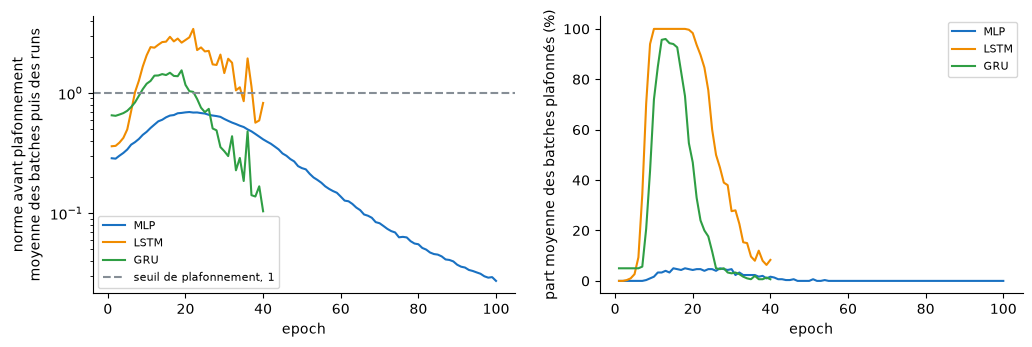

In [51]:
# Norme du gradient avant plafonnement et part des batches plafonnés pour les trois réseaux.
for nom in RESEAUX:
    print(decrire_gradient(nom))
tracer_gradients(RESEAUX)

> *Mes observations :*
>
> La norme maximale vaut 101,9 pour le GRU contre 413,5 pour le LSTM. Les parts moyennes de batches plafonnés valent 28,2 % et 51,2 %.

Le plafonnement intervient moins souvent pour le GRU dans ces entraînements. Je conserve cette observation comme un diagnostic local, sans attribuer sa cause au nombre de portes ni son effet au score.

L’accuracy du LSTM varie peu entre les trois tranches observées. Je place le GRU dans le même graphique pour comparer leurs profils sur les mêmes groupes de répliques.

,LinearSVC commun,MLP,LSTM,GRU
10 à 20 tokens,0.375,0.308,0.223,0.218
21 à 47 tokens,0.494,0.379,0.206,0.209
48 à 581 tokens,0.586,0.477,0.221,0.213


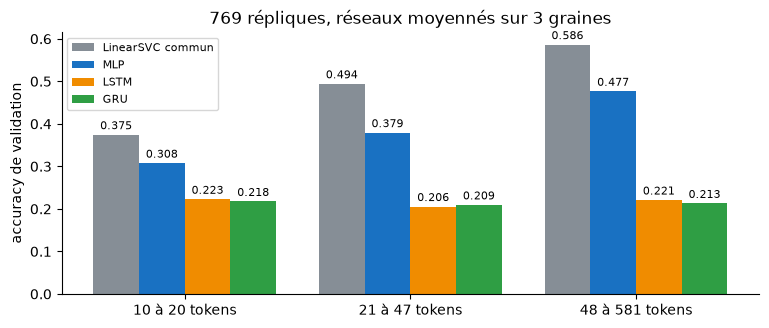

In [52]:
# Accuracy par tranche de longueur avec le GRU, face aux trois modèles de la section 3.5.
justesse_gru = table_justesse(NOMS_LONGUEUR + ['GRU'])
display(justesse_gru.round(3))
tracer_justesse(justesse_gru)

> *Mes observations :*
>
> L’accuracy du GRU varie de 0,209 à 0,218 entre les tranches, contre 0,206 à 0,223 pour le LSTM. LinearSVC et le MLP ont des scores plus élevés dans la tranche longue.

Les deux cellules récurrentes ont ici un profil proche. Cela ne suffit pas à exclure un effet de leur architecture avec d’autres réglages.

> *Ma conclusion :*
>
> Le GRU obtient un F1 moyen de 0,206 à l’epoch 31, proche de celui du LSTM, avec moins de paramètres. Je poursuis les expériences avec ce réseau, le plus petit des deux récurrents testés.

Ce choix ne démontre ni son équivalence au LSTM ni une meilleure généralisation. Les deux réseaux restent environ 0,17 sous le MLP dans les essais réalisés.

## 4. Évaluation, erreurs et conclusions

### 4.1 Comparer la généralisation

Je rassemble les scores de sélection, puis les prédictions sur les mêmes répliques. Les écarts-types décrivent la dispersion des cinq moyennes de plis pour les réseaux. Ils ne constituent pas des intervalles de confiance ni des tests de différence.

Je regarde aussi les erreurs communes et les résultats par classe. Ces lectures préciseront les écarts, tout en gardant la dépendance des plis et la sélection des epochs dans leurs limites.

Je rassemble d'abord les six modèles des sections 3.2 à 3.6 dans un seul tableau. Pour chacun, je reprends F1 macro et accuracy moyens, leur écart-type entre folds, l'epoch retenue, la taille et le temps total. Je compte aussi les poids de LinearSVC sur le fold 1, un par terme et par classe, pour comparer les tailles.

In [53]:
# Bilan des six modèles : F1 macro et accuracy entre folds, epoch retenue, taille et temps total.
MODELES = ['Majoritaire', 'LinearSVC TP1', 'LinearSVC commun', 'MLP', 'LSTM', 'GRU']


def poids_svc(reference: str) -> int:
    """Poids de LinearSVC ajusté sur le train du fold 1, un par terme et par classe."""
    fold = folds[0]
    svc = construire_svc(reference).fit(X_train.loc[fold['train']], y_train.loc[fold['train']])
    return svc.named_steps['svc'].coef_.size + svc.named_steps['svc'].intercept_.size


def ligne_bilan(nom: str) -> dict:
    """Scores moyens et écarts-types entre folds, seeds moyennées, puis epoch, taille et temps."""
    entree = resultats[nom]
    par_fold = entree['folds'].groupby(level='Fold').mean()
    return {'Modèle': nom, 'Famille': entree['famille'], 'F1 train': par_fold['F1 train'].mean(),
            'F1 macro': par_fold['F1 macro'].mean(), 'F1 écart-type': par_fold['F1 macro'].std(),
            'Accuracy': par_fold['Accuracy'].mean(),
            'Accuracy écart-type': par_fold['Accuracy'].std(),
            'Epoch retenue': entree.get('epoch'), 'Paramètres (fold 1)': entree.get('parametres'),
            'Temps total (s)': entree['folds']['Temps (s)'].sum()}


# Paramètres de LinearSVC, absents du registre ML
for nom, reference in REFERENCES.items():
    resultats[nom]['parametres'] = poids_svc(reference)

# Tableau de bilan, puis F1 macro par fold
bilan = pd.DataFrame([ligne_bilan(nom) for nom in MODELES]).set_index('Modèle')
bilan = bilan.astype({'Epoch retenue': 'Int64', 'Paramètres (fold 1)': 'Int64'})
f1_par_fold = pd.DataFrame({nom: score_par_fold(nom) for nom in MODELES})
display(bilan.round(3))
display(f1_par_fold.round(3))

,Famille,F1 train,F1 macro,F1 écart-type,Accuracy,Accuracy écart-type,Epoch retenue,Paramètres (fold 1),Temps total (s)
Modèle,,,,,,,,,
Majoritaire,ML,0.024,0.024,0.001,0.134,0.003,<NA>,<NA>,0.024
LinearSVC TP1,ML,1.000,0.482,0.039,0.492,0.041,<NA>,48620,0.389
LinearSVC commun,ML,1.000,0.475,0.039,0.484,0.038,<NA>,50260,0.308
MLP,DL,1.000,0.376,0.016,0.387,0.018,62,135370,62.422
LSTM,DL,0.998,0.206,0.026,0.216,0.024,27,164490,499.207
GRU,DL,1.000,0.206,0.027,0.213,0.026,31,156170,472.251


,Majoritaire,LinearSVC TP1,LinearSVC commun,MLP,LSTM,GRU
Fold,,,,,,
1,0.024,0.453,0.453,0.384,0.217,0.212
2,0.024,0.429,0.423,0.356,0.189,0.190
3,0.024,0.500,0.472,0.364,0.226,0.242
4,0.023,0.511,0.518,0.381,0.171,0.170
5,0.023,0.517,0.509,0.396,0.229,0.214


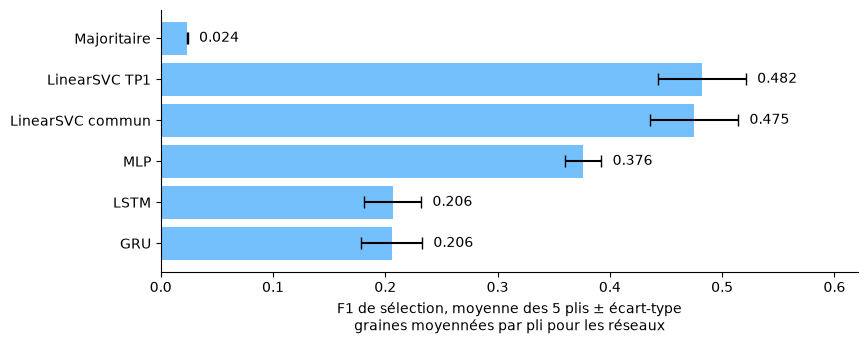

In [54]:
# F1 macro moyen de chaque modèle, avec l'écart-type entre folds.
fig, ax = plt.subplots(figsize=(9, 3.4))
moyennes, ecarts = bilan['F1 macro'][::-1], bilan['F1 écart-type'][::-1]
ax.barh(moyennes.index, moyennes, xerr=ecarts, color='#74c0fc', capsize=4)
for rang, (moyenne, ecart) in enumerate(zip(moyennes, ecarts)):
    ax.text(moyenne + ecart + 0.01, rang, f'{moyenne:.3f}', va='center')
ax.set_xlim(0, (moyennes + ecarts).max() + 0.1)
ax.set_xlabel('F1 de sélection, moyenne des 5 plis ± écart-type\n'
              'graines moyennées par pli pour les réseaux')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> LinearSVC TP1 atteint 0,482, LinearSVC commun 0,475, le MLP 0,376 et les deux réseaux récurrents environ 0,206. Parmi les modèles au tokenizer commun, ce classement apparaît dans chacun des cinq plis.

Les F1 train des modèles textuels sont proches de 1. Les durées totalisent cinq ajustements pour chaque référence ML et quinze runs pour chaque réseau, avec des plafonds différents. Elles ne représentent pas le coût d’un unique modèle final.

Le F1 moyen cache le signe de chaque écart, donc je reprends fold par fold la différence de chaque réseau avec `LinearSVC commun`.

In [55]:
# Écart signé de F1 macro de chaque réseau face à LinearSVC commun, fold par fold.
ecarts_reseaux = pd.DataFrame({nom: ecarts_par_fold('LinearSVC commun', nom)['Écart']
                               for nom in RESEAUX})
display(ecarts_reseaux)
for nom in RESEAUX:
    print(f'{nom} : {decrire_ecarts(ecarts_par_fold("LinearSVC commun", nom))}')

,MLP,LSTM,GRU
Fold,,,
1,-0.069,-0.236,-0.241
2,-0.068,-0.234,-0.234
3,-0.108,-0.245,-0.230
4,-0.138,-0.348,-0.348
5,-0.112,-0.279,-0.295


MLP : Folds gagnés par le modèle : 0 sur 5, écart moyen -0.099
LSTM : Folds gagnés par le modèle : 0 sur 5, écart moyen -0.268
GRU : Folds gagnés par le modèle : 0 sur 5, écart moyen -0.270


> *Mes observations :*
>
> Les trois réseaux perdent les cinq folds face à `LinearSVC commun`. Le MLP perd entre 0,068 et 0,138, et les deux réseaux récurrents entre 0,230 et 0,348. Le plus grand retard tombe au fold 4 pour les trois réseaux, car LinearSVC y obtient son meilleur score, 0,518, sans que les réseaux en profitent.

Je compte les cas où un seul des deux modèles a raison. Pour chaque graine, McNemar utilise les deux comptes discordants et teste leur symétrie sous une hypothèse binomiale.

Cette comparaison porte sur les succès de classification, pas directement sur le F1 macro. Je montre les trois résultats avant leur maximum. Ce maximum ne résume pas un test global de toutes les configurations.

In [56]:
# Répliques où un seul des deux modèles a raison, sur les 769, puis test de McNemar exact.
from scipy.stats import binomtest

PAIRES = [('LinearSVC commun', 'MLP'), ('LinearSVC commun', 'LSTM'),
          ('LinearSVC commun', 'GRU'), ('MLP', 'GRU')]


def jeux_predictions(nom: str) -> list:
    """Prédictions des 769 répliques, une série par seed pour un réseau, une seule en ML."""
    if resultats[nom]['famille'] == 'ML':
        return [resultats[nom]['predictions']]
    return [predictions_seed(nom, seed) for seed in REGLAGES['seeds']]


def comparer_paire(a: str, b: str, source=jeux_predictions, vrais=y_train) -> dict:
    """Comptes de désaccord moyennés sur les seeds et p-value de McNemar la plus forte."""
    jeux_a, jeux_b = source(a), source(b)
    comptes, p_values = [], []
    for rang in range(max(len(jeux_a), len(jeux_b))):  # Seeds appariées, le modèle ML répété
        juste_a = jeux_a[rang % len(jeux_a)] == vrais
        juste_b = jeux_b[rang % len(jeux_b)] == vrais
        seul_a, seul_b = int((juste_a & ~juste_b).sum()), int((juste_b & ~juste_a).sum())
        comptes.append({'A seul juste': seul_a, 'B seul juste': seul_b,
                        'Deux justes': int((juste_a & juste_b).sum()),
                        'Deux faux': int((~juste_a & ~juste_b).sum())})
        # Sans aucun désaccord, rien ne distingue les deux modèles
        p_values.append(binomtest(seul_a, seul_a + seul_b, 0.5).pvalue if seul_a + seul_b else 1.0)
    print(f'{a} / {b} : discordances par graine, sans correction de multiplicité')
    display(pd.DataFrame(comptes).assign(
        Graine=list(REGLAGES['seeds'])[:len(comptes)], p_value=p_values).set_index('Graine'))
    return {'A': a, 'B': b, **pd.DataFrame(comptes).mean().to_dict(),
            'p-value maximale': f'{max(p_values):.1e}'}


paires = pd.DataFrame([comparer_paire(a, b) for a, b in PAIRES]).set_index(['A', 'B'])
display(paires.round(1))

LinearSVC commun / MLP : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,146,73,226,324,9.153413e-07
43,149,67,223,330,2.443746e-08
44,156,87,216,310,1.133679e-05


LinearSVC commun / LSTM : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,272,70,100,327,3.029713e-29
43,273,64,99,333,7.161607e-32
44,261,55,111,342,3.067534e-33


LinearSVC commun / GRU : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,261,56,111,341,8.723952e-33
43,267,47,105,350,1.694162e-38
44,261,62,111,335,3.436698e-30


MLP / GRU : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,197,65,102,405,1.268939e-16
43,199,61,91,418,2.960598e-18
44,193,63,110,403,1.607792e-16


A seul juste  B seul juste  Deux justes  Deux faux  \
A                B                                                          
LinearSVC commun MLP          150.3          75.7        221.7      321.3   
                 LSTM         268.7          63.0        103.3      334.0   
                 GRU          263.0          55.0        109.0      342.0   
MLP              GRU          196.3          63.0        101.0      408.7   

                      p-value maximale  
A                B                      
LinearSVC commun MLP           1.1e-05  
                 LSTM          3.0e-29  
                 GRU           3.4e-30  
MLP              GRU           1.6e-16

> *Mes observations :*
>
> LinearSVC a seul raison sur 150,3 répliques en moyenne contre 75,7 pour le MLP. Les comptes fractionnaires viennent de la moyenne des trois graines, pas d’un effectif de répliques distinctes.

Les valeurs calculées de McNemar sont faibles, avec un maximum de 1,1 × 10⁻⁵ pour ce couple. Je les garde comme diagnostics exploratoires. Les plis partagent du train, les epochs ont été sélectionnées et plusieurs comparaisons sont examinées.

Je ne transforme donc pas ces valeurs en preuve d’un classement significatif en F1. Les 321,3 erreurs communes moyennes motivent l’analyse suivante.

Je superpose ensuite les courbes moyennes des trois réseaux, train en pointillé et validation en trait plein, car un score train seul ne dit rien de la généralisation.

MLP : epoch retenue 62, F1 validation 0.376, F1 train 1.000, F1 validation à la dernière epoch 0.375
LSTM : epoch retenue 27, F1 validation 0.206, F1 train 0.998, F1 validation à la dernière epoch 0.196
GRU : epoch retenue 31, F1 validation 0.206, F1 train 1.000, F1 validation à la dernière epoch 0.200


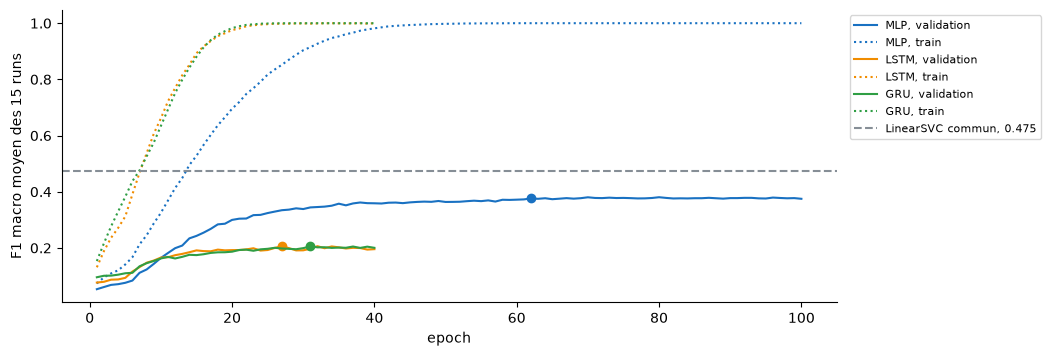

In [57]:
# F1 macro moyen de train et de validation des trois réseaux, avec leur epoch retenue.
f1_svc = score_par_fold('LinearSVC commun').mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
for nom in RESEAUX:
    courbes, epoch = courbes_moyennes(nom), resultats[nom]['epoch']
    validation, train = courbes[('F1 validation', 'mean')], courbes[('F1 train', 'mean')]
    ax.plot(courbes.index, validation, color=COULEURS[nom], label=f'{nom}, validation')
    ax.plot(courbes.index, train, color=COULEURS[nom], linestyle=':', label=f'{nom}, train')
    ax.plot(epoch, validation[epoch], 'o', color=COULEURS[nom])
    print(f'{nom} : epoch retenue {epoch}, F1 validation {validation[epoch]:.3f}, '
          f'F1 train {train[epoch]:.3f}, '
          f'F1 validation à la dernière epoch {validation.iloc[-1]:.3f}')
ax.axhline(f1_svc, linestyle='--', color=COULEURS['LinearSVC commun'],
           label=f'LinearSVC commun, {f1_svc:.3f}')
ax.set(xlabel='epoch', ylabel='F1 macro moyen des 15 runs')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Les réseaux atteignent un ajustement du train très élevé, mais les courbes de validation restent sous LinearSVC commun. À la dernière epoch, les F1 moyens valent 0,375, 0,196 et 0,200.

Ces valeurs restent proches de celles des epochs retenues. Le graphique montre des moyennes, qui peuvent masquer des trajectoires différentes selon le pli et la graine.

Je décompose les prédictions par classe pour distinguer précision et rappel. La précision décrit les prédictions d’un locuteur qui sont correctes, tandis que le rappel décrit ses répliques retrouvées.

Le F1 combine ces deux proportions. Je vérifierai aussi comment son calcul par classe se relie aux moyennes des plis.

LinearSVC commun                     MLP                \
                       Précision Rappel     F1 Précision Rappel     F1   
CORIOLANUS                 0.483  0.400  0.438     0.346  0.419  0.379   
DUKE VINCENTIO             0.465  0.590  0.520     0.479  0.527  0.501   
GLOUCESTER                 0.495  0.495  0.495     0.388  0.369  0.378   
ISABELLA                   0.560  0.438  0.491     0.389  0.286  0.329   
JULIET                     0.407  0.353  0.378     0.305  0.270  0.286   
KING RICHARD II            0.552  0.516  0.533     0.408  0.382  0.393   
LEONTES                    0.468  0.333  0.389     0.223  0.318  0.262   
MENENIUS                   0.435  0.553  0.487     0.507  0.424  0.461   
PETRUCHIO                  0.630  0.671  0.650     0.462  0.491  0.476   
ROMEO                      0.385  0.400  0.392     0.349  0.302  0.322   

                     LSTM                     GRU               Support  
                Précision Rappel     F1 Précision Rappel     F1          
CORIOLANUS          0.211  0.229  0.219     0.254  0.252  0.253      70  
DUKE VINCENTIO      0.262  0.280  0.269     0.259  0.263  0.259     100  
GLOUCESTER          0.175  0.184  0.179     0.187  0.191  0.189     103  
ISABELLA            0.169  0.188  0.178     0.150  0.146  0.147      64  
JULIET              0.205  0.167  0.183     0.213  0.196  0.203      68  
KING RICHARD II     0.235  0.231  0.233     0.203  0.183  0.192      62  
LEONTES             0.132  0.131  0.132     0.109  0.101  0.104      66  
MENENIUS            0.308  0.290  0.293     0.278  0.302  0.288      85  
PETRUCHIO           0.252  0.259  0.253     0.243  0.250  0.246      76  
ROMEO               0.192  0.169  0.178     0.203  0.200  0.201      75

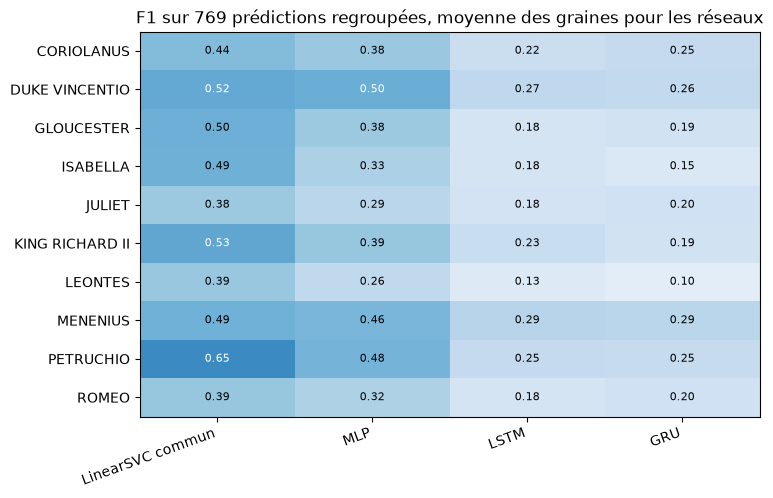

In [58]:
# Précision, rappel et F1 de chaque locuteur, moyennés sur les seeds, puis carte des F1.
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

MODELES_CLASSES = ['LinearSVC commun', 'MLP', 'LSTM', 'GRU']


def metriques_par_classe(nom: str, source=jeux_predictions, vrais=y_train) -> pd.DataFrame:
    """Précision, rappel et F1 de chaque locuteur, moyennés sur les seeds."""
    tables = []
    for jeu in source(nom):
        precision, rappel, f1, _ = precision_recall_fscore_support(
            vrais, jeu, labels=CLASSES, zero_division=0)
        tables.append(pd.DataFrame({'Précision': precision, 'Rappel': rappel, 'F1': f1},
                                   index=CLASSES))
    return sum(tables) / len(tables)


# Tableau par locuteur avec le support, puis carte des F1
par_classe = pd.concat({nom: metriques_par_classe(nom) for nom in MODELES_CLASSES}, axis=1)
par_classe['Support'] = y_train.value_counts().reindex(CLASSES)
display(par_classe.round(3))

f1_classes = par_classe.xs('F1', axis=1, level=1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(f1_classes, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for (ligne, colonne), valeur in np.ndenumerate(f1_classes.to_numpy()):
    ax.text(colonne, ligne, f'{valeur:.2f}', ha='center', va='center', fontsize=8,
            color='white' if valeur > 0.5 else 'black')
ax.set_xticks(range(len(MODELES_CLASSES)), MODELES_CLASSES, rotation=20, ha='right')
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_title('F1 sur 769 prédictions regroupées, moyenne des graines pour les réseaux')
plt.show()

Je reconstruis le F1 de MENENIUS pour la première graine du MLP à partir de ses prédictions de validation. Ce calcul distingue les comptes d’une classe de la moyenne finale annoncée.

In [59]:
# Je reconstruis précision, rappel et F1 depuis les vrais et faux positifs de MENENIUS.
demo_classe = 'MENENIUS'
demo_prediction = predictions_seed('MLP', REGLAGES['seeds'][0]).copy()
demo_vp = int(((demo_prediction == demo_classe) & (y_train == demo_classe)).sum())
demo_fp = int(((demo_prediction == demo_classe) & (y_train != demo_classe)).sum())
demo_fn = int(((demo_prediction != demo_classe) & (y_train == demo_classe)).sum())
demo_precision = demo_vp / (demo_vp + demo_fp)
demo_rappel = demo_vp / (demo_vp + demo_fn)
demo_f1 = 2 * demo_vp / (2 * demo_vp + demo_fp + demo_fn)
print(f'{demo_classe} : VP={demo_vp}, FP={demo_fp}, FN={demo_fn}')
print(f'Précision : {demo_precision:.6f}, rappel : {demo_rappel:.6f}, F1 : {demo_f1:.6f}')
demo_prf = precision_recall_fscore_support(
    y_train, demo_prediction, labels=[demo_classe], zero_division=0)
assert np.allclose([demo_precision, demo_rappel, demo_f1],
                   [mesure[0] for mesure in demo_prf[:3]], rtol=1e-12, atol=1e-12)

MENENIUS : VP=37, FP=34, FN=48
Précision : 0.521127, rappel : 0.435294, F1 : 0.474359


Je passe ensuite du F1 de chaque entraînement à celui annoncé pour le modèle. Les graines sont moyennées dans chaque pli, puis les plis sont moyennés avec le même poids. Je compare ce résultat au calcul après regroupement des prédictions.

In [60]:
# Je distingue moyenne des F1 par pli et F1 des prédictions regroupées.
demo_f1_plis = resultats['MLP']['folds']['F1 macro'].unstack('Seed').copy()
demo_moyennes_plis = demo_f1_plis.mean(axis=1)
demo_f1_annonce = demo_moyennes_plis.mean()
demo_f1_regroupe = pd.Series({
    graine: f1_score(y_train, predictions_seed('MLP', graine), average='macro', zero_division=0)
    for graine in REGLAGES['seeds']
}, name='F1 des 769 prédictions regroupées')
display(demo_f1_plis.assign(Moyenne=demo_moyennes_plis).round(6))
display(demo_f1_regroupe.round(6).to_frame())
print(f'Moyenne des cinq moyennes de plis : {demo_f1_annonce:.6f}')
print(f'Moyenne des trois F1 regroupés : {demo_f1_regroupe.mean():.6f}')
assert np.isclose(demo_f1_annonce, score_par_fold('MLP').mean(), atol=1e-12, rtol=1e-12)
assert np.isclose(demo_f1_regroupe.mean(), metriques_par_classe('MLP')['F1'].mean(),
                  atol=1e-12, rtol=1e-12)

Seed,42,43,44,Moyenne
Fold,,,,
1,0.395487,0.395068,0.361916,0.384157
2,0.357968,0.323841,0.385752,0.355854
3,0.337183,0.408320,0.346224,0.363909
4,0.380502,0.387606,0.374025,0.380711
5,0.411545,0.330268,0.447397,0.396404


,F1 des 769 prédictions regroupées
42,0.378946
43,0.371633
44,0.385775


Moyenne des cinq moyennes de plis : 0.376207
Moyenne des trois F1 regroupés : 0.378785


Les deux agrégations donnent des résumés différents des mêmes prédictions. Le F1 est un rapport de comptes, donc sa moyenne par pli ne coïncide pas nécessairement avec le rapport après regroupement. Je garde la première agrégation pour comparer les configurations.

> *Mes observations :*
>
> LinearSVC commun a le meilleur F1 des quatre modèles affichés pour chaque classe. Son F1 va de 0,378 pour JULIET à 0,650 pour PETRUCHIO.

Le MLP atteint notamment 0,501 pour DUKE VINCENTIO, 0,476 pour PETRUCHIO et 0,461 pour MENENIUS. Ces valeurs regroupent les prédictions des plis avant de calculer les métriques par classe. Elles ne reproduisent donc pas nécessairement la moyenne des F1 calculés séparément dans chaque pli.

Je trace les matrices de confusion avec les effectifs et les pourcentages par ligne. Pour un réseau, les trois graines produisent trois prédictions de chaque réplique.

Les effectifs cumulés comptent ces prédictions répétées, tandis que les pourcentages permettent de comparer les profils. Je garde une échelle commune entre modèles et je relève les couples suivis depuis le TP1.

Les métriques précédentes sont calculées par graine puis moyennées. Un F1 reconstruit depuis la matrice cumulée pourrait donc différer de cette moyenne.

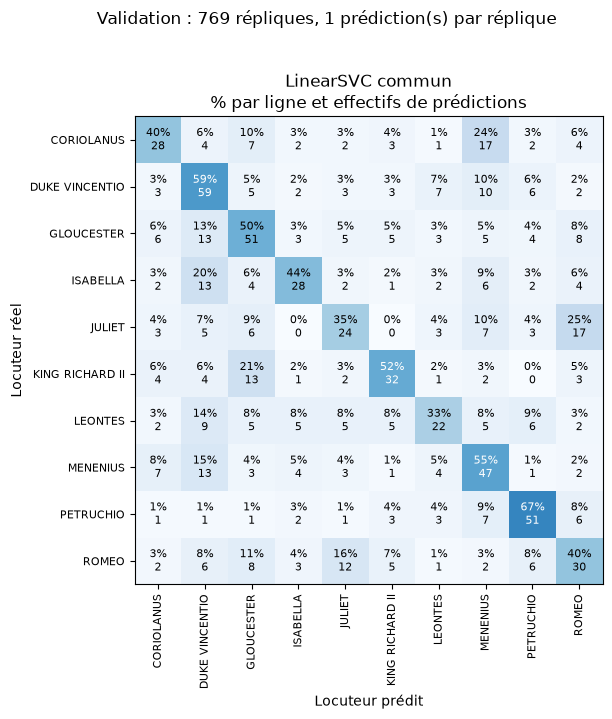

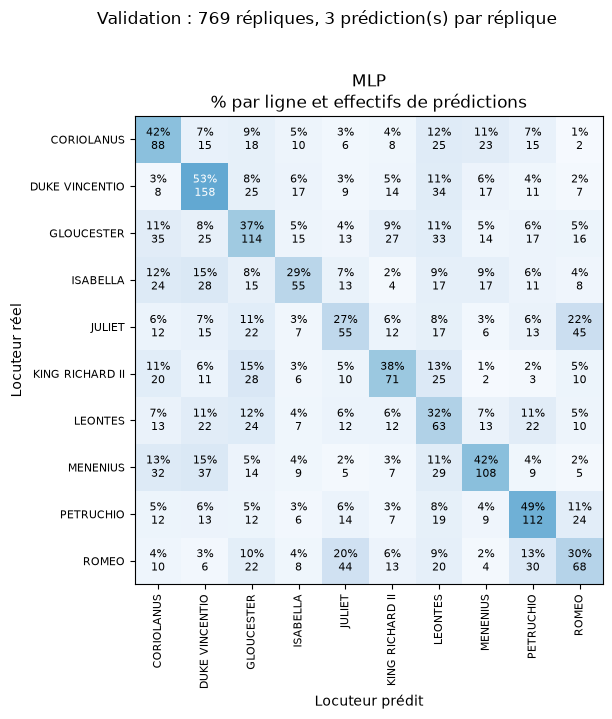

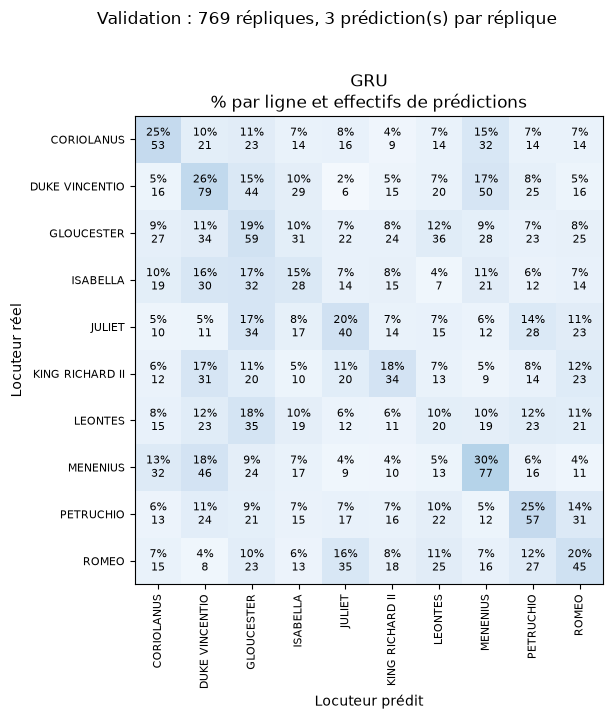

In [61]:
# Matrices de confusion de LinearSVC commun, du MLP et du GRU, en % de chaque locuteur réel.
MODELES_MATRICES = ['LinearSVC commun', 'MLP', 'GRU']


def matrice_confusion(nom: str, source=jeux_predictions, vrais=y_train) -> pd.DataFrame:
    """Effectifs réel × prédit, sommés sur les seeds d'un réseau."""
    effectifs = sum(confusion_matrix(vrais, jeu, labels=CLASSES) for jeu in source(nom))
    return pd.DataFrame(effectifs, index=CLASSES, columns=CLASSES)


def en_pourcentage(matrice: pd.DataFrame) -> pd.DataFrame:
    """Chaque ligne en % des répliques du locuteur réel."""
    return matrice.apply(lambda ligne: pourcentage(ligne, ligne.sum()), axis=1)


def tracer_matrice(axe, nom: str, matrice: pd.DataFrame) -> None:
    """Carte d'une matrice en % par ligne, valeurs arrondies écrites dans les cases."""
    lignes = en_pourcentage(matrice)
    axe.imshow(lignes, cmap='Blues', vmin=0, vmax=100)
    for (ligne, colonne), valeur in np.ndenumerate(lignes.to_numpy()):
        axe.text(colonne, ligne, f'{valeur:.0f}%\n{matrice.iloc[ligne, colonne]}', ha='center',
                 va='center', fontsize=8,
                 color='white' if valeur > 50 else 'black')
    axe.set_xticks(range(len(CLASSES)), CLASSES, rotation=90, fontsize=8)
    axe.set_yticks(range(len(CLASSES)), CLASSES, fontsize=8)
    axe.set(title=f'{nom}\n% par ligne et effectifs de prédictions', xlabel='Locuteur prédit',
            ylabel='Locuteur réel')


matrices = {nom: matrice_confusion(nom) for nom in MODELES_MATRICES}
for nom, matrice in matrices.items():
    fig, axe = plt.subplots(figsize=(8, 7))
    tracer_matrice(axe, nom, matrice)
    repetitions = len(jeux_predictions(nom))
    fig.suptitle(f'Validation : 769 répliques, {repetitions} prédiction(s) par réplique', y=1.02)
    plt.tight_layout()
    plt.show()

In [62]:
# Les trois plus fortes confusions de chaque modèle et les deux couples suivis depuis le TP1.
COUPLES_TP1 = [('JULIET', 'ROMEO'), ('ROMEO', 'JULIET'),
               ('GLOUCESTER', 'DUKE VINCENTIO'), ('DUKE VINCENTIO', 'GLOUCESTER')]


def decrire_case(matrice: pd.DataFrame, reel: str, predit: str) -> str:
    """Part d'une case dans les répliques du locuteur réel, avec les effectifs."""
    case, total = matrice.loc[reel, predit], matrice.loc[reel].sum()
    return f'{reel} → {predit} : {pourcentage(case, total):.1f} % ({case} sur {total})'


def decrire_confusions(matrices: dict) -> None:
    """Rappel moyen, trois plus fortes confusions et couples du TP1 de chaque matrice."""
    for nom, matrice in matrices.items():
        parts = en_pourcentage(matrice)
        hors_diagonale = parts.where(~np.eye(len(CLASSES), dtype=bool)).stack().dropna()
        print(f'{nom} : rappel moyen {np.diag(parts).mean():.1f} %')
        for titre, cases in (('plus fortes confusions', hors_diagonale.nlargest(3).index),
                             ('couples suivis depuis le TP1', COUPLES_TP1)):
            print(f'   {titre}')
            for reel, predit in cases:
                print(f'      {decrire_case(matrice, reel, predit)}')


decrire_confusions(matrices)

LinearSVC commun : rappel moyen 47.5 %
   plus fortes confusions
      JULIET → ROMEO : 25.0 % (17 sur 68)
      CORIOLANUS → MENENIUS : 24.3 % (17 sur 70)
      KING RICHARD II → GLOUCESTER : 21.0 % (13 sur 62)
   couples suivis depuis le TP1
      JULIET → ROMEO : 25.0 % (17 sur 68)
      ROMEO → JULIET : 16.0 % (12 sur 75)
      GLOUCESTER → DUKE VINCENTIO : 12.6 % (13 sur 103)
      DUKE VINCENTIO → GLOUCESTER : 5.0 % (5 sur 100)
MLP : rappel moyen 37.9 %
   plus fortes confusions
      JULIET → ROMEO : 22.1 % (45 sur 204)
      ROMEO → JULIET : 19.6 % (44 sur 225)
      KING RICHARD II → GLOUCESTER : 15.1 % (28 sur 186)
   couples suivis depuis le TP1
      JULIET → ROMEO : 22.1 % (45 sur 204)
      ROMEO → JULIET : 19.6 % (44 sur 225)
      GLOUCESTER → DUKE VINCENTIO : 8.1 % (25 sur 309)
      DUKE VINCENTIO → GLOUCESTER : 8.3 % (25 sur 300)
GRU : rappel moyen 20.8 %
   plus fortes confusions
      MENENIUS → DUKE VINCENTIO : 18.0 % (46 sur 255)
      LEONTES → GLOUCESTER : 17.7

In [63]:
# Je lis chaque faux positif de la colonne LEONTES dans la matrice du MLP.
colonne_leontes = en_pourcentage(matrices['MLP'])['LEONTES'].drop('LEONTES')
display(colonne_leontes.rename('Prédictions LEONTES (% par ligne)').round(2).to_frame())
print(f'Minimum hors diagonale : {colonne_leontes.min():.2f} %, '
      f'maximum : {colonne_leontes.max():.2f} %')

,Prédictions LEONTES (% par ligne)
CORIOLANUS,11.90
DUKE VINCENTIO,11.33
GLOUCESTER,10.68
ISABELLA,8.85
JULIET,8.33
KING RICHARD II,13.44
MENENIUS,11.37
PETRUCHIO,8.33
ROMEO,8.89


Minimum hors diagonale : 8.33 %, maximum : 13.44 %


> *Mes observations :*
>
> LinearSVC confond surtout JULIET vers ROMEO à 25,0 %, CORIOLANUS vers MENENIUS à 24,3 % et KING RICHARD II vers GLOUCESTER à 21,0 %. Son rappel moyen vaut 47,5 %.

Pour le MLP, JULIET vers ROMEO atteint 22,1 % et le sens inverse 19,6 %. Les cellules de la colonne LEONTES et leur minimum hors diagonale sont affichés ci-dessus. Sa précision moyenne de 0,223 indique de nombreux faux positifs, sans identifier les indices responsables.

Le GRU a un rappel moyen de 20,8 %. Plusieurs confusions fortes aboutissent à des classes fréquentes, dont DUKE VINCENTIO et GLOUCESTER. Cette association ne prouve pas que la fréquence seule cause ces erreurs.

> *Ma conclusion :*
>
> Parmi les modèles au tokenizer commun, LinearSVC obtient le meilleur F1 de sélection et précède les réseaux dans les cinq plis. La référence TP1 reste légèrement devant.

Je conserve les différences de score et les matrices comme résultats observés. Les comparaisons de désaccords complètent cette description sans démontrer un classement général. Je cherche maintenant quelles caractéristiques accompagnent les erreurs.

### 4.2 Revenir aux répliques

Les confusions du TP1 motivent une question sur la pièce et les noms, mais leurs coefficients ne démontraient pas une reconnaissance du style. Je cherche des associations dans les erreurs de validation.

Le corpus ne fournit pas ici d’annotation de pièce que j’utilise comme référence indépendante. Je conserve donc le regroupement prévu par positions et étiquettes comme une heuristique. Ses groupes serviront à décrire les erreurs, sans prouver leur origine.

Je coupe les apparitions d’un locuteur lorsqu’un écart dépasse 400 positions. Je relie ensuite les morceaux avec au moins 20 voisinages dans une fenêtre de cinq répliques.

Ces seuils sont conservés, sans validation sur des limites de pièces annotées. Le calcul utilise les étiquettes et positions du corpus complet pour l’analyse, sans les transmettre aux classifieurs.

In [64]:
# Pièces reconstruites à partir des seules étiquettes du corpus : morceaux de locuteurs, puis liens.
ECART_PIECE = 400  # Positions sans le locuteur au-delà desquelles il change de pièce
FENETRE_PIECE = 5  # Répliques suivantes où je cherche une réponse
SEUIL_PIECE = 20  # Réponses nécessaires pour relier deux morceaux


def morceaux_locuteurs() -> dict:
    """Positions de chaque locuteur retenu dans le corpus, coupées aux grands écarts."""
    etiquettes, morceaux = df['locuteur'].to_numpy(), {}
    for locuteur in CLASSES:
        positions = np.flatnonzero(etiquettes == locuteur)
        coupures = np.flatnonzero(np.diff(positions) > ECART_PIECE) + 1
        for numero, bloc in enumerate(np.split(positions, coupures), start=1):
            morceaux[(locuteur, numero)] = bloc
    return morceaux


def compter_reponses(morceaux: dict) -> Counter:
    """Fois où deux morceaux de locuteurs différents se suivent à moins de la fenêtre."""
    morceau_de = {position: cle for cle, bloc in morceaux.items() for position in bloc}
    liens = Counter()
    for position, cle in morceau_de.items():
        for suivante in range(position + 1, position + FENETRE_PIECE + 1):
            autre = morceau_de.get(suivante)
            if autre is not None and autre[0] != cle[0]:
                liens[tuple(sorted((cle, autre)))] += 1
    return liens


def numeroter_pieces(morceaux: dict, liens: Counter) -> dict:
    """Pièce de chaque morceau : liens d'au moins SEUIL_PIECE réponses, numéros dans l'ordre."""
    parent = {cle: cle for cle in morceaux}

    def racine(cle):
        while parent[cle] != cle:
            cle = parent[cle]
        return cle

    for (a, b), nombre in liens.items():
        if nombre >= SEUIL_PIECE:
            parent[racine(a)] = racine(b)
    debuts = {}
    for cle, bloc in morceaux.items():
        debuts[racine(cle)] = min(debuts.get(racine(cle), bloc[0]), bloc[0])
    numeros = {r: k for k, r in enumerate(sorted(debuts, key=debuts.get), start=1)}
    return {cle: numeros[racine(cle)] for cle in morceaux}


# Morceaux, liens et pièces
morceaux = morceaux_locuteurs()
liens = compter_reponses(morceaux)
piece_morceau = numeroter_pieces(morceaux, liens)

# Pièce de chaque réplique de développement, par sa position dans le corpus
assert (df.loc[X_train.index, 'locuteur'] == y_train).all()  # Indices du TP1 conservés
piece_position = {p: piece_morceau[cle] for cle, bloc in morceaux.items() for p in bloc}
piece_de = pd.Series({indice: piece_position[indice] for indice in X_train.index})
pieces_du_locuteur = {locuteur: {piece for (nom, _), piece in piece_morceau.items()
                                 if nom == locuteur} for locuteur in CLASSES}

# Affichages : morceaux, liens, puis locuteurs de chaque pièce
table_morceaux = pd.DataFrame([
    {'Morceau': f'{nom} {numero}', 'Répliques': len(bloc), 'Première position': bloc[0],
     'Dernière position': bloc[-1], 'Pièce': piece_morceau[(nom, numero)]}
    for (nom, numero), bloc in morceaux.items()]).sort_values('Première position')
display(table_morceaux.set_index('Morceau'))
for (a, b), nombre in liens.most_common():
    statut = 'relié' if nombre >= SEUIL_PIECE else 'coupé'
    print(f'{a[0]} {a[1]} – {b[0]} {b[1]} : {nombre} réponses, {statut}')
for piece in sorted(set(piece_morceau.values())):
    membres = [f'{nom} {numero}' for (nom, numero), p in piece_morceau.items() if p == piece]
    print(f'Pièce {piece} : {", ".join(membres)}, {(piece_de == piece).sum()} répliques de '
          f'développement')

,Répliques,Première position,Dernière position,Pièce
Morceau,,,,
MENENIUS 1,161,22,1041,1
CORIOLANUS 1,148,219,1086,1
GLOUCESTER 1,160,1098,1799,2
KING RICHARD II 1,98,2168,2706,3
ROMEO 1,160,2781,3496,4
JULIET 1,117,2844,3513,4
GLOUCESTER 2,51,3900,4328,5
LEONTES 1,124,4346,5066,6
DUKE VINCENTIO 1,189,5067,5938,7


DUKE VINCENTIO 1 – ISABELLA 1 : 247 réponses, relié
JULIET 1 – ROMEO 1 : 222 réponses, relié
CORIOLANUS 1 – MENENIUS 1 : 173 réponses, relié
DUKE VINCENTIO 1 – JULIET 2 : 36 réponses, relié
DUKE VINCENTIO 1 – LEONTES 1 : 3 réponses, coupé
ISABELLA 1 – JULIET 2 : 1 réponses, coupé
Pièce 1 : CORIOLANUS 1, MENENIUS 1, 155 répliques de développement
Pièce 2 : GLOUCESTER 1, 78 répliques de développement
Pièce 3 : KING RICHARD II 1, 62 répliques de développement
Pièce 4 : JULIET 1, ROMEO 1, 142 répliques de développement
Pièce 5 : GLOUCESTER 2, 25 répliques de développement
Pièce 6 : LEONTES 1, 66 répliques de développement
Pièce 7 : DUKE VINCENTIO 1, ISABELLA 1, JULIET 2, 165 répliques de développement
Pièce 8 : PETRUCHIO 1, 76 répliques de développement


> *Mes observations :*
>
> La règle produit douze morceaux réunis en huit groupes. GLOUCESTER apparaît dans deux groupes, et un second morceau de JULIET rejoint celui de DUKE VINCENTIO.

Je conserve le nom « pièce » dans les variables pour suivre le calcul existant. Dans l’analyse, il désigne un groupe reconstruit. Ces séparations sont compatibles avec des homonymes, sans établir seules l’identité des personnages ou les limites littéraires.

Je mesure la proportion d’erreurs dont le locuteur prédit appartient au même groupe reconstruit. Le repère suppose une prédiction uniforme parmi les neuf autres étiquettes sur les répliques mal classées.

Ce repère dépend donc des erreurs de chaque modèle. Une proportion plus élevée peut suggérer des indices partagés, sans démontrer que le modèle reconnaît la pièce.

,Erreurs,Dans la pièce (%),Hasard (%),Rapport au hasard
Modèle,,,,
LinearSVC commun,397.00,18.64,9.07,2.06
MLP,471.67,14.99,8.91,1.68
GRU,605.00,11.12,8.88,1.25


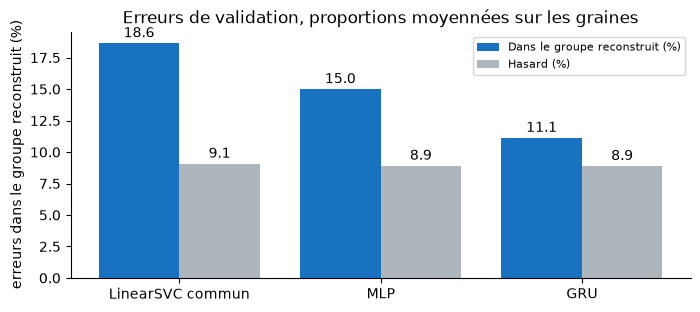

In [65]:
# Part des erreurs qui restent dans la pièce de la réplique, face au hasard, pour trois modèles.
MODELES_PIECE = ['LinearSVC commun', 'MLP', 'GRU']


def dans_la_piece(indice, predit: str) -> bool:
    """Vrai si le locuteur prédit a un morceau dans la pièce de la réplique."""
    return piece_position[indice] in pieces_du_locuteur[predit]


def part_intra(nom: str, source=jeux_predictions, vrais=y_train) -> dict:
    """Erreurs, part dans la même pièce et part attendue au hasard, moyennées sur les seeds."""
    lignes = []
    for jeu in source(nom):
        erreurs = jeu.index[jeu != vrais]
        dedans = sum(dans_la_piece(i, jeu.loc[i]) for i in erreurs)
        # Hasard : l'erreur tombe sur l'un des neuf autres locuteurs, chacun avec la même chance
        hasard = sum(dans_la_piece(i, autre) for i in erreurs for autre in CLASSES
                     if autre != vrais.loc[i]) / (len(CLASSES) - 1)
        lignes.append({'Erreurs': len(erreurs),
                       'Dans la pièce (%)': pourcentage(dedans, len(erreurs)),
                       'Hasard (%)': pourcentage(hasard, len(erreurs))})
    moyenne = pd.DataFrame(lignes).mean()
    return {'Modèle': nom, **moyenne.to_dict(),
            'Rapport au hasard': moyenne['Dans la pièce (%)'] / moyenne['Hasard (%)']}


intra = pd.DataFrame([part_intra(nom) for nom in MODELES_PIECE]).set_index('Modèle')
display(intra.round(2))

# Erreurs dans la pièce face au hasard, deux barres par modèle
positions = np.arange(len(intra))
fig, ax = plt.subplots(figsize=(8, 3.2))
for decalage, colonne, couleur in ((-0.2, 'Dans la pièce (%)', '#1971c2'),
                                   (0.2, 'Hasard (%)', '#adb5bd')):
    barres = ax.bar(positions + decalage, intra[colonne], 0.4, color=couleur,
                    label=colonne.replace('la pièce', 'le groupe reconstruit'))
    ax.bar_label(barres, labels=[f'{valeur:.1f}' for valeur in intra[colonne]], padding=2)
ax.set_xticks(positions, intra.index)
ax.set_ylabel('erreurs dans le groupe reconstruit (%)')
ax.set_title('Erreurs de validation, proportions moyennées sur les graines')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Pour LinearSVC, 18,6 % des erreurs restent dans le groupe contre 9,1 % avec le repère uniforme. Les proportions observées valent 15,0 % pour le MLP et 11,1 % pour le GRU.

Je relève un excès par rapport à ce repère précis. Dire que la pièce « explique » ces erreurs serait plus fort que la mesure. Plus de 81 % des erreurs sortent du groupe reconstruit.

Je reprends les deux couples suivis depuis le TP1 en indiquant le groupe reconstruit de chaque confusion. GLOUCESTER apparaît dans deux morceaux, donc je mesure aussi son rappel dans chacun.

In [66]:
# Couples suivis depuis le TP1 : confusions par modèle, seeds sommées, puis GLOUCESTER par morceau.


def confusions_couple(nom: str, reel: str, predit: str) -> dict:
    """Confusions d'un couple sur toutes les seeds, et combien restent dans la même pièce."""
    cas = [i for jeu in jeux_predictions(nom)
           for i in jeu.index[(y_train == reel) & (jeu == predit)]]
    return {'Modèle': nom, 'Couple': f'{reel} → {predit}', 'Confusions': len(cas),
            'Dans la même pièce': sum(dans_la_piece(i, predit) for i in cas)}


def rappel_par_piece(nom: str, locuteur: str) -> dict:
    """Rappel d'un locuteur dans chacune de ses pièces, toutes seeds confondues."""
    rappels = {'Modèle': nom}
    for piece in sorted(pieces_du_locuteur[locuteur]):
        indices = y_train.index[(y_train == locuteur) & (piece_de == piece)]
        justes = sum((jeu.loc[indices] == locuteur).sum() for jeu in jeux_predictions(nom))
        rappels[f'Pièce {piece}, {len(indices)} répliques'] = pourcentage(
            justes, len(indices) * len(jeux_predictions(nom)))
    return rappels


couples = pd.DataFrame([confusions_couple(nom, reel, predit) for nom in MODELES_PIECE
                        for reel, predit in COUPLES_TP1])
display(couples.pivot(index='Couple', columns='Modèle',
                      values=['Confusions', 'Dans la même pièce']))
display(pd.DataFrame([rappel_par_piece(nom, 'GLOUCESTER') for nom in MODELES_PIECE])
        .set_index('Modèle').round(1).rename_axis('Rappel de GLOUCESTER (%)'))

Confusions                       \
Modèle                             GRU LinearSVC commun MLP   
Couple                                                        
DUKE VINCENTIO → GLOUCESTER         44                5  25   
GLOUCESTER → DUKE VINCENTIO         34               13  25   
JULIET → ROMEO                      23               17  45   
ROMEO → JULIET                      35               12  44   

                            Dans la même pièce                       
Modèle                                     GRU LinearSVC commun MLP  
Couple                                                               
DUKE VINCENTIO → GLOUCESTER                  0                0   0  
GLOUCESTER → DUKE VINCENTIO                  0                0   0  
JULIET → ROMEO                              23               17  45  
ROMEO → JULIET                              35               12  44

,"Pièce 2, 78 répliques","Pièce 5, 25 répliques"
Rappel de GLOUCESTER (%),,
LinearSVC commun,47.4,56.0
MLP,39.3,29.3
GRU,19.2,18.7


> *Mes observations :*
>
> Les confusions JULIET–ROMEO restent dans les mêmes groupes reconstruits, contrairement à celles entre GLOUCESTER et DUKE VINCENTIO. Le tableau distingue les comptes uniques de LinearSVC et les prédictions cumulées des réseaux.

Le rappel de GLOUCESTER vaut 47,4 % et 56,0 % pour LinearSVC dans ses deux groupes. Cela ne démontre pas qu’il utilise les mêmes indices dans les deux. Le petit groupe ne contient que 25 répliques de développement.

Je décris chaque réplique par sa longueur, ses tokens inconnus, les noms détectés et les tokens partagés par les dix classes. Les listes sont ajustées sur le train de son pli.

La détection des noms est une règle de capitalisation, avec un seuil de 95 % et au moins trois occurrences. Elle peut retenir des lieux ou manquer des noms. Je garderai cette définition dans l’ablation.

In [67]:
# Facteurs de chaque réplique de validation, calculés avec les listes du train de son fold.
MOT = r"[A-Za-z]+(?:'[A-Za-z]+)*"  # Mot du texte brut, apostrophes internes comprises
SEUIL_MAJUSCULE, MINIMUM_NOM = 0.95, 3


def detecter_noms(textes: pd.Series) -> set:
    """Mots presque toujours en majuscule et assez fréquents, hors « I » et ses contractions."""
    total, majuscules = Counter(), Counter()
    for texte in textes:
        for mot in re.findall(MOT, texte):
            cle = mot.lower()
            if len(cle) < 2 or cle.startswith("i'"):
                continue
            total[cle] += 1
            majuscules[cle] += mot[0].isupper()
    return {mot for mot, nombre in total.items()
            if nombre >= MINIMUM_NOM and majuscules[mot] / nombre >= SEUIL_MAJUSCULE}


def facteurs_fold(fold: dict, textes: pd.Series = X_train) -> pd.DataFrame:
    """Longueur, tokens inconnus, noms et tokens partagés, avec les listes du train du fold."""
    textes_train = X_train.loc[fold['train']]
    vocabulaire, noms = construire_vocabulaire(textes_train), detecter_noms(textes_train)
    locuteurs_du_token = {}
    for texte, cible in zip(textes_train, y_train.loc[fold['train']]):
        for token in set(tokeniser(texte)):
            locuteurs_du_token.setdefault(token, set()).add(cible)
    lignes = []
    for indice in fold['validation']:
        tokens = tokeniser(textes.loc[indice])
        partages = sum(len(locuteurs_du_token.get(t, ())) == len(CLASSES) for t in tokens)
        lignes.append({'Indice': indice, 'Longueur': len(tokens),
                       'Inconnus (%)': pourcentage(sum(t not in vocabulaire for t in tokens),
                                                   len(tokens)),
                       'Partagés (%)': pourcentage(partages, len(tokens)),
                       'Noms': sorted({t for t in tokens if t in noms})})
    return pd.DataFrame(lignes).set_index('Indice')


# Facteurs des 769 répliques, puis ce que la règle des noms retient
facteurs = pd.concat([facteurs_fold(fold) for fold in folds]).loc[X_train.index]
facteurs['Nom'] = facteurs['Noms'].str.len() > 0
noms_fold_1 = detecter_noms(X_train.loc[folds[0]['train']])
frequences = Counter(token for texte in X_train.loc[folds[0]['train']]
                     for token in tokeniser(texte) if token in noms_fold_1)
print(f'Noms par fold : {[len(detecter_noms(X_train.loc[f["train"]])) for f in folds]}')
print('Fold 1, les 20 plus fréquents : '
      + ', '.join(f'{nom} ({nombre})' for nom, nombre in frequences.most_common(20)))
print(f'Répliques de validation avec au moins un nom : '
      f'{pourcentage(facteurs["Nom"].sum(), len(facteurs)):.1f} %')

Noms par fold : [53, 51, 55, 54, 56]
Fold 1, les 20 plus fréquents : kate (39), romeo (27), angelo (24), rome (16), clarence (13), juliet (13), marcius (11), tybalt (11), bolingbroke (10), edward (10), aufidius (9), claudio (8), edward's (6), camillo (6), cominius (6), paulina (6), richard (6), henry (6), tybalt's (6), polixenes (5)
Répliques de validation avec au moins un nom : 28.5 %


> *Mes observations :*
>
> La règle retient de 51 à 56 mots selon le fold. Sur le fold 1, les plus fréquents sont des personnages, comme « kate » (39), « romeo » (27) et « angelo » (24). La liste contient aussi des lieux, comme « rome » (16). Les formes possessives comme « edward's » et « tybalt's » comptent comme des noms à part. Au moins un nom apparaît dans 28,5 % des répliques de validation.

Je compare maintenant ces facteurs entre quatre groupes de répliques, selon que `LinearSVC commun` et le MLP ont raison. Je calcule les groupes pour chaque seed du MLP, puis je fais la moyenne, comme pour les comptes de la section 4.1.

,Répliques,Longueur,Avec un nom (%),Inconnus (%),Partagés (%)
Groupe,,,,,
Deux justes,221.7,60.3,45.8,12.7,55.2
LinearSVC seul juste,150.3,54.9,35.8,12.8,54.7
MLP seul juste,75.7,45.9,22.4,13.3,54.8
Deux faux,321.3,39.0,14.7,13.1,56.0


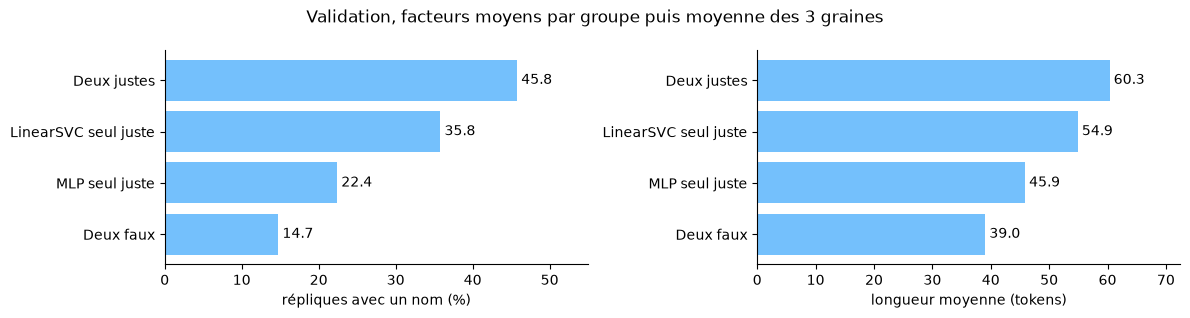

In [68]:
# Quatre groupes de répliques selon LinearSVC commun et le MLP, puis leurs facteurs moyens.
ORDRE_GROUPES = ['Deux justes', 'LinearSVC seul juste', 'MLP seul juste', 'Deux faux']


def groupes_svc_mlp(jeu_mlp: pd.Series, jeu_svc=None, vrais=y_train) -> pd.Series:
    """Groupe de chaque réplique selon que LinearSVC commun et une seed du MLP ont raison."""
    if jeu_svc is None:
        jeu_svc = jeux_predictions('LinearSVC commun')[0]
    svc, mlp = jeu_svc == vrais, jeu_mlp == vrais
    choix = np.select([svc & mlp, svc & ~mlp, ~svc & mlp], ORDRE_GROUPES[:3], ORDRE_GROUPES[3])
    return pd.Series(choix, index=vrais.index)


def facteurs_par_groupe(jeu_mlp: pd.Series, jeu_svc=None, vrais=y_train,
                        table=None) -> pd.DataFrame:
    """Effectif et facteurs moyens de chaque groupe pour une seed du MLP."""
    table = facteurs if table is None else table
    return table.assign(Groupe=groupes_svc_mlp(jeu_mlp, jeu_svc, vrais)).groupby('Groupe').agg(
        Répliques=('Longueur', 'size'), Longueur=('Longueur', 'mean'),
        **{'Avec un nom (%)': ('Nom', lambda s: pourcentage(s.sum(), len(s))),
           'Inconnus (%)': ('Inconnus (%)', 'mean'), 'Partagés (%)': ('Partagés (%)', 'mean')})


tables = [facteurs_par_groupe(jeu) for jeu in jeux_predictions('MLP')]
facteurs_groupes = (sum(tables) / len(tables)).loc[ORDRE_GROUPES]
display(facteurs_groupes.round(1))

# Part de répliques avec un nom et longueur moyenne, par groupe
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for axe, colonne in zip(axes, ('Avec un nom (%)', 'Longueur')):
    barres = axe.barh(ORDRE_GROUPES[::-1], facteurs_groupes[colonne][::-1], color='#74c0fc')
    axe.bar_label(barres, labels=[f'{v:.1f}' for v in facteurs_groupes[colonne][::-1]], padding=3)
    axe.set_xlim(0, facteurs_groupes[colonne].max() * 1.2)
    axe.set_xlabel({'Longueur': 'longueur moyenne (tokens)'}.get(
        colonne, 'répliques avec un nom (%)'))
    axe.spines[['top', 'right']].set_visible(False)
fig.suptitle('Validation, facteurs moyens par groupe puis moyenne des 3 graines')
plt.tight_layout()
plt.show()

> *Mes observations :*
>
> Un nom détecté apparaît dans 45,8 % des succès communs, contre 14,7 % des erreurs communes. Les longueurs moyennes passent aussi de 60,3 à 39,0 tokens entre ces groupes.

Les parts moyennes d’inconnus et de tokens partagés varient peu. Ces associations ne séparent pas l’effet des noms de celui de la longueur, des classes ou des scènes.

Je retiens le retrait des noms comme prochaine comparaison. L’analyse actuelle ne démontre ni leur rôle dans chaque décision ni l’inutilité des autres facteurs.

Je lis enfin cinq répliques entières, une par catégorie. Pour ne pas choisir celles qui m'arrangent, je prends dans chaque catégorie la première réplique dans l'ordre du corpus. Le MLP a raison quand au moins deux de ses trois seeds ont raison.

In [69]:
# Cinq cas concrets : dans chaque catégorie, la première réplique dans l'ordre du corpus.
import textwrap

svc = jeux_predictions('LinearSVC commun')[0]
mlp_seeds = pd.concat(jeux_predictions('MLP'), axis=1)
gru_seeds = pd.concat(jeux_predictions('GRU'), axis=1)
svc_juste = svc == y_train
mlp_juste = mlp_seeds.eq(y_train, axis=0).mean(axis=1) > 0.5  # Majorité des seeds
svc_dans_piece = pd.Series([dans_la_piece(i, svc.loc[i]) for i in X_train.index], X_train.index)
CATEGORIES = {
    'Erreur commune dans le groupe reconstruit': ~svc_juste & ~mlp_juste & svc_dans_piece,
    'Erreur commune hors du groupe reconstruit': ~svc_juste & ~mlp_juste & ~svc_dans_piece,
    'Corrigée par le MLP': ~svc_juste & mlp_juste,
    'Introduite par le MLP': svc_juste & ~mlp_juste,
    'JULIET prédite ROMEO par LinearSVC': (y_train == 'JULIET') & (svc == 'ROMEO'),
}


def decrire_cas(titre: str, indice) -> str:
    """Réplique entière, locuteur réel, prédictions des trois modèles et facteurs."""
    ligne = facteurs.loc[indice]
    return (f'{titre}, indice {indice}, groupe reconstruit {piece_de.loc[indice]}\n'
            f'   réel : {y_train.loc[indice]} | LinearSVC : {svc.loc[indice]} | '
            f'MLP : {", ".join(mlp_seeds.loc[indice])} | GRU : {", ".join(gru_seeds.loc[indice])}\n'
            f'   {ligne["Longueur"]} tokens, {ligne["Inconnus (%)"]:.1f} % inconnus, '
            f'{ligne["Partagés (%)"]:.1f} % partagés, '
            f'noms : {", ".join(ligne["Noms"]) or "aucun"}\n'
            + textwrap.fill(X_train.loc[indice], width=96, initial_indent='   ',
                            subsequent_indent='   ') + '\n')


for titre, masque in CATEGORIES.items():
    print(f'{titre} : {masque.sum()} répliques')
print()
for titre, masque in CATEGORIES.items():
    if masque.any():
        print(decrire_cas(titre, masque.index[masque].min()))

Erreur commune dans le groupe reconstruit : 58 répliques
Erreur commune hors du groupe reconstruit : 282 répliques
Corrigée par le MLP : 57 répliques
Introduite par le MLP : 139 répliques
JULIET prédite ROMEO par LinearSVC : 17 répliques

Erreur commune dans le groupe reconstruit, indice 259, groupe reconstruit 1
   réel : MENENIUS | LinearSVC : CORIOLANUS | MLP : LEONTES, MENENIUS, LEONTES | GRU : LEONTES, DUKE VINCENTIO, DUKE VINCENTIO
   19 tokens, 31.6 % inconnus, 42.1 % partagés, noms : rome
   Why, then you should discover a brace of unmeriting, proud, violent, testy magistrates, alias
   fools, as any in Rome.

Erreur commune hors du groupe reconstruit, indice 24, groupe reconstruit 1
   réel : MENENIUS | LinearSVC : LEONTES | MLP : LEONTES, PETRUCHIO, LEONTES | GRU : MENENIUS, PETRUCHIO, MENENIUS
   12 tokens, 25.0 % inconnus, 50.0 % partagés, noms : aucun
   Why, masters, my good friends, mine honest neighbours, Will you undo yourselves?

Corrigée par le MLP, indice 26, groupe

> *Mes observations :*
>
> Les quatre premiers exemples sont tous MENENIUS, car je prends les premières positions du corpus dans chaque catégorie. Cette règle rend le choix reproductible, mais les cas ne sont pas représentatifs de toutes les classes.

À l’indice 259, « rome » est détecté et 31,6 % des tokens sont inconnus du vocabulaire. LinearSVC prédit CORIOLANUS, tandis que les graines du MLP donnent LEONTES ou MENENIUS.

À l’indice 24, la réplique contient douze tokens et aucun nom détecté. Deux graines du GRU trouvent pourtant MENENIUS. L’absence de nom ne signifie donc pas absence d’indices utilisables.

À l’indice 26, deux graines du MLP corrigent LinearSVC sur une longue réplique sans nom détecté. À l’indice 28, les trois graines du MLP échouent là où LinearSVC réussit.

À l’indice 2867, JULIET est prédite ROMEO par LinearSVC. Les mots « look » et « eye » suggèrent une interprétation possible, mais je ne calcule pas leurs contributions ici.

Ces cas montrent des désaccords concrets. Ils ne suffisent pas à attribuer les décisions à la moyenne des embeddings, aux noms ou à un thème.

> *Ma conclusion :*
>
> Les noms détectés et la longueur sont associés aux groupes de réussite, alors que leurs autres moyennes changent peu. Je vais retirer les noms pour examiner ce qui arrive aux scores après réentraînement.

Les regroupements par pièce restent des approximations. Ils décrivent où les erreurs aboutissent, sans identifier le mécanisme qui les produit.

### 4.3 Expériences ciblées, si les résultats le justifient

Je conserve les pistes initiales pour suivre ce qui a été testé et ce qui reste ouvert. Chaque intervention garde les plis et les graines, mais peut avoir plusieurs conséquences sur les représentations.

| Piste initiale | Attente à examiner |
|---|---|
| Ordre des mots | Le mélange dégrade les réseaux récurrents si l’ordre leur apporte un avantage. |
| Noms propres | Leur retrait dégrade les modèles qui utilisent les termes détectés. |
| Régularisation | Dropout et weight decay réduisent l’écart train/validation. |
| Bidirectionnel | Le parcours dans les deux sens aide la représentation d’une réplique entière. |
| Quantité de données | L’écart MLP–LinearSVC diminue avec davantage de répliques d’entraînement. |

Ces expériences ne séparent pas complètement style, sujet et identité. Je décrirai les changements induits par chaque intervention avant d’en interpréter les résultats.

Je garde l’ordre réalisé, soit noms, mélange, quantité de données puis régularisation du MLP. Les associations précédentes motivent le retrait des noms, et H2 motive le mélange.

Je conserve le choix de ne pas entraîner de modèle bidirectionnel. Les résultats sur les répliques courtes ne démontrent pas qu’il serait inutile. Cette possibilité reste simplement hors des essais réalisés.

Je vérifie d’abord les transformations sur une réplique contenant un nom détecté. Les listes sont ajustées dans chaque train de pli. Je préciserai les conséquences sur les séquences et les vocabulaires après ce contrôle local.

In [70]:
# Outils des expériences : prétraitements ajustés sur le train du fold, folds réduits, comparaison.
from sklearn.base import BaseEstimator, TransformerMixin


class Pretraitement(BaseEstimator, TransformerMixin):
    """Étape de pipeline : ajuste un prétraitement sur les textes du train, puis l'applique."""

    def __init__(self, ajuster):
        self.ajuster = ajuster

    def fit(self, textes: pd.Series, cibles=None):
        self.appliquer_ = self.ajuster(textes)
        return self

    def transform(self, textes: pd.Series) -> pd.Series:
        return self.appliquer_(textes)


def ajuster_masque_noms(textes_train: pd.Series):
    """Noms détectés sur le train du fold, puis retirés des tokens de toute réplique."""
    noms = detecter_noms(textes_train)
    return lambda textes: textes.map(
        lambda texte: ' '.join(token for token in tokeniser(texte) if token not in noms))


def ajuster_melange(textes_train: pd.Series):
    """Tokens de chaque réplique mélangés par un générateur fixé par son indice."""
    def melanger(textes: pd.Series) -> pd.Series:
        return pd.Series([' '.join(np.random.default_rng(indice).permutation(tokeniser(texte)))
                          for indice, texte in textes.items()], index=textes.index)
    return melanger


def construire_svc_experience(ajuster=None, unigrammes: bool = False) -> Pipeline:
    """LinearSVC commun, avec un prétraitement en tête ou des unigrammes seuls."""
    tfidf = construire_tfidf('commun')
    if unigrammes:
        tfidf.set_params(ngram_range=(1, 1))
    etapes = [('tfidf', tfidf), ('svc', LinearSVC(**PARAMS_SVC))]
    if ajuster is not None:
        etapes.insert(0, ('pretraitement', Pretraitement(ajuster)))
    return Pipeline(etapes)


def reduire_folds(part: float) -> list:
    """Chaque fold garde une part stratifiée de son train, seed 42, et toute sa validation."""
    if part == 1.0:
        return folds
    return [{'train': train_test_split(fold['train'], train_size=part, random_state=RANDOM_STATE,
                                       stratify=y_train.loc[fold['train']])[0],
             'validation': fold['validation']} for fold in folds]


def comparer_experience(base: str, variante: str) -> dict:
    """F1 des deux entrées, écart moyen, folds en baisse, epoch, F1 train et p-value de McNemar."""
    ecarts = ecarts_par_fold(base, variante)
    bilans = {nom: ligne_bilan(nom) for nom in (base, variante)}
    return {'Variante': variante, 'F1 base': bilans[base]['F1 macro'],
            'F1 variante': bilans[variante]['F1 macro'], 'Écart moyen': ecarts['Écart'].mean(),
            'Folds en baisse': int((ecarts['Écart'] < 0).sum()),
            'Epoch variante': bilans[variante]['Epoch retenue'],
            'F1 train variante': bilans[variante]['F1 train'],
            'p-value McNemar': comparer_paire(base, variante)['p-value maximale']}


# Contrôle sur le fold 1 : première réplique de validation avec un nom, brute, sans noms, mélangée
textes_train_1 = X_train.loc[folds[0]['train']]
masquer, melanger = ajuster_masque_noms(textes_train_1), ajuster_melange(textes_train_1)
indice_exemple = min(i for i in folds[0]['validation'] if facteurs.loc[i, 'Nom'])
exemple = X_train.loc[[indice_exemple]]
for titre, version in (('brute', exemple), ('sans noms', masquer(exemple)),
                       ('mélangée', melanger(exemple))):
    print(f'{titre} : {version.iloc[0]}')
retour = all(tokeniser(' '.join(tokeniser(texte))) == tokeniser(texte) for texte in X_train)
print(f'Tokens identiques après un passage par le texte joint, sur les 769 répliques : {retour}')

brute : In what enormity is Marcius poor in, that you two have not in abundance?
sans noms : in what enormity is poor in that you two have not in abundance
mélangée : marcius have you not two abundance that is what in in poor in enormity
Tokens identiques après un passage par le texte joint, sur les 769 répliques : True


> *Mes observations :*
>
> La suppression retire « marcius » de l’exemple et le mélange conserve ses tokens dans un autre ordre. Rejoindre puis redécouper le texte conserve les tokens sur les 769 répliques contrôlées.

Retirer un nom modifie aussi la longueur, les voisinages et les vocabulaires ajustés ensuite. Le mélange précède la troncature, donc certaines longues répliques peuvent conserver d’autres tokens. Ces contrôles ne garantissent pas une intervention sur un seul mécanisme.

Je retire les noms détectés dans le train et la validation de chaque pli, puis réentraîne les trois modèles. La liste dépend uniquement du train du pli.

> *Mon hypothèse :*
>
> LinearSVC perd plus que le MLP, car il trouve seul davantage de répliques contenant un nom détecté.

In [71]:
# Expérience 1 : noms retirés, détectés sur le train de chaque fold, pour trois modèles.
evaluer_ml('LinearSVC commun sans noms', partial(construire_svc_experience, ajuster_masque_noms))
evaluer_reseau('MLP sans noms', MoyenneMLP, dict(REGLAGES_MLP, pretraitement=ajuster_masque_noms))
evaluer_reseau('GRU sans noms', GRU, dict(REGLAGES, pretraitement=ajuster_masque_noms))
SANS_NOMS = {'LinearSVC commun': 'LinearSVC commun sans noms', 'MLP': 'MLP sans noms',
             'GRU': 'GRU sans noms'}
experience_noms = pd.DataFrame([comparer_experience(base, variante)
                                for base, variante in SANS_NOMS.items()]).set_index('Variante')
display(experience_noms.round(3))

LinearSVC commun / LinearSVC commun sans noms : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,54,12,318,385,1.694494e-07


MLP / MLP sans noms : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,129,81,170,389,0.001131
43,122,101,168,378,0.180345
44,135,82,168,384,0.000391


GRU / GRU sans noms : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,116,93,51,509,0.127866
43,96,92,56,525,0.826880
44,109,93,64,503,0.291223


,F1 base,F1 variante,Écart moyen,Folds en baisse,Epoch variante,F1 train variante,p-value McNemar
Variante,,,,,,,
LinearSVC commun sans noms,0.475,0.421,-0.054,5,NaN,1.000,1.7e-07
MLP sans noms,0.376,0.325,-0.051,5,58.0,1.000,1.8e-01
GRU sans noms,0.206,0.182,-0.024,4,20.0,0.983,8.3e-01


> *Mes observations :*
>
> LinearSVC perd 0,054 de F1 moyen et le MLP 0,051, avec cinq plis en baisse pour chacun. Le GRU perd 0,024 et baisse dans quatre plis.

La baisse de LinearSVC est légèrement supérieure, mais elle ne distingue pas nettement les deux premiers modèles dans ces essais. Je ne transforme pas ces baisses en pourcentages du signal « porté » par les noms.

Le retrait modifie aussi les bigrammes, les séquences et parfois la taille des embeddings, donc les correspondances de poids initiaux. Les valeurs de McNemar décrivent les discordances, avec les limites exposées en section 4.1.

Je regarde la variation par classe pour savoir où la baisse apparaît. L’ablation retire une liste de mots et réentraîne le modèle, donc elle ne mesure pas la contribution d’un nom isolé.

> *Mon hypothèse :*
>
> PETRUCHIO chute le plus pour LinearSVC, car le coefficient élevé de « kate » au TP1 motivait cette piste.

,LinearSVC commun,MLP,GRU
CORIOLANUS,-0.019,-0.008,-0.006
DUKE VINCENTIO,-0.056,-0.087,-0.008
GLOUCESTER,-0.045,-0.086,0.007
ISABELLA,-0.028,-0.028,-0.020
JULIET,-0.063,-0.048,-0.073
KING RICHARD II,-0.012,-0.039,-0.067
LEONTES,-0.091,-0.044,0.028
MENENIUS,-0.043,-0.085,-0.020
PETRUCHIO,-0.127,-0.044,-0.045
ROMEO,-0.048,-0.037,-0.030


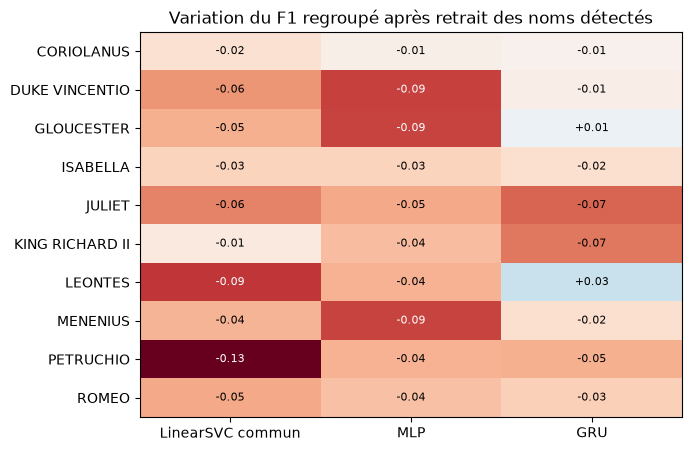

In [72]:
# Variation du F1 de chaque locuteur quand les noms disparaissent, pour les trois modèles.
variation_noms = pd.DataFrame({
    base: metriques_par_classe(variante)['F1'] - metriques_par_classe(base)['F1']
    for base, variante in SANS_NOMS.items()})
display(variation_noms.round(3))

borne = variation_noms.abs().to_numpy().max()
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(variation_noms, cmap='RdBu', vmin=-borne, vmax=borne, aspect='auto')
for (ligne, colonne), valeur in np.ndenumerate(variation_noms.to_numpy()):
    ax.text(colonne, ligne, f'{valeur:+.2f}', ha='center', va='center', fontsize=8,
            color='white' if abs(valeur) > 0.6 * borne else 'black')
ax.set_xticks(range(len(SANS_NOMS)), list(SANS_NOMS))
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_title('Variation du F1 regroupé après retrait des noms détectés')
plt.show()

> *Mes observations :*
>
> PETRUCHIO a la plus forte baisse pour LinearSVC, soit 0,127, devant LEONTES à 0,091. Pour le MLP, les plus fortes baisses concernent DUKE VINCENTIO, GLOUCESTER et MENENIUS.

L’attente par classe est soutenue pour LinearSVC. L’expérience ne permet toutefois pas d’attribuer toute la baisse de PETRUCHIO à « kate ». Les listes de termes retirés et les réajustements concernent plusieurs indices à la fois.

Je réentraîne les modèles après mélange des tokens, avec une permutation fixée par l’indice de chaque réplique. J’ajoute la référence unigramme prévue pour contrôler une représentation qui ignore l’ordre.

> *Mon hypothèse :*
>
> Le GRU et les bigrammes baissent, tandis que le MLP et les unigrammes restent proches de leur référence. Pour le MLP, cette attente suppose aussi de conserver les mêmes tokens après troncature.

In [73]:
# Expérience 2 : tokens mélangés dans chaque réplique, même perturbation pour tous les modèles.
evaluer_ml('LinearSVC unigrammes', partial(construire_svc_experience, unigrammes=True))
evaluer_ml('LinearSVC unigrammes mélangé',
           partial(construire_svc_experience, ajuster_melange, unigrammes=True))
evaluer_ml('LinearSVC commun mélangé', partial(construire_svc_experience, ajuster_melange))
evaluer_reseau('MLP mélangé', MoyenneMLP, dict(REGLAGES_MLP, pretraitement=ajuster_melange))
evaluer_reseau('GRU mélangé', GRU, dict(REGLAGES, pretraitement=ajuster_melange))
MELANGES = {'LinearSVC unigrammes': 'LinearSVC unigrammes mélangé',
            'LinearSVC commun': 'LinearSVC commun mélangé', 'MLP': 'MLP mélangé',
            'GRU': 'GRU mélangé'}
experience_ordre = pd.DataFrame([comparer_experience(base, variante)
                                 for base, variante in MELANGES.items()]).set_index('Variante')
display(experience_ordre.round(3))

LinearSVC unigrammes / LinearSVC unigrammes mélangé : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,0,0,366,403,1.0


LinearSVC commun / LinearSVC commun mélangé : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,74,57,298,340,0.161882


MLP / MLP mélangé : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,5,7,294,463,0.774414
43,10,10,280,469,1.000000
44,11,11,292,455,1.000000


GRU / GRU mélangé : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,116,104,51,498,0.458395
43,107,113,45,504,0.736128
44,114,113,59,483,1.000000


,F1 base,F1 variante,Écart moyen,Folds en baisse,Epoch variante,F1 train variante,p-value McNemar
Variante,,,,,,,
LinearSVC unigrammes mélangé,0.464,0.464,0.000,0,NaN,1.0,1.0e+00
LinearSVC commun mélangé,0.475,0.445,-0.030,4,NaN,1.0,1.6e-01
MLP mélangé,0.376,0.377,0.001,2,80.0,1.0,1.0e+00
GRU mélangé,0.206,0.199,-0.007,3,37.0,1.0,1.0e+00


> *Mes observations :*
>
> La référence unigramme garde un F1 de 0,464. Le modèle avec bigrammes perd 0,030, le MLP gagne 0,001 et le GRU perd 0,007.

Une valeur de McNemar égale à 1 ne prouve pas l’absence de désaccords, car des discordances équilibrées peuvent aussi la produire. Les comptes par graine permettent de vérifier ce point directement.

> *Ma conclusion :*
>
> L’avantage attendu du GRU et sa forte sensibilité prévue au mélange ne sont pas observés. Cette faible baisse ne démontre pas qu’il n’utilise aucun ordre. Les essais portent sur des modèles réentraînés et sur une perturbation particulière.

Je conserve les tirages stratifiés de 25, 50 et 75 % du train, avec la validation entière. Diviser le plafond d’epochs par la fraction rapproche les budgets maximaux de mises à jour.

L’arrondi du plafond et le dernier batch empêchent une égalité systématique. Les epochs retenues peuvent aussi différer, et le vocabulaire et la troncature sont réajustés sur chaque sous-ensemble.

> *Mon hypothèse :*
>
> Si davantage de données aide particulièrement le MLP, son écart avec LinearSVC diminue lorsque le train grandit.

In [74]:
# Expérience 3 : 25, 50 et 75 % du train de chaque fold pour LinearSVC commun et le MLP.
PARTS = (0.25, 0.5, 0.75, 1.0)


def nom_part(modele: str, part: float) -> str:
    """Nom du registre pour un modèle entraîné sur une part du train."""
    return modele if part == 1.0 else f'{modele} {100 * part:.0f} %'


def ligne_part(modele: str, part: float) -> dict:
    """F1 macro, dispersion, F1 train, epoch et plafond d'un modèle pour une part du train."""
    bilan = ligne_bilan(nom_part(modele, part))
    ligne = {'Modèle': modele, 'Part du train (%)': 100 * part,
             'Répliques de train (fold 1)': len(reduire_folds(part)[0]['train']),
             'F1 macro': bilan['F1 macro'], 'F1 écart-type': bilan['F1 écart-type'],
             'F1 train': bilan['F1 train'], 'Epoch retenue': bilan['Epoch retenue']}
    if bilan['Famille'] == 'DL':
        ligne['Monte encore'] = resumer_courbe(nom_part(modele, part), REGLAGES_MLP)['Monte encore']
    return ligne


for part in PARTS[:-1]:
    plis = reduire_folds(part)
    evaluer_ml(nom_part('LinearSVC commun', part), partial(construire_svc, 'commun'), plis)
    # Plafond ajusté pour rapprocher les budgets maximaux de mises à jour
    reglages_part = dict(REGLAGES_MLP, epochs_max=round(REGLAGES_MLP['epochs_max'] / part))
    evaluer_reseau(nom_part('MLP', part), MoyenneMLP, reglages_part, plis)
quantite = pd.DataFrame([ligne_part(modele, part) for modele in ('LinearSVC commun', 'MLP')
                         for part in PARTS])
display(quantite.set_index(['Modèle', 'Part du train (%)']).round(3))

Répliques de train (fold 1)  F1 macro  \
Modèle           Part du train (%)                                          
LinearSVC commun 25.0                                       153     0.312   
                 50.0                                       307     0.394   
                 75.0                                       461     0.433   
                 100.0                                      615     0.475   
MLP              25.0                                       153     0.233   
                 50.0                                       307     0.295   
                 75.0                                       461     0.346   
                 100.0                                      615     0.376   

                                    F1 écart-type  F1 train  Epoch retenue  \
Modèle           Part du train (%)                                           
LinearSVC commun 25.0                       0.051       1.0            NaN   
                 50.0                       0.051       1.0            NaN   
                 75.0                       0.029       1.0            NaN   
                 100.0                      0.039       1.0            NaN   
MLP              25.0                       0.024       1.0           98.0   
                 50.0                       0.024       1.0           99.0   
                 75.0                       0.024       1.0           62.0   
                 100.0                      0.016       1.0           62.0   

                                   Monte encore  
Modèle           Part du train (%)               
LinearSVC commun 25.0                       NaN  
                 50.0                       NaN  
                 75.0                       NaN  
                 100.0                      NaN  
MLP              25.0                     False  
                 50.0                     False  
                 75.0                     False  
                 100.0                    False

In [75]:
# Je compte les mises à jour du premier pli dans les expériences de quantité de données.
budgets_quantite = []
for budget_part in PARTS:
    budget_effectif = len(reduire_folds(budget_part)[0]['train'])
    budget_plafond = round(REGLAGES_MLP['epochs_max'] / budget_part)
    budget_batches = math.ceil(budget_effectif / REGLAGES['taille_batch'])
    budget_retenue = resultats[nom_part('MLP', budget_part)]['epoch']
    budgets_quantite.append({
        'Train (%)': 100 * budget_part, 'Répliques': budget_effectif,
        'Batches par epoch': budget_batches, 'Plafond': budget_plafond,
        'Epoch retenue': budget_retenue,
        'Mises à jour au plafond': budget_batches * budget_plafond,
        'Mises à jour à l’epoch retenue': budget_batches * budget_retenue,
    })
print('Budgets du premier pli, par graine')
display(pd.DataFrame(budgets_quantite).set_index('Train (%)'))

Budgets du premier pli, par graine


,Répliques,Batches par epoch,Plafond,Epoch retenue,Mises à jour au plafond,Mises à jour à l’epoch retenue
Train (%),,,,,,
25.0,153,5,400,98,2000,490
50.0,307,10,200,99,2000,990
75.0,461,15,133,62,1995,930
100.0,615,20,100,62,2000,1240


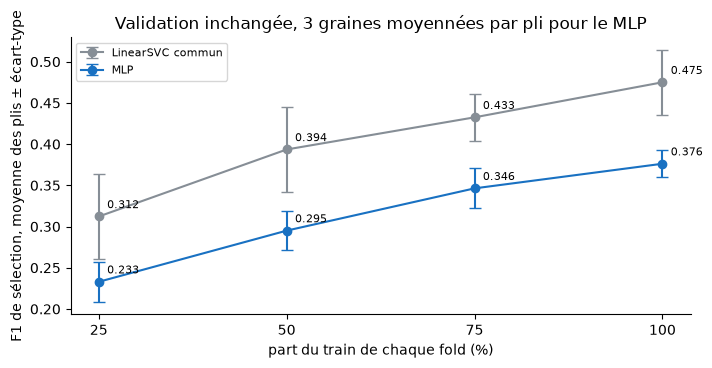

In [76]:
# Courbe d'apprentissage : F1 macro selon la part du train, avec l'écart-type entre folds.
fig, ax = plt.subplots(figsize=(8, 3.6))
for modele, lignes in quantite.groupby('Modèle', sort=False):
    ax.errorbar(lignes['Part du train (%)'], lignes['F1 macro'], yerr=lignes['F1 écart-type'],
                marker='o', capsize=4, color=COULEURS[modele], label=modele)
    for part, f1 in zip(lignes['Part du train (%)'], lignes['F1 macro']):
        ax.annotate(f'{f1:.3f}', (part, f1), textcoords='offset points', xytext=(6, 6), fontsize=8)
ax.set_xticks([100 * part for part in PARTS])
ax.set(xlabel='part du train de chaque fold (%)',
       ylabel='F1 de sélection, moyenne des plis ± écart-type')
ax.set_title('Validation inchangée, 3 graines moyennées par pli pour le MLP')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> LinearSVC passe de 0,312 à 0,475 et le MLP de 0,233 à 0,376. Les écarts valent 0,079, 0,099, 0,087 et 0,099.

Mon hypothèse de rapprochement n’est pas soutenue sur ces fractions. Les deux scores progressent jusqu’au plus grand sous-ensemble testé. Je ne mesure pas ce qui arriverait au-delà de ces données.

Sur le premier pli, les plafonds donnent 2 000, 2 000, 1 995 et 2 000 mises à jour par graine. Aux epochs retenues, les budgets valent 490, 990, 930 et 1 240.

Les sous-ensembles ne sont pas supposés emboîtés, et cette expérience ne neutralise pas les changements de vocabulaire.

Je conserve les essais de dropout à 0,3 et de weight decay à `1e-4`. Leur plafond passe aussi de 100 à 200 epochs, donc la comparaison avec le MLP initial change ce budget.

Le dropout masque des activations pendant l’entraînement et les remet à l’échelle. Ici, Adam ajoute la pénalisation L2 au gradient, sans décroissance découplée de type AdamW.

> *Mon hypothèse :*
>
> Ces variantes réduisent l’écart train/validation de 0,624, mais améliorent peu le F1 de validation.

In [77]:
# Dropout puis weight decay, avec un plafond de 200 epochs pour les deux variantes.
REGLAGES_REGULARISES = dict(REGLAGES_MLP, epochs_max=200)
evaluer_reseau('MLP dropout 0,3', MoyenneMLP, dict(REGLAGES_REGULARISES, dropout=0.3))
evaluer_reseau('MLP weight decay 1e-4', MoyenneMLP, dict(REGLAGES_REGULARISES, weight_decay=1e-4))
REGULARISATION = ['MLP', 'MLP dropout 0,3', 'MLP weight decay 1e-4']
display(pd.DataFrame([ligne_modele(nom) for nom in REGULARISATION]).set_index('Modèle').round(3))
display(pd.DataFrame([resumer_courbe(nom, REGLAGES_MLP) for nom in REGULARISATION])
        .set_index('Modèle').round(3).T)
display(pd.DataFrame([comparer_experience('MLP', variante) for variante in REGULARISATION[1:]])
        .set_index('Variante').round(3))

,Paramètres (fold 1),Epoch retenue,F1 train,F1 macro,Écart-type entre folds,Écart-type entre seeds,Écart train/validation,Temps total (s)
Modèle,,,,,,,,
MLP,135370,62,1.000,0.376,0.016,0.031,0.624,62.422
"MLP dropout 0,3",135370,141,1.000,0.410,0.034,0.027,0.590,186.520
MLP weight decay 1e-4,135370,58,0.995,0.367,0.026,0.037,0.628,142.005


Modèle,MLP,"MLP dropout 0,3",MLP weight decay 1e-4
Epochs,100,200,200
Epoch retenue,62,141,58
Epoch du maximum,80,193,130
F1 validation maximal,0.381,0.413,0.371
Epoch de loss validation minimale,20,34,26
F1 validation à cette epoch,0.3,0.331,0.299
Gain des 10 dernières epochs,-0.002,0.001,0.005
Monte encore,False,False,False


MLP / MLP dropout 0,3 : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,23,43,276,427,0.018657
43,19,51,271,428,0.000166
44,21,51,282,415,0.000535


MLP / MLP weight decay 1e-4 : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,39,37,260,433,0.908777
43,32,35,258,444,0.807195
44,41,28,262,438,0.148032


,F1 base,F1 variante,Écart moyen,Folds en baisse,Epoch variante,F1 train variante,p-value McNemar
Variante,,,,,,,
"MLP dropout 0,3",0.376,0.410,0.034,0,141,1.000,1.9e-02
MLP weight decay 1e-4,0.376,0.367,-0.009,4,58,0.995,9.1e-01


> *Mes observations :*
>
> Le MLP avec dropout atteint 0,410 à l’epoch retenue 141, contre 0,376 à l’epoch 62 sans régularisation. Son écart train/validation passe de 0,624 à 0,590, avec un F1 train arrondi de 1,000.

Le weight decay testé donne 0,367. Le gain du dropout est observé avec un plafond plus long et une sélection sur les mêmes validations. La valeur de McNemar de 0,019 ne teste pas directement ce gain en F1.

Je conserve le MLP avec dropout pour la suite. L’idée qu’il répartit mieux l’information entre dimensions reste une hypothèse, car je n’ai pas mesuré ces représentations.

> *Ma conclusion :*
>
> Les ablations précisent les variations observées, sans attribuer une part fixe du score aux noms ou démontrer l’absence d’usage de l’ordre. L’écart entre MLP et LinearSVC ne diminue pas avec les fractions testées.

Je retiens LinearSVC commun, le MLP avec dropout et le GRU pour la comparaison finale. Le dropout est la seule variante de régularisation essayée qui améliore le F1 de sélection du MLP.

### 4.4 Figer les choix et évaluer sur le test

Je réajuste les configurations retenues sur les 769 répliques de développement. Chaque réseau reconstruit son vocabulaire et repart d’une initialisation pour chaque graine, jusqu’à l’epoch choisie en validation.

Je ne mesure pas le test pendant cet entraînement final. Les 193 répliques restent toutefois celles déjà consultées au TP1. Les résultats et l’analyse des erreurs gardent donc une portée exploratoire.

Je conserve les trois configurations retenues et les deux références prévues. Le majoritaire fournit un repère mesuré. LinearSVC TP1 permet de vérifier la reproduction de ses prédictions, en complément des contrôles directs des données.

In [78]:
# Les cinq modèles figés pour le test : constructeur et, pour un réseau, réglages de validation.
FIGES = {
    'Majoritaire': {'construire': lambda: DummyClassifier(strategy='most_frequent')},
    'LinearSVC TP1': {'construire': partial(construire_svc, 'TP1')},
    'LinearSVC commun': {'construire': partial(construire_svc, 'commun')},
    'MLP dropout 0,3': {'construire': MoyenneMLP,
                        'reglages': dict(REGLAGES_REGULARISES, dropout=0.3)},
    'GRU': {'construire': GRU, 'reglages': REGLAGES},
}

# Bilan de validation des modèles figés, puis taille d'une epoch sur les 769 répliques
display(pd.DataFrame([ligne_bilan(nom) for nom in FIGES]).set_index('Modèle')
        .astype({'Epoch retenue': 'Int64', 'Paramètres (fold 1)': 'Int64'}).round(3))
batches_fold = math.ceil(len(folds[0]['train']) / REGLAGES['taille_batch'])
batches_final = math.ceil(len(X_train) / REGLAGES['taille_batch'])
print(f'Une epoch compte {batches_final} batches sur les 769 répliques, contre {batches_fold} '
      f'dans un fold, soit {pourcentage(batches_final - batches_fold, batches_fold):.0f} % '
      f'de mises à jour en plus')

,Famille,F1 train,F1 macro,F1 écart-type,Accuracy,Accuracy écart-type,Epoch retenue,Paramètres (fold 1),Temps total (s)
Modèle,,,,,,,,,
Majoritaire,ML,0.024,0.024,0.001,0.134,0.003,<NA>,<NA>,0.024
LinearSVC TP1,ML,1.000,0.482,0.039,0.492,0.041,<NA>,48620,0.389
LinearSVC commun,ML,1.000,0.475,0.039,0.484,0.038,<NA>,50260,0.308
"MLP dropout 0,3",DL,1.000,0.410,0.034,0.422,0.036,141,135370,186.520
GRU,DL,1.000,0.206,0.027,0.213,0.026,31,156170,472.251


Une epoch compte 25 batches sur les 769 répliques, contre 20 dans un fold, soit 25 % de mises à jour en plus


Le MLP retenu atteint 0,410 en validation à l’epoch 141 et le GRU 0,206 à l’epoch 31. Une epoch finale compte 25 batches contre 20 dans un pli.

Je conserve ce budget, soit 25 % de mises à jour supplémentaires par epoch. L’évaluation du train pendant la validation croisée parcourt aussi son chargeur mélangé, contrairement à la boucle finale. Une graine identique ne reproduit donc pas sa séquence de batches.

Pour le bootstrap, je rééchantillonne 1 000 fois les 193 répliques avec remise et garde les percentiles 2,5 et 97,5. Les tirages sont communs aux modèles et aux graines. Ils décrivent la variation du F1 moyen à prédictions fixées, sans réentraîner les modèles.

In [79]:
# Outils du test : réentraînement sur les 769 répliques, une seule prédiction du test, intervalles.
resultats_test = {}  # nom -> prédictions du test par seed et temps
TIRAGES_BOOTSTRAP = 1000


def entrainer_final(construire_modele, reglages: dict, epochs: int, seed: int) -> pd.Series:
    """Réseau neuf entraîné sur les 769 répliques pendant `epochs`, puis une prédiction du test."""
    fixer_seed(seed)
    vocabulaire = construire_vocabulaire(X_train)
    longueur_max = longueur_maximale(X_train, reglages['quantile_longueur'])
    train = construire_chargeur(JeuRepliques(X_train, y_train, vocabulaire, longueur_max),
                                reglages, True, seed)
    test = construire_chargeur(JeuRepliques(X_test, y_test, vocabulaire, longueur_max),
                               reglages, False, seed)
    modele = construire_modele(len(vocabulaire), reglages).to(reglages['device'])
    optimiseur = torch.optim.Adam(modele.parameters(), lr=reglages['taux_apprentissage'],
                                  weight_decay=reglages['weight_decay'])
    for _ in range(epochs):  # Aucune mesure sur le test pendant l'entraînement
        entrainer_epoch(modele, train, optimiseur, reglages)
    predictions = evaluer_modele(modele, test, reglages['device'])['predictions']
    return pd.Series([CLASSES[indice] for indice in predictions], index=X_test.index)


def evaluer_test(nom: str) -> None:
    """Réajuste un modèle figé sur les 769 répliques et garde ses prédictions du test par seed."""
    choix, debut = FIGES[nom], time.perf_counter()
    if 'reglages' in choix:
        epoch = resultats[nom]['epoch']  # Epoch retenue en validation croisée
        jeux = [entrainer_final(choix['construire'], choix['reglages'], epoch, seed)
                for seed in choix['reglages']['seeds']]
    else:
        pipeline = choix['construire']().fit(X_train, y_train)
        jeux = [pd.Series(pipeline.predict(X_test), index=X_test.index)]
    resultats_test[nom] = {'predictions': jeux, 'temps': time.perf_counter() - debut}


def jeux_test(nom: str) -> list:
    """Prédictions du test d'un modèle figé, une série par seed."""
    return resultats_test[nom]['predictions']


def intervalle_bootstrap(jeux: list, vrais: pd.Series) -> tuple:
    """Intervalle à 95 % du F1 macro moyen des seeds, mêmes tirages pour tous les modèles."""
    generateur = np.random.default_rng(RANDOM_STATE)
    tirages = generateur.integers(0, len(vrais), (TIRAGES_BOOTSTRAP, len(vrais)))
    valeurs = [np.mean([f1_score(vrais.iloc[t], jeu.iloc[t], average='macro', zero_division=0)
                        for jeu in jeux]) for t in tirages]
    return tuple(np.percentile(valeurs, [2.5, 97.5]))

Je réajuste les cinq configurations figées et calcule leurs prédictions du test. Une série de prédictions est produite par graine pour les réseaux. Je ne relance pas de choix de réglage à partir de ces résultats.

In [80]:
# Les cinq modèles figés sur les 193 répliques de test, face à leur validation.


def ligne_test(nom: str) -> dict:
    """F1 macro et accuracy du test, écart entre seeds, intervalle et F1 de validation."""
    jeux = jeux_test(nom)
    f1 = [f1_score(y_test, jeu, average='macro', zero_division=0) for jeu in jeux]
    bas, haut = intervalle_bootstrap(jeux, y_test)
    return {'Modèle': nom, 'Epoch': resultats[nom].get('epoch'),
            'F1 validation': ligne_bilan(nom)['F1 macro'], 'F1 test': np.mean(f1),
            'Écart-type entre seeds': np.std(f1, ddof=1) if len(f1) > 1 else np.nan,
            'Intervalle 95 % bas': bas, 'Intervalle 95 % haut': haut,
            'Accuracy test': np.mean([accuracy_score(y_test, jeu) for jeu in jeux]),
            'Temps (s)': resultats_test[nom]['temps']}


for nom in FIGES:
    evaluer_test(nom)
bilan_test = pd.DataFrame([ligne_test(nom) for nom in FIGES]).set_index('Modèle')
display(bilan_test.astype({'Epoch': 'Int64'}).round(3))

,Epoch,F1 validation,F1 test,Écart-type entre seeds,Intervalle 95 % bas,Intervalle 95 % haut,Accuracy test,Temps (s)
Modèle,,,,,,,,
Majoritaire,<NA>,0.024,0.024,NaN,0.016,0.031,0.135,0.001
LinearSVC TP1,<NA>,0.482,0.563,NaN,0.487,0.624,0.565,0.058
LinearSVC commun,<NA>,0.475,0.505,NaN,0.422,0.565,0.508,0.052
"MLP dropout 0,3",141,0.410,0.416,0.014,0.346,0.471,0.421,25.797
GRU,31,0.206,0.207,0.012,0.165,0.241,0.211,85.591


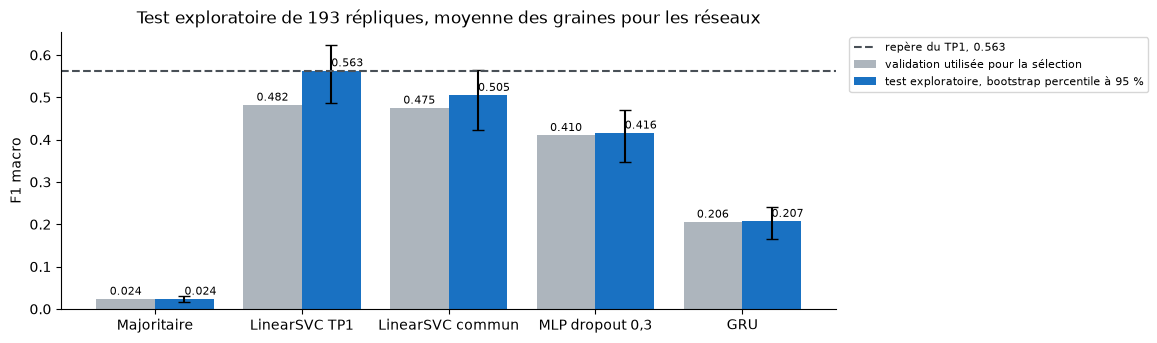

In [81]:
# F1 macro de validation et de test, avec l'intervalle à 95 % du test et le repère du TP1.
REPERE_TP1 = 0.563  # F1 macro de LinearSVC sur ce test au TP1
positions = np.arange(len(bilan_test))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(positions - 0.2, bilan_test['F1 validation'], 0.4, color='#adb5bd',
       label='validation utilisée pour la sélection')
erreurs = [bilan_test['F1 test'] - bilan_test['Intervalle 95 % bas'],
           bilan_test['Intervalle 95 % haut'] - bilan_test['F1 test']]
ax.bar(positions + 0.2, bilan_test['F1 test'], 0.4, yerr=erreurs, capsize=4, color='#1971c2',
       label='test exploratoire, bootstrap percentile à 95 %')
valeurs = zip(bilan_test['F1 validation'], bilan_test['F1 test'])
for position, (validation, test) in enumerate(valeurs):
    ax.text(position - 0.2, validation + 0.01, f'{validation:.3f}', ha='center', fontsize=8)
    ax.text(position + 0.2, test + 0.01, f'{test:.3f}', ha='left', fontsize=8)
ax.axhline(REPERE_TP1, linestyle='--', color='#495057', label=f'repère du TP1, {REPERE_TP1}')
ax.set_xticks(positions, bilan_test.index)
ax.set_ylabel('F1 macro')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('Test exploratoire de 193 répliques, moyenne des graines pour les réseaux')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> LinearSVC TP1 retrouve 0,563 de F1. LinearSVC commun atteint 0,505, le MLP retenu 0,416 et le GRU 0,207.

Les intervalles bootstrap de LinearSVC commun et du MLP vont de 0,422 à 0,565 et de 0,346 à 0,471. Leur recouvrement ne teste pas l’écart entre les modèles.

Ces intervalles conditionnent sur les prédictions et traitent les répliques comme unités de rééchantillonnage. Ils ne corrigent ni la consultation antérieure du test ni les dépendances possibles entre scènes. L’absence de baisse globale depuis la validation ne prouve pas l’absence de surajustement de mes choix.

Comme dans la section 4.1, je compte les répliques de test où un seul des deux modèles a raison, puis je teste ce déséquilibre avec McNemar.

In [82]:
# Répliques de test où un seul des deux modèles a raison, puis test de McNemar exact.
PAIRES_TEST = [('LinearSVC commun', 'MLP dropout 0,3'), ('LinearSVC commun', 'GRU'),
               ('MLP dropout 0,3', 'GRU')]
display(pd.DataFrame([comparer_paire(a, b, jeux_test, y_test) for a, b in PAIRES_TEST])
        .set_index(['A', 'B']).round(1))

LinearSVC commun / MLP dropout 0,3 : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,27,14,71,81,0.059584
43,37,18,61,77,0.014454
44,35,17,63,78,0.017533


LinearSVC commun / GRU : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,74,19,24,76,7.720918e-09
43,74,14,24,81,5.089194e-11
44,74,17,24,78,1.193408e-09


MLP dropout 0,3 / GRU : discordances par graine, sans correction de multiplicité


,A seul juste,B seul juste,Deux justes,Deux faux,p_value
Graine,,,,,
42,59,17,26,91,0.000001
43,61,20,18,94,0.000006
44,60,21,20,92,0.000017


A seul juste  B seul juste  Deux justes  \
A                B                                                          
LinearSVC commun MLP dropout 0,3          33.0          16.3         65.0   
                 GRU                      74.0          16.7         24.0   
MLP dropout 0,3  GRU                      60.0          19.3         21.3   

                                  Deux faux p-value maximale  
A                B                                            
LinearSVC commun MLP dropout 0,3       78.7          6.0e-02  
                 GRU                   78.3          7.7e-09  
MLP dropout 0,3  GRU                   92.3          1.7e-05

> *Mes observations :*
>
> LinearSVC commun a seul raison sur 33,0 répliques en moyenne, contre 16,3 pour le MLP retenu. La valeur maximale de McNemar parmi les trois comparaisons vaut 0,060.

Les valeurs arrondies sont 0,060, 0,014 et 0,018 pour les graines 42, 43 et 44. Au seuil nominal de 5 %, les décisions diffèrent donc selon la graine. Ces comparaisons non corrigées ne constituent pas un test global de différence de F1.

Les valeurs face au GRU sont plus faibles, avec les mêmes limites exploratoires. Je ne peux pas attribuer l’écart de test au seul dropout sans le MLP non régularisé dans cette comparaison finale.

Je compare ensuite le F1 de chaque locuteur entre validation et test. Une classe de test ne compte que 16 à 26 répliques, donc un écart par classe reste fragile.

In [83]:
# F1 de chaque locuteur sur le test, à côté de la validation, pour les trois modèles figés.
FIGES_ANALYSE = ['LinearSVC commun', 'MLP dropout 0,3', 'GRU']
f1_classes_test = pd.concat({nom: pd.DataFrame({
    'Validation': metriques_par_classe(nom)['F1'],
    'Test': metriques_par_classe(nom, jeux_test, y_test)['F1']}) for nom in FIGES_ANALYSE}, axis=1)
f1_classes_test['Support test'] = y_test.value_counts().reindex(CLASSES)
display(f1_classes_test.round(3))

LinearSVC commun        MLP dropout 0,3               GRU  \
                      Validation   Test      Validation   Test Validation   
CORIOLANUS                 0.438  0.645           0.393  0.517      0.253   
DUKE VINCENTIO             0.520  0.557           0.536  0.424      0.259   
GLOUCESTER                 0.495  0.577           0.398  0.480      0.189   
ISABELLA                   0.491  0.516           0.353  0.206      0.147   
JULIET                     0.378  0.353           0.298  0.435      0.203   
KING RICHARD II            0.533  0.429           0.455  0.464      0.192   
LEONTES                    0.389  0.643           0.285  0.398      0.104   
MENENIUS                   0.487  0.571           0.510  0.433      0.288   
PETRUCHIO                  0.650  0.350           0.539  0.450      0.246   
ROMEO                      0.392  0.410           0.364  0.354      0.201   

                       Support test  
                  Test               
CORIOLANUS       0.164           17  
DUKE VINCENTIO   0.228           25  
GLOUCESTER       0.171           26  
ISABELLA         0.143           16  
JULIET           0.339           17  
KING RICHARD II  0.086           16  
LEONTES          0.256           16  
MENENIUS         0.248           22  
PETRUCHIO        0.165           19  
ROMEO            0.274           19

> *Mes observations :*
>
> Les classes du test comptent de 16 à 26 répliques. Pour LinearSVC commun, PETRUCHIO passe de 0,650 en validation regroupée à 0,350 sur le test, tandis que LEONTES passe de 0,389 à 0,643.

Le MLP baisse sur ISABELLA et progresse sur CORIOLANUS. Je garde ces résultats par classe sans attribuer leurs variations à un nom particulier. Les modèles, les répliques et les tailles d’entraînement diffèrent aussi entre validation et test.

Je reprends les matrices de confusion sur le test exploratoire. Les effectifs des réseaux cumulent trois prédictions par réplique, alors que ceux de LinearSVC en comptent une. Les pourcentages restent calculés par locuteur réel sur la même échelle.

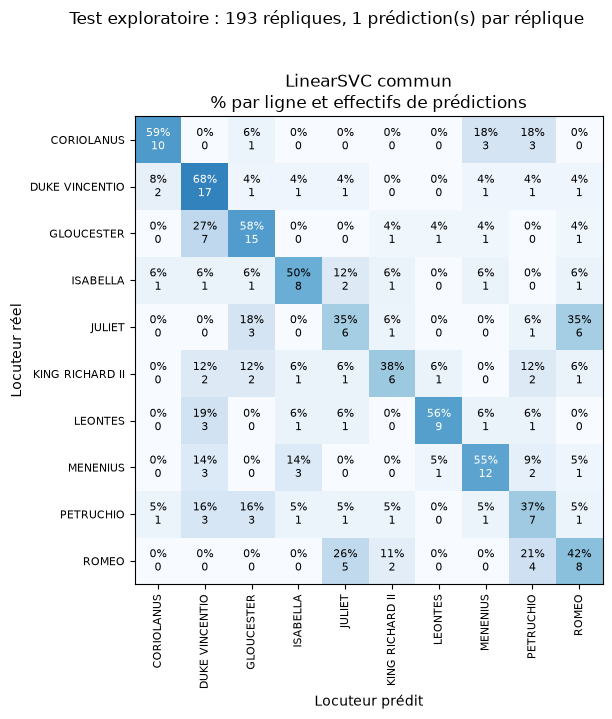

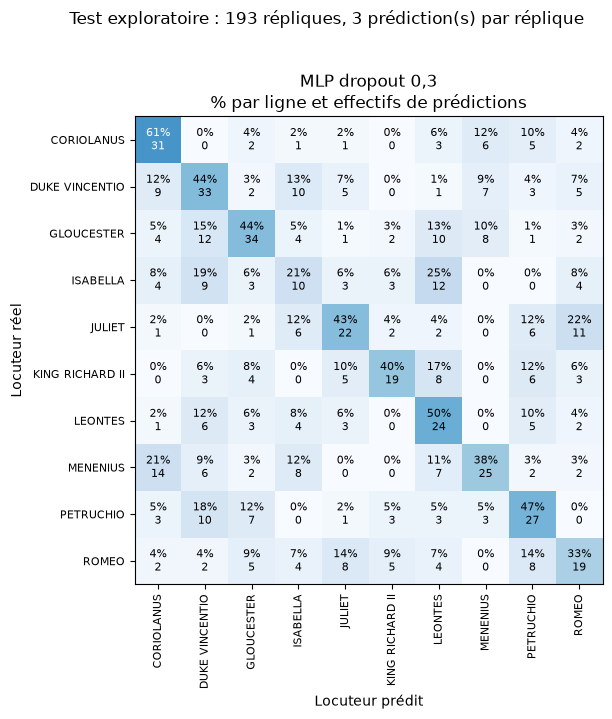

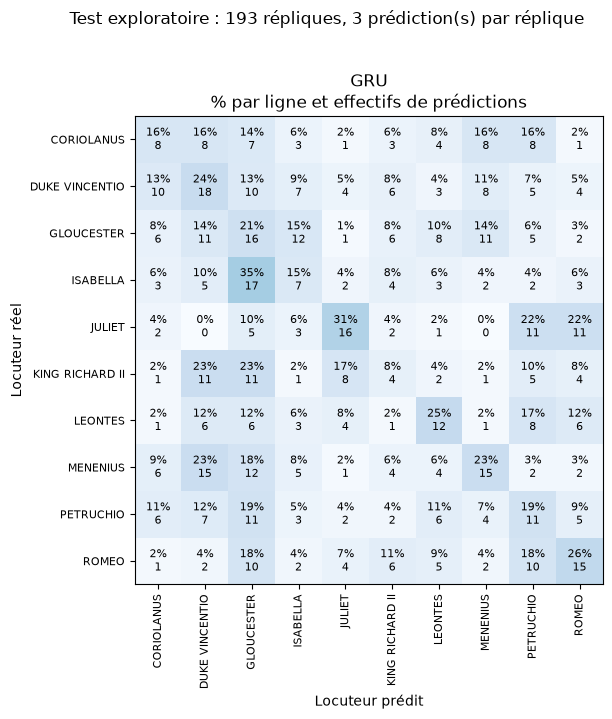

In [84]:
# Matrices de confusion du test pour les trois modèles figés, en % de chaque locuteur réel.
matrices_test = {nom: matrice_confusion(nom, jeux_test, y_test) for nom in FIGES_ANALYSE}
for nom, matrice in matrices_test.items():
    fig, axe = plt.subplots(figsize=(8, 7))
    tracer_matrice(axe, nom, matrice)
    repetitions = len(jeux_test(nom))
    fig.suptitle(f'Test exploratoire : 193 répliques, {repetitions} prédiction(s) par réplique',
                 y=1.02)
    plt.tight_layout()
    plt.show()

In [85]:
# Plus fortes confusions du test et couples suivis depuis le TP1, seeds sommées pour les réseaux.
decrire_confusions(matrices_test)

LinearSVC commun : rappel moyen 49.7 %
   plus fortes confusions
      JULIET → ROMEO : 35.3 % (6 sur 17)
      GLOUCESTER → DUKE VINCENTIO : 26.9 % (7 sur 26)
      ROMEO → JULIET : 26.3 % (5 sur 19)
   couples suivis depuis le TP1
      JULIET → ROMEO : 35.3 % (6 sur 17)
      ROMEO → JULIET : 26.3 % (5 sur 19)
      GLOUCESTER → DUKE VINCENTIO : 26.9 % (7 sur 26)
      DUKE VINCENTIO → GLOUCESTER : 4.0 % (1 sur 25)
MLP dropout 0,3 : rappel moyen 42.1 %
   plus fortes confusions
      ISABELLA → LEONTES : 25.0 % (12 sur 48)
      JULIET → ROMEO : 21.6 % (11 sur 51)
      MENENIUS → CORIOLANUS : 21.2 % (14 sur 66)
   couples suivis depuis le TP1
      JULIET → ROMEO : 21.6 % (11 sur 51)
      ROMEO → JULIET : 14.0 % (8 sur 57)
      GLOUCESTER → DUKE VINCENTIO : 15.4 % (12 sur 78)
      DUKE VINCENTIO → GLOUCESTER : 2.7 % (2 sur 75)
GRU : rappel moyen 20.8 %
   plus fortes confusions
      ISABELLA → GLOUCESTER : 35.4 % (17 sur 48)
      KING RICHARD II → DUKE VINCENTIO : 22.9 % (11 s

> *Mes observations :*
>
> Pour LinearSVC commun, JULIET se partage entre JULIET et ROMEO à 35,3 % chacun. GLOUCESTER est prédite DUKE VINCENTIO dans sept cas sur 26, soit 26,9 %.

Le MLP retenu confond notamment ISABELLA vers LEONTES à 25,0 %, avec douze prédictions sur 48 cumulées. Le GRU prédit GLOUCESTER pour ISABELLA dans 35,4 % de ses prédictions cumulées.

Je distingue ces répétitions des répliques distinctes. Pour LinearSVC, une seule réplique change une case d’environ quatre à six points selon la classe. Les matrices décrivent les erreurs, sans établir leurs causes.

Je décris les mêmes facteurs sur le test, avec des listes ajustées sur les 769 répliques de développement. Les 193 répliques du test sont exclues de l’entraînement des modèles. Elles ne sont pourtant pas nouvelles dans ma démarche, puisque le TP1 les a déjà utilisées pour l’analyse.

In [86]:
# Facteurs des répliques de test, listes ajustées sur les 769 répliques, puis groupes et pièces.
facteurs_test = facteurs_fold({'train': X_train.index, 'validation': X_test.index}, X_test)
facteurs_test['Nom'] = facteurs_test['Noms'].str.len() > 0
print(f'Répliques de test avec au moins un nom : '
      f'{pourcentage(facteurs_test["Nom"].sum(), len(facteurs_test)):.1f} %')

# Quatre groupes selon LinearSVC commun et le MLP figé, moyennés sur les seeds du MLP
svc_test = jeux_test('LinearSVC commun')[0]
tables_test = [facteurs_par_groupe(jeu, svc_test, y_test, facteurs_test)
               for jeu in jeux_test('MLP dropout 0,3')]
display(pd.concat(tables_test).groupby(level=0).mean().reindex(ORDRE_GROUPES).round(1))

# Erreurs du test qui restent dans la pièce, face au hasard
display(pd.DataFrame([part_intra(nom, jeux_test, y_test) for nom in FIGES_ANALYSE])
        .set_index('Modèle').round(2))

Répliques de test avec au moins un nom : 32.6 %


,Répliques,Longueur,Avec un nom (%),Inconnus (%),Partagés (%)
Groupe,,,,,
Deux justes,65.0,58.6,50.4,12.0,56.5
LinearSVC seul juste,33.0,41.3,31.4,12.3,56.2
MLP seul juste,16.3,52.7,45.6,11.6,56.4
Deux faux,78.7,38.5,16.1,12.2,57.6


,Erreurs,Dans la pièce (%),Hasard (%),Rapport au hasard
Modèle,,,,
LinearSVC commun,95.00,20.00,8.42,2.38
"MLP dropout 0,3",111.67,20.60,9.64,2.14
GRU,152.33,10.05,9.00,1.12


> *Mes observations :*
>
> Un nom détecté apparaît dans 32,6 % des répliques du test. Les succès communs en contiennent dans 50,4 % des cas, contre 16,1 % des erreurs communes.

Les groupes ont aussi des longueurs différentes. Les erreurs dans le groupe reconstruit représentent 20,0 % pour LinearSVC et 20,6 % pour le MLP, contre leurs repères de 8,42 % et 9,64 %.

Ces associations prolongent certaines observations de validation. Je ne les présente pas comme des explications causales. Le MLP est désormais régularisé et les répliques ont changé, donc leur comparaison ne mesure pas l’effet du seul dropout.

> *Ma conclusion :*
>
> L’ordre des trois configurations au tokenizer commun se retrouve sur ce test, avec 0,505, 0,416 et 0,207 de F1. La référence LinearSVC TP1 reste devant à 0,563.

Les scores sont des observations sur ce sous-corpus et ce protocole de sélection. Les intervalles et les désaccords précisent leur interprétation, sans rendre le test indépendant après sa consultation au TP1.

### 4.5 Mon journal d’expériences

Je garde les attentes de départ et les décisions prises après chaque expérience. Les résultats de sélection ne constituent pas des validations indépendantes des hypothèses.

Prétraitement et MLP :

| Essai | Attente initiale | Observation | Décision et limite |
|---|---|---|---|
| 1. Tokenizer | « I » et les contractions aident LinearSVC | 0,475 contre 0,482, un pli gagné | Garder le tokenizer commun pour partager les unités, sans gain observé. |
| 2. Plafond MLP | 40 epochs suffisent | Gain final de 0,020 à 40, puis −0,002 à 100 | Garder 100 selon la règle, sans preuve de convergence. |
| 3. MLP, H1 et H3 | Écart sous 0,05 et ajustement avant 20 epochs | Écart de 0,099, seuil atteint entre 41 et 49 | H1 non soutenue et délai de H3 contredit pour le MLP. |
| 4. Largeur | La largeur change peu le F1 | 0,387, 0,376 et 0,378 | Garder 64, sans équivalence démontrée. |

Récurrence et diagnostics :

| Essai | Attente initiale | Observation | Décision et limite |
|---|---|---|---|
| 5. LSTM | L’ordre le fait dépasser le MLP | Retard de 0,170, seuil train entre 21 et 26 | L’avantage attendu manque, sans cause unique identifiée. |
| 6. Gradients | Le plafonnement intervient surtout en récurrence | 51,2 % de batches pour LSTM contre 1,2 % pour MLP | Garder le seuil, sans mesurer son effet sur les scores. |
| 7. GRU, H4 | Moins de paramètres, plus rapide, score proche | 156 170 contre 164 490 paramètres, écart moyen −0,001 | Garder le GRU, avec proximité descriptive des scores et temps locaux. |
| 8. Pièce ou style | Les erreurs restent davantage dans la pièce | 18,6 % contre 9,1 % pour LinearSVC | Association avec des groupes heuristiques, sans preuve de reconnaissance de pièce. |
| 9. Facteurs | Noms et longueur accompagnent les erreurs | Noms dans 45,8 % des succès communs contre 14,7 % des erreurs communes | Motiver une ablation, sans causalité établie. |

Interventions et comparaison finale :

| Essai | Attente initiale | Observation | Décision et limite |
|---|---|---|---|
| 10. Noms retirés | LinearSVC perd davantage, surtout PETRUCHIO | Baisses de 0,054 et 0,051, PETRUCHIO −0,127 pour LinearSVC | Baisse par classe observée, sans décomposition du score par nom. |
| 11. Mélange, H2 | Le GRU et les bigrammes baissent | −0,007 et −0,030, MLP +0,001, unigrammes inchangés | Faible sensibilité observée du GRU, sans preuve d’absence d’usage de l’ordre. |
| 12. Quantité | Le MLP se rapproche de LinearSVC | Écarts de 0,079, 0,099, 0,087 et 0,099 | Rapprochement non observé dans les fractions testées. |
| 13. Régularisation | Réduire l’écart avec peu de gain de F1 | Dropout 0,410 et écart 0,590, weight decay 0,367 | Garder le dropout avec son plafond de 200, sans isoler ce changement de budget. |
| 14. Test | Retrouver l’ordre des choix figés | TP1 0,563, commun 0,505, MLP 0,416, GRU 0,207 | Ordre observé sur le test déjà consulté, sans conclusion globale de significativité. |

### 4.6 Ce que je peux conclure

Je rassemble les trois configurations retenues au tokenizer commun pour lire score et temps ensemble. Je garde à part le statut de LinearSVC TP1, qui a les meilleurs scores observés.

Le temps de validation cumule les entraînements et leurs évaluations pour la configuration indiquée. Il ne comprend pas toutes les variantes explorées et ne mesure pas la latence d’une prédiction.

Le chronomètre inclut la vectorisation et l’ajustement des pipelines ML. Pour les réseaux, il démarre après la préparation des données et la construction du modèle.

,F1 validation,Écart-type validation,F1 test,Intervalle 95 % bas,Intervalle 95 % haut,Paramètres (fold 1),Temps de validation (s)
Modèle,,,,,,,
LinearSVC commun,0.475,0.039,0.505,0.422,0.565,50260,0.308
"MLP dropout 0,3",0.410,0.034,0.416,0.346,0.471,135370,186.520
GRU,0.206,0.027,0.207,0.165,0.241,156170,472.251


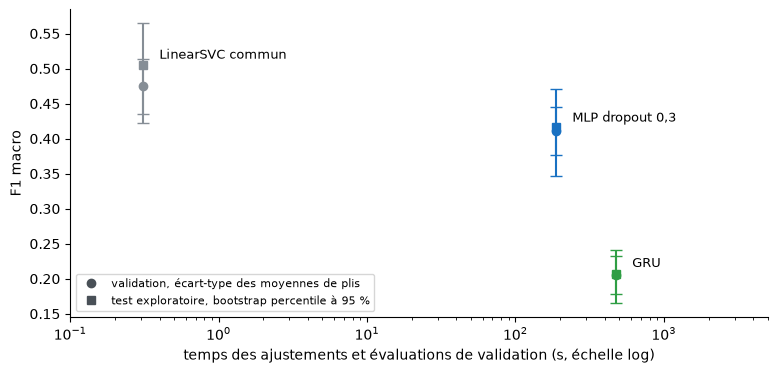

In [87]:
# Synthèse des trois choix figés : F1 macro de validation et de test face au temps d'entraînement.
SYNTHESE = {'LinearSVC commun': COULEURS['LinearSVC commun'], 'MLP dropout 0,3': COULEURS['MLP'],
            'GRU': COULEURS['GRU']}


def ligne_synthese(nom: str) -> dict:
    """F1 de validation et de test, intervalle du test, taille et temps total de validation."""
    bilan, test = ligne_bilan(nom), bilan_test.loc[nom]
    return {'Modèle': nom, 'F1 validation': bilan['F1 macro'],
            'Écart-type validation': bilan['F1 écart-type'], 'F1 test': test['F1 test'],
            'Intervalle 95 % bas': test['Intervalle 95 % bas'],
            'Intervalle 95 % haut': test['Intervalle 95 % haut'],
            'Paramètres (fold 1)': bilan['Paramètres (fold 1)'],
            'Temps de validation (s)': bilan['Temps total (s)']}


synthese = pd.DataFrame([ligne_synthese(nom) for nom in SYNTHESE]).set_index('Modèle')
display(synthese.astype({'Paramètres (fold 1)': 'Int64'}).round(3))

# Validation en rond avec un écart-type, test en carré avec l'intervalle à 95 %
fig, ax = plt.subplots(figsize=(9, 4))
for nom, ligne in synthese.iterrows():
    temps, couleur = ligne['Temps de validation (s)'], SYNTHESE[nom]
    ax.errorbar(temps, ligne['F1 validation'], yerr=ligne['Écart-type validation'], fmt='o',
                color=couleur, capsize=4)
    bas = ligne['F1 test'] - ligne['Intervalle 95 % bas']
    haut = ligne['Intervalle 95 % haut'] - ligne['F1 test']
    ax.errorbar(temps, ligne['F1 test'], yerr=[[bas], [haut]], fmt='s', color=couleur,
                capsize=4)
    ax.annotate(nom, (temps, ligne['F1 test']), textcoords='offset points',
                xytext=(12, 7), va='center', fontsize=9)
ax.plot([], [], 'o', color='#495057', label='validation, écart-type des moyennes de plis')
ax.plot([], [], 's', color='#495057', label='test exploratoire, bootstrap percentile à 95 %')
ax.set_xscale('log')
ax.set_xlim(0.1, 5000)
ax.set(xlabel="temps des ajustements et évaluations de validation (s, échelle log)",
       ylabel='F1 macro')
ax.legend(fontsize=8, loc='lower left')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Parmi les configurations au tokenizer commun, LinearSVC a les meilleurs F1 observés, soit 0,475 en validation et 0,505 sur le test. Les durées de la table concernent cinq ajustements ML ou quinze entraînements neuronaux.

Les points de validation et de test partagent la même abscisse, car je leur associe le coût de sélection indiqué. Ce coût n’est pas celui de l’évaluation du test. Les barres de validation montrent la dispersion des moyennes de plis. Celles du test montrent les intervalles bootstrap conditionnels aux prédictions.

Je prédis une étiquette de locuteur à partir d’une réplique isolée. Les ablations montrent une baisse après retrait des noms détectés, mais ne séparent pas style, thème et identité.

LinearSVC pondère des unigrammes et des bigrammes. Le MLP apprend une moyenne d’embeddings suivie d’une couche cachée, tandis que les réseaux récurrents construisent un état final. Les essais ne montrent pas d’avantage des récurrents avec les réglages retenus.

Les validations portent sur des répliques mises à l’écart de l’ajustement de chaque pli, avec des entraînements qui se recouvrent. Le test partage aussi le corpus et les scènes possibles avec le développement. Je ne mesure pas une généralisation à une pièce inconnue.

Je conserve le F1 macro pour donner le même poids à chaque classe, accompagné de l’accuracy et des erreurs. Les dispersions, McNemar et le bootstrap répondent à des questions différentes. Aucun de ces résumés ne corrige toute la sélection effectuée.

Je retiens LinearSVC comme choix pratique dans les configurations testées. Sa version TP1 obtient 0,482 en validation et 0,563 sur le test, contre 0,475 et 0,505 pour le tokenizer commun.

Le meilleur réseau essayé est le MLP avec dropout, à 0,410 et 0,416. Ces résultats ne condamnent pas le deep learning en général. Ils justifient ici le choix d’une méthode lexicale avec ce corpus et ces essais.

Bilan des hypothèses initiales :

| Hypothèse | Ce que les essais permettent de dire |
|---|---|
| H1, indices lexicaux | L’écart moyen dépasse 0,05. Le raisonnement initial ignorait que LinearSVC utilise des bigrammes. |
| H2, ordre | L’avantage récurrent attendu manque et la baisse du GRU après mélange est faible. L’absence d’usage de l’ordre n’est pas démontrée. |
| H3, mémorisation | Les grands écarts train/validation apparaissent. Le délai strict avant 20 epochs échoue pour le MLP et le LSTM, et n’est satisfait que par un des quinze runs GRU. |
| H4, coût | Le GRU a moins de paramètres. Les scores sont proches, sans équivalence démontrée, et les temps restent des mesures locales. |

Je garde ces limites pour la suite. Les groupes reconstruits ne remplacent pas une annotation des pièces, et les noms détectés ne couvrent pas tous les indices possibles.

La sélection des epochs et des variantes réutilise les mêmes validations. Le test a déjà contribué aux questions du TP1. Ces résultats ne constituent donc pas une mesure indépendante de toute ma démarche de sélection.

> *Ma conclusion :*
>
> Cette comparaison me conduit à vérifier le traitement réel du texte avant d’interpréter un score. Je distingue désormais une association dans les erreurs d’une contribution calculée à une prédiction.

Je regarde aussi ce que chaque expérience change avec son réglage annoncé, dont le vocabulaire, la troncature et le budget. Pour annoncer un gain, je précise l’agrégation et les données déjà utilisées pour choisir. Ces précautions rendent mes conclusions plus limitées, mais vérifiables.

### Pour aller plus loin

Je garde ces pistes comme des questions, sans leur attribuer un gain déjà démontré.

- Comparer un encodeur préentraîné permettrait de tester l’apport de données supplémentaires, avec un protocole adapté.
- Une représentation en caractères pourrait réduire certaines pertes liées au vocabulaire de mots, avec d’autres coûts à mesurer.
- Ajouter les répliques voisines testerait l’intérêt du contexte, absent des modèles actuels.
- Une séparation par groupes annotés demanderait de vérifier les classes présentes de chaque côté. Des locuteurs exclus du train changeraient aussi la tâche de classification.